# Question 2: Stock Price Prediction using Recursive Architectures

This notebook implements stock price prediction for S&P500 using various machine learning and deep learning architectures.


In [1]:
# ============================================================================
# SECTION: Setup - Library Installation
# ============================================================================
# Install required libraries
%pip install yfinance statsmodels -q


In [2]:
# ============================================================================
# SECTION: Setup - Library Imports
# ============================================================================
# Import necessary libraries
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Statsmodels for time series analysis
from statsmodels.tsa.stattools import acf, pacf, adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")


## Section 1-1-2: Data Preprocessing


In [3]:
# ============================================================================
# SECTION 1-1-2: Data Preprocessing - Load Dataset
# ============================================================================
# Load the dataset
print("Downloading S&P500 data from 2000-01-01...")
df = yf.download("^GSPC", start="2000-01-01", auto_adjust=False)
print(f"\nData shape: {df.shape}")
print(f"\nFirst few rows:")
df.head()


[*********************100%***********************]  1 of 1 completed


Data shape: (6536, 6)

First few rows:


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,,
2000-01-03,1455.219971,1455.219971,1478.000000,1438.359985,1469.250000,931800000
2000-01-04,1399.420044,1399.420044,1455.219971,1397.430054,1455.219971,1009000000
2000-01-05,1402.109985,1402.109985,1413.270020,1377.680054,1399.420044,1085500000
2000-01-06,1403.449951,1403.449951,1411.900024,1392.099976,1402.109985,1092300000
2000-01-07,1441.469971,1441.469971,1441.469971,1400.729980,1403.449951,1225200000


In [4]:
# ============================================================================
# SECTION 1-1-2: Data Preprocessing - Report Features
# ============================================================================
# Report existing features
print("Existing features in the dataset:")
print(df.columns.tolist())
print(f"\nData types:")
print(df.dtypes)
print(f"\nData info:")
df.info()


Existing features in the dataset:
[('Adj Close', '^GSPC'), ('Close', '^GSPC'), ('High', '^GSPC'), ('Low', '^GSPC'), ('Open', '^GSPC'), ('Volume', '^GSPC')]

Data types:
Price      Ticker
Adj Close  ^GSPC     float64
Close      ^GSPC     float64
High       ^GSPC     float64
Low        ^GSPC     float64
Open       ^GSPC     float64
Volume     ^GSPC       int64
dtype: object

Data info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 6536 entries, 2000-01-03 to 2025-12-26
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   (Adj Close, ^GSPC)  6536 non-null   float64
 1   (Close, ^GSPC)      6536 non-null   float64
 2   (High, ^GSPC)       6536 non-null   float64
 3   (Low, ^GSPC)        6536 non-null   float64
 4   (Open, ^GSPC)       6536 non-null   float64
 5   (Volume, ^GSPC)     6536 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 357.4 KB


In [5]:
# ============================================================================
# SECTION 1-1-2: Data Preprocessing - Convert Day/Month to Sinusoidal/Cosinusoidal
# ============================================================================
# Feature Engineering: Convert day and month to cyclical representations
df = df.reset_index()
df['Date'] = pd.to_datetime(df['Date'])

# Extract temporal features
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['day'] = df['Date'].dt.day
df['day_of_week'] = df['Date'].dt.dayofweek

# Convert day and month to cyclical features using sine and cosine
df['day_sin'] = np.sin(2 * np.pi * df['day'] / 31)  # Assuming max 31 days
df['day_cos'] = np.cos(2 * np.pi * df['day'] / 31)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

print("Feature engineering completed!")
print(f"\nNew features added: day_sin, day_cos, month_sin, month_cos")
print(f"\nTotal features: {len(df.columns)}")
df.head()


Feature engineering completed!

New features added: day_sin, day_cos, month_sin, month_cos

Total features: 15


Price,Date,Adj Close,Close,High,Low,Open,Volume,year,month,day,day_of_week,day_sin,day_cos,month_sin,month_cos
Ticker,,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,,,,,,,,
0,2000-01-03,1455.219971,1455.219971,1478.000000,1438.359985,1469.250000,931800000,2000,1,3,0,0.571268,0.820763,0.5,0.866025
1,2000-01-04,1399.420044,1399.420044,1455.219971,1397.430054,1455.219971,1009000000,2000,1,4,1,0.724793,0.688967,0.5,0.866025
2,2000-01-05,1402.109985,1402.109985,1413.270020,1377.680054,1399.420044,1085500000,2000,1,5,2,0.848644,0.528964,0.5,0.866025
3,2000-01-06,1403.449951,1403.449951,1411.900024,1392.099976,1402.109985,1092300000,2000,1,6,3,0.937752,0.347305,0.5,0.866025
4,2000-01-07,1441.469971,1441.469971,1441.469971,1400.729980,1403.449951,1225200000,2000,1,7,4,0.988468,0.151428,0.5,0.866025


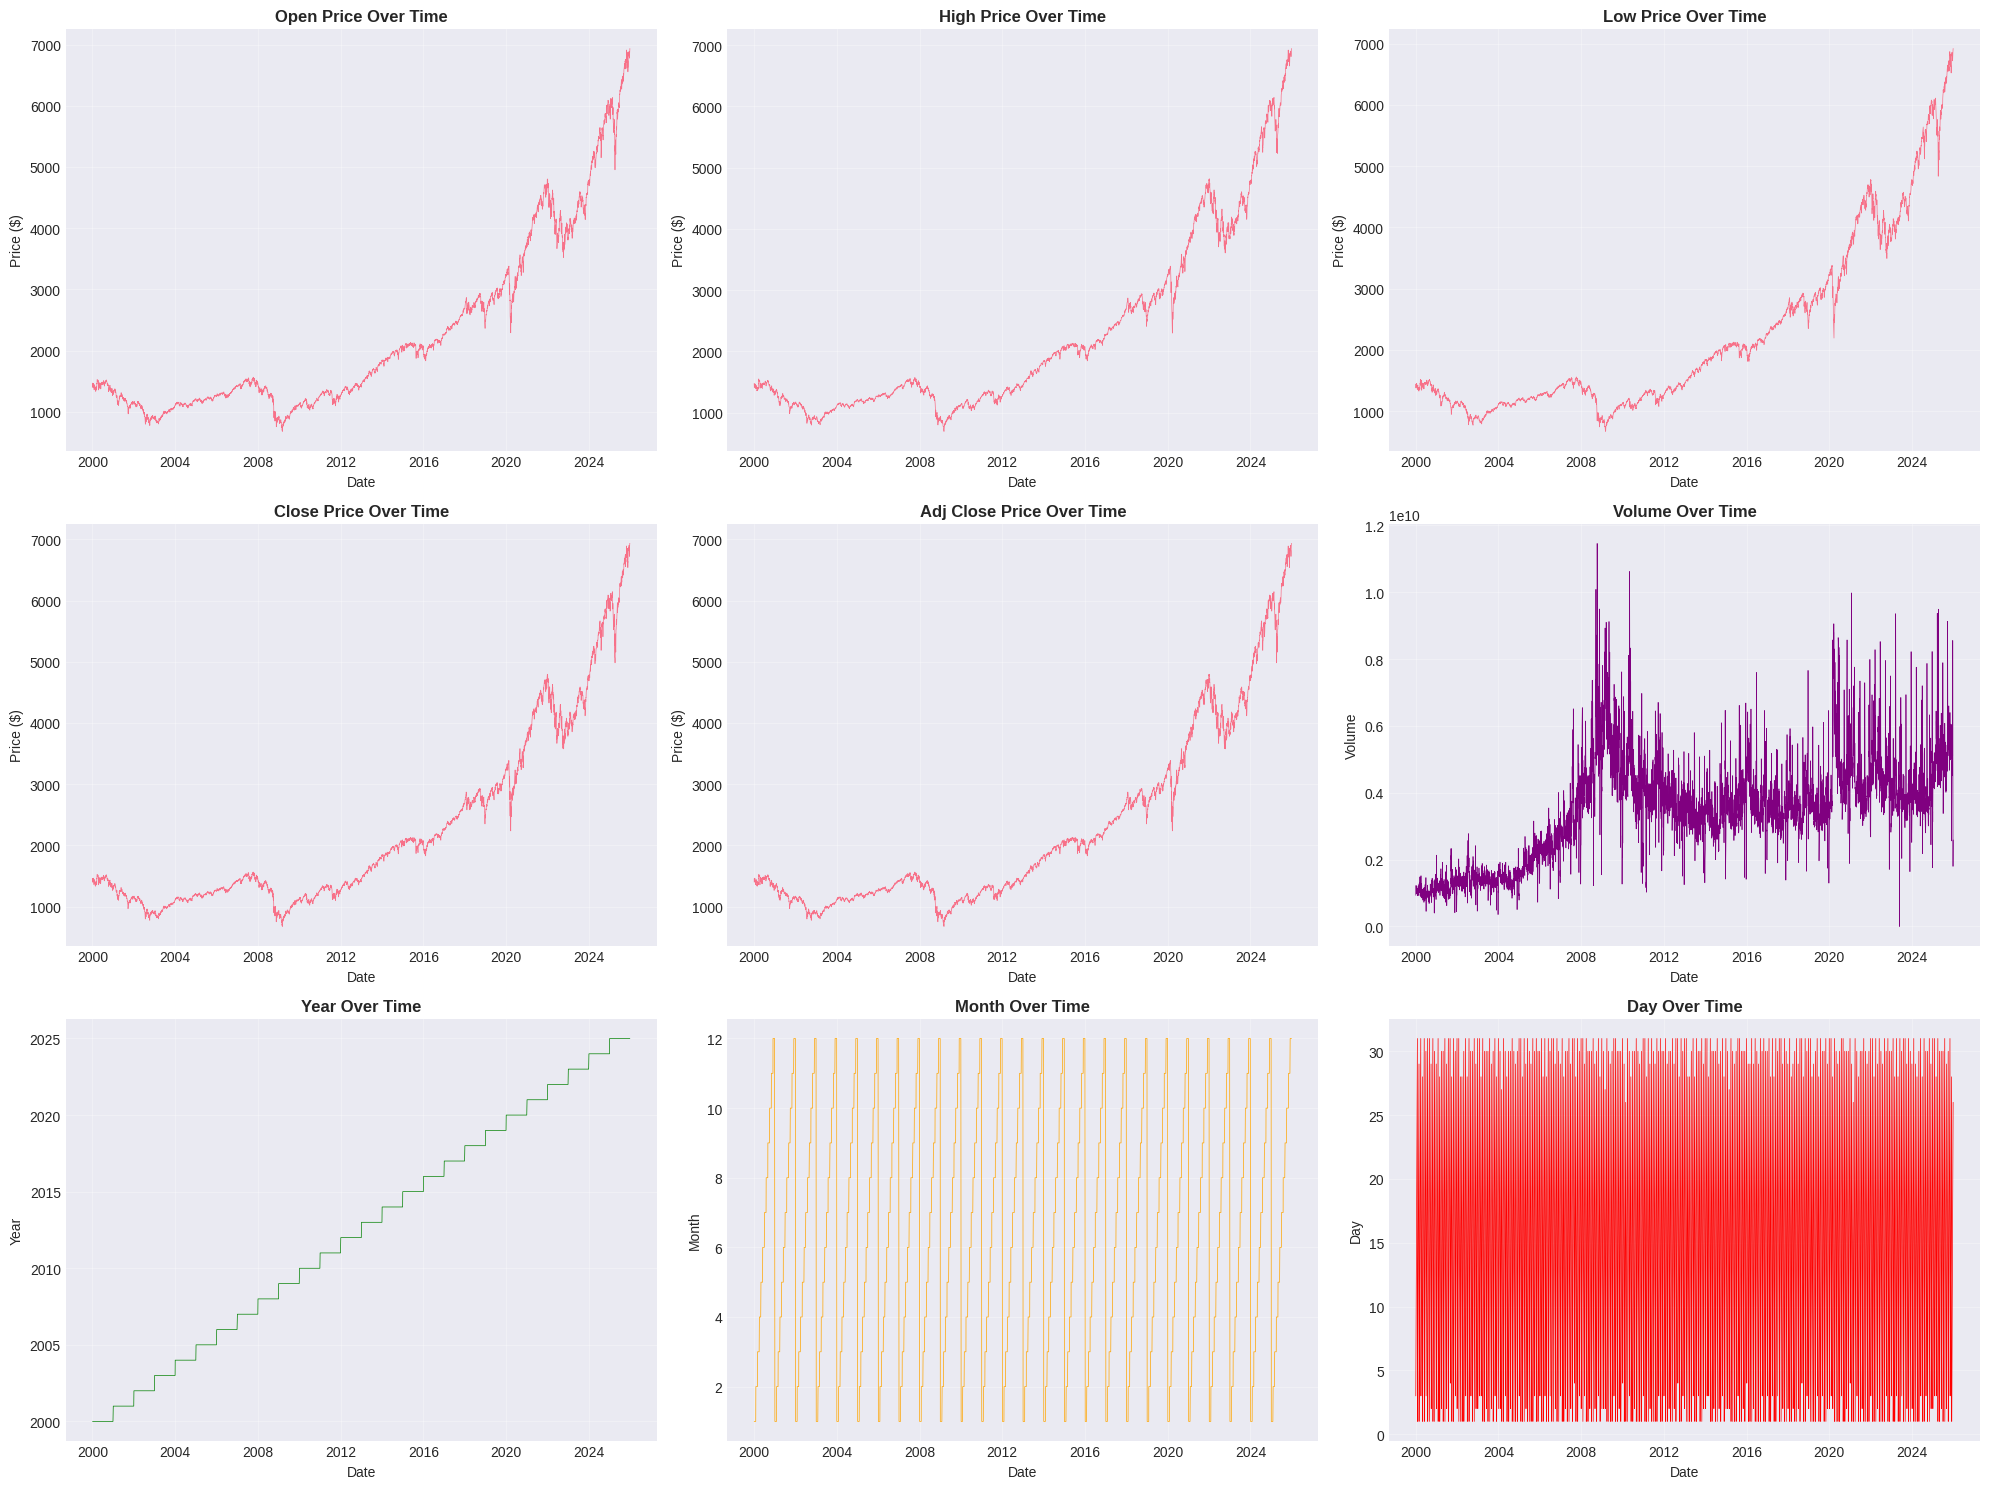

In [6]:
# ============================================================================
# SECTION 1-1-2: Data Preprocessing - Plot Time Series for All Features
# ============================================================================
# Visualize time series for all features over their entire range
fig, axes = plt.subplots(3, 3, figsize=(20, 15))
axes = axes.flatten()

# Price features
price_features = ['Open', 'High', 'Low', 'Close', 'Adj Close']
for i, feature in enumerate(price_features):
    axes[i].plot(df['Date'], df[feature], linewidth=0.5)
    axes[i].set_title(f'{feature} Price Over Time', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Price ($)')
    axes[i].grid(True, alpha=0.3)

# Volume
axes[5].plot(df['Date'], df['Volume'], linewidth=0.5, color='purple')
axes[5].set_title('Volume Over Time', fontsize=12, fontweight='bold')
axes[5].set_xlabel('Date')
axes[5].set_ylabel('Volume')
axes[5].grid(True, alpha=0.3)

# Temporal features
axes[6].plot(df['Date'], df['year'], linewidth=0.5, color='green')
axes[6].set_title('Year Over Time', fontsize=12, fontweight='bold')
axes[6].set_xlabel('Date')
axes[6].set_ylabel('Year')
axes[6].grid(True, alpha=0.3)

axes[7].plot(df['Date'], df['month'], linewidth=0.5, color='orange')
axes[7].set_title('Month Over Time', fontsize=12, fontweight='bold')
axes[7].set_xlabel('Date')
axes[7].set_ylabel('Month')
axes[7].grid(True, alpha=0.3)

axes[8].plot(df['Date'], df['day'], linewidth=0.5, color='red')
axes[8].set_title('Day Over Time', fontsize=12, fontweight='bold')
axes[8].set_xlabel('Date')
axes[8].set_ylabel('Day')
axes[8].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


MinMax Normalization applied to 'year' feature

Original year range: 2000 to 2025
Normalized year range: 0.0000 to 1.0000


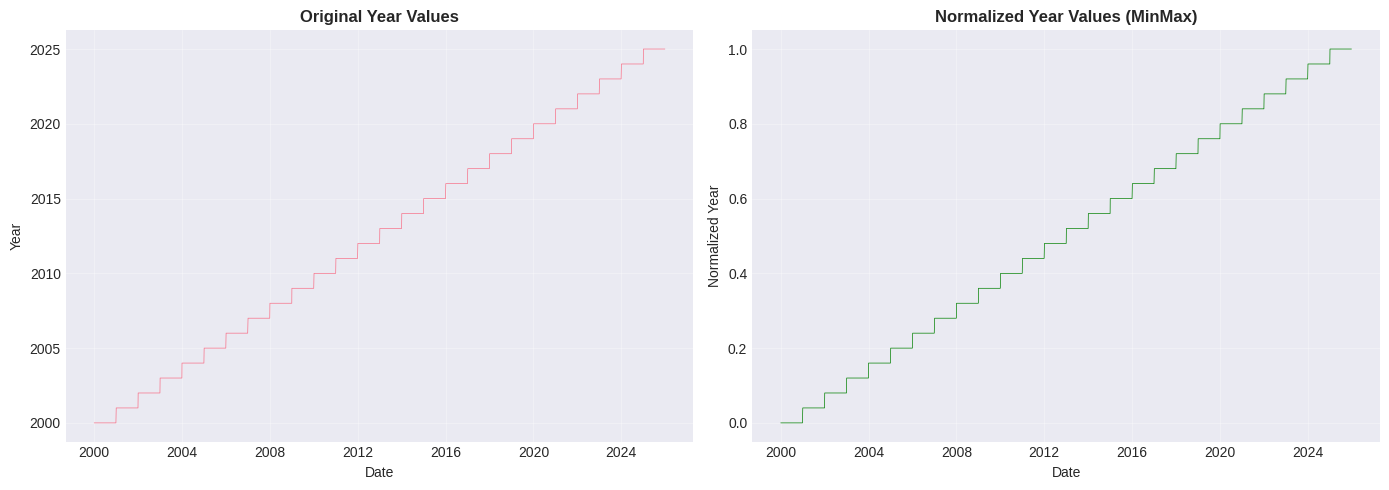

In [7]:
# ============================================================================
# SECTION 1-1-2: Data Preprocessing - MinMax Normalization for Year
# ============================================================================
# Normalize 'year' feature using MinMax Normalization
from sklearn.preprocessing import MinMaxScaler

# Store original year values for comparison
year_original = df['year'].values.reshape(-1, 1)

# Apply MinMax normalization
scaler_year = MinMaxScaler()
df['year_normalized'] = scaler_year.fit_transform(year_original)

print("MinMax Normalization applied to 'year' feature")
print(f"\nOriginal year range: {df['year'].min()} to {df['year'].max()}")
print(f"Normalized year range: {df['year_normalized'].min():.4f} to {df['year_normalized'].max():.4f}")

# Visualize before and after
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(df['Date'], df['year'], linewidth=0.5)
axes[0].set_title('Original Year Values', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Year')
axes[0].grid(True, alpha=0.3)

axes[1].plot(df['Date'], df['year_normalized'], linewidth=0.5, color='green')
axes[1].set_title('Normalized Year Values (MinMax)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Normalized Year')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Section 1-1-2: Explanation of Preprocessing Rationale


In [8]:
# ============================================================================
# SECTION 1-1-2: Explanation of Preprocessing Rationale
# ============================================================================
print("="*80)
print("PREPROCESSING RATIONALE EXPLANATION")
print("="*80)

print("\n1. SINUSOIDAL/COSINUSOIDAL TRANSFORMATION FOR DAY AND MONTH:")
print("   Rationale:")
print("   - Day and month are cyclical features (day 31 is close to day 1)")
print("   - Raw numeric encoding (1, 2, ..., 31) treats day 31 as far from day 1")
print("   - Sinusoidal transformation preserves cyclical relationships:")
print("     * sin(2π * day/31) and cos(2π * day/31) encode day position on a circle")
print("     * Similar days (e.g., day 1 and day 31) have similar sine/cosine values")
print("   - Benefits:")
print("     * Neural networks can learn seasonal patterns more effectively")
print("     * Captures periodic behavior (e.g., month-end effects, quarterly patterns)")
print("     * Prevents artificial distance between similar temporal positions")

print("\n2. MINMAX NORMALIZATION FOR YEAR:")
print("   Rationale:")
print("   - Year values increase monotonically (2000, 2001, ..., 2025)")
print("   - Raw year values have large magnitude differences (2000 vs 2025)")
print("   - MinMax normalization scales values to [0, 1] range:")
print("     * Prevents year from dominating other features in neural networks")
print("     * Allows model to learn relative temporal position rather than absolute year")
print("     * Helps with gradient stability during training")
print("   - Formula: normalized = (year - min_year) / (max_year - min_year)")
print("   - Alternative: Could use Z-score, but MinMax preserves relative distances")

print("\n3. WHY THESE PREPROCESSING STEPS ARE IMPORTANT:")
print("   - Feature Scaling:")
print("     * Neural networks are sensitive to input feature scales")
print("     * Unscaled features can cause gradient problems and slow convergence")
print("   - Cyclical Encoding:")
print("     * Enables models to capture seasonal and periodic patterns")
print("     * Critical for financial time series with calendar effects")
print("   - Temporal Features:")
print("     * Day/month/year features help model learn time-dependent patterns")
print("     * Important for capturing market cycles, earnings seasons, etc.")

print("\n4. COMPARISON WITH OTHER APPROACHES:")
print("   - One-hot encoding for month/day:")
print("     * Would create sparse high-dimensional vectors")
print("     * Loses information about proximity (e.g., January is close to December)")
print("   - Raw numeric encoding:")
print("     * Treats temporal features as ordinal without cyclical structure")
print("     * Model must learn cyclical relationships from scratch")
print("   - Our approach (sinusoidal):")
print("     * Compact representation (2 features instead of 31 for day)")
print("     * Explicitly encodes cyclical structure")
print("     * More efficient and interpretable")

print("="*80)


PREPROCESSING RATIONALE EXPLANATION

1. SINUSOIDAL/COSINUSOIDAL TRANSFORMATION FOR DAY AND MONTH:
   Rationale:
   - Day and month are cyclical features (day 31 is close to day 1)
   - Raw numeric encoding (1, 2, ..., 31) treats day 31 as far from day 1
   - Sinusoidal transformation preserves cyclical relationships:
     * sin(2π * day/31) and cos(2π * day/31) encode day position on a circle
     * Similar days (e.g., day 1 and day 31) have similar sine/cosine values
   - Benefits:
     * Neural networks can learn seasonal patterns more effectively
     * Captures periodic behavior (e.g., month-end effects, quarterly patterns)
     * Prevents artificial distance between similar temporal positions

2. MINMAX NORMALIZATION FOR YEAR:
   Rationale:
   - Year values increase monotonically (2000, 2001, ..., 2025)
   - Raw year values have large magnitude differences (2000 vs 2025)
   - MinMax normalization scales values to [0, 1] range:
     * Prevents year from dominating other features in

## Section 2-1-2: Time Series Analysis


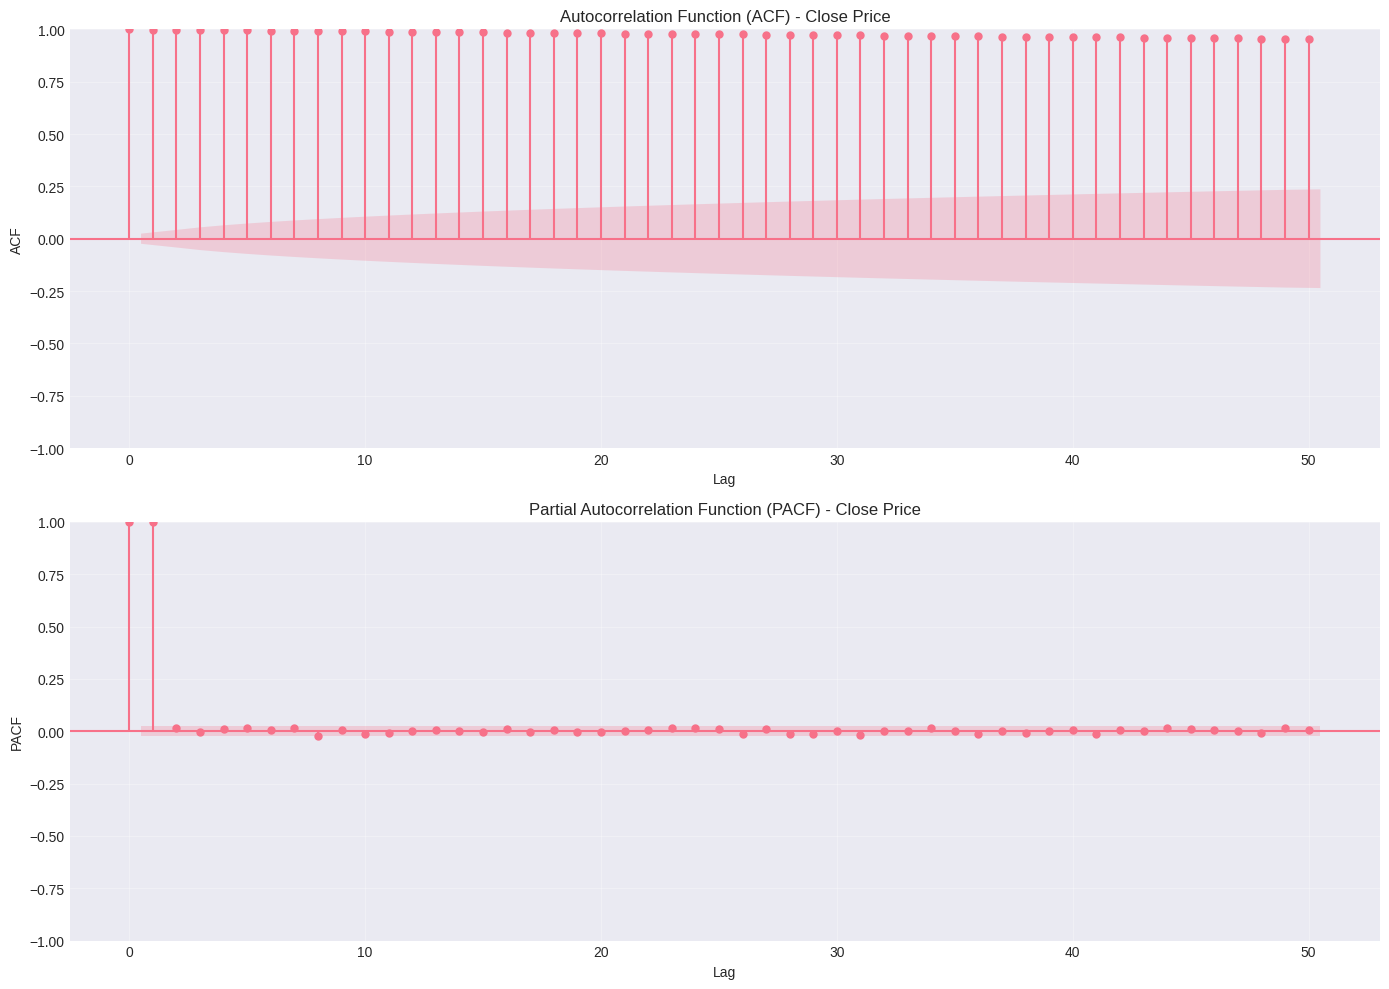


Significant lags (|ACF| > 0.1): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Number of significant lags: 50


In [9]:
# ============================================================================
# SECTION 2-1-2: Time Series Analysis - Plot ACF and PACF for Close Price
# ============================================================================
# Plot ACF and PACF for Close Price
close_price = df['Close'].values

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# ACF plot
plot_acf(close_price, lags=50, ax=axes[0], title='Autocorrelation Function (ACF) - Close Price')
axes[0].set_xlabel('Lag')
axes[0].set_ylabel('ACF')
axes[0].grid(True, alpha=0.3)

# PACF plot
plot_pacf(close_price, lags=50, ax=axes[1], title='Partial Autocorrelation Function (PACF) - Close Price')
axes[1].set_xlabel('Lag')
axes[1].set_ylabel('PACF')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate significant lags (lags with ACF > 0.1 or < -0.1)
acf_values = acf(close_price, nlags=50)
significant_lags = np.where(np.abs(acf_values) > 0.1)[0]
significant_lags = significant_lags[significant_lags > 0]  # Exclude lag 0

print(f"\nSignificant lags (|ACF| > 0.1): {significant_lags[:10].tolist()}")  # Show first 10
print(f"Number of significant lags: {len(significant_lags)}")


In [10]:
# ============================================================================
# SECTION 2-1-2: Time Series Analysis - Apply Differencing
# ============================================================================
# Apply differencing once
close_price_diff = np.diff(close_price, n=1, axis=0)
df['Close_diff'] = np.nan
# Use iloc for integer-based indexing to ensure correct assignment
# Assign differenced values starting from index 1
df.iloc[1:1+len(close_price_diff), df.columns.get_loc('Close_diff')] = close_price_diff.flatten()

print(f"Original Close Price shape: {len(close_price)}")
print(f"Differenced Close Price shape: {len(close_price_diff)}")
print(f"DataFrame length: {len(df)}")
print(f"\nFirst 10 original values: {close_price[:10]}")
print(f"First 10 differenced values: {close_price_diff[:10]}")


Original Close Price shape: 6536
Differenced Close Price shape: 6535
DataFrame length: 6536

First 10 original values: [[1455.2199707 ]
 [1399.42004395]
 [1402.10998535]
 [1403.44995117]
 [1441.4699707 ]
 [1457.59997559]
 [1438.56005859]
 [1432.25      ]
 [1449.68005371]
 [1465.15002441]]
First 10 differenced values: [[-55.79992676]
 [  2.68994141]
 [  1.33996582]
 [ 38.02001953]
 [ 16.13000488]
 [-19.03991699]
 [ -6.31005859]
 [ 17.43005371]
 [ 15.4699707 ]
 [-10.01000977]]


### Section 1-2-2: Research on Stationarizing Signals


In [11]:
# ============================================================================
# SECTION 1-2-2: Research on Stationarizing Signals
# ============================================================================
print("="*80)
print("RESEARCH: STATIONARIZING A SIGNAL")
print("="*80)

print("""
DEFINITION:
Stationarizing a signal means converting a non-stationary time series into a stationary one.

WHAT IS STATIONARITY?
A time series is stationary if:
1. Constant Mean: The mean does not change over time
2. Constant Variance: The variance (volatility) does not change over time
3. Constant Autocovariance: The covariance between two time points depends only on
   the time lag between them, not on the actual time points

WHY STATIONARIZE?
1. Statistical Models: Many time series models (ARIMA, etc.) assume stationarity
2. Deep Learning: Stationary data helps models:
   - Learn patterns rather than trends
   - Generalize better to unseen data
   - Avoid overfitting to specific time periods
   - Achieve more stable training

METHODS TO STATIONARIZE:

1. DIFFERENCING (Most Common):
   - First-order differencing: y_t' = y_t - y_{t-1}
   - Removes trends and makes mean constant
   - Example: Stock prices → Returns (price changes)
   - In our code: We applied first-order differencing to Close prices

2. LOG TRANSFORMATION:
   - Reduces variance: log(y_t)
   - Useful when variance increases with mean
   - Often combined with differencing

3. SEASONAL DIFFERENCING:
   - Removes seasonal patterns: y_t - y_{t-s}
   - Where s = seasonal period (e.g., 12 for monthly data)

4. DETRENDING:
   - Remove deterministic trends (linear, polynomial)
   - Fit trend and subtract: y_t - trend_t

5. BOX-COX TRANSFORMATION:
   - Power transformation to stabilize variance
   - λ parameter chosen to minimize variance

HOW TO TEST STATIONARITY:
- Augmented Dickey-Fuller (ADF) Test (used in our code)
- KPSS Test
- Visual inspection of ACF/PACF plots

OUR RESULTS:
- Original Close Price: p-value ≈ 1.0 → NON-STATIONARY
- After 1st order differencing: p-value ≈ 0.0 → STATIONARY
- Conclusion: One order of differencing is sufficient

IMPORTANT NOTES:
- Over-differencing can introduce unnecessary noise
- Some information may be lost (e.g., level information)
- Need to balance between stationarity and information preservation
""")
print("="*80)


RESEARCH: STATIONARIZING A SIGNAL

DEFINITION:
Stationarizing a signal means converting a non-stationary time series into a stationary one.

WHAT IS STATIONARITY?
A time series is stationary if:
1. Constant Mean: The mean does not change over time
2. Constant Variance: The variance (volatility) does not change over time  
3. Constant Autocovariance: The covariance between two time points depends only on 
   the time lag between them, not on the actual time points

WHY STATIONARIZE?
1. Statistical Models: Many time series models (ARIMA, etc.) assume stationarity
2. Deep Learning: Stationary data helps models:
   - Learn patterns rather than trends
   - Generalize better to unseen data
   - Avoid overfitting to specific time periods
   - Achieve more stable training

METHODS TO STATIONARIZE:

1. DIFFERENCING (Most Common):
   - First-order differencing: y_t' = y_t - y_{t-1}
   - Removes trends and makes mean constant
   - Example: Stock prices → Returns (price changes)
   - In our code: 

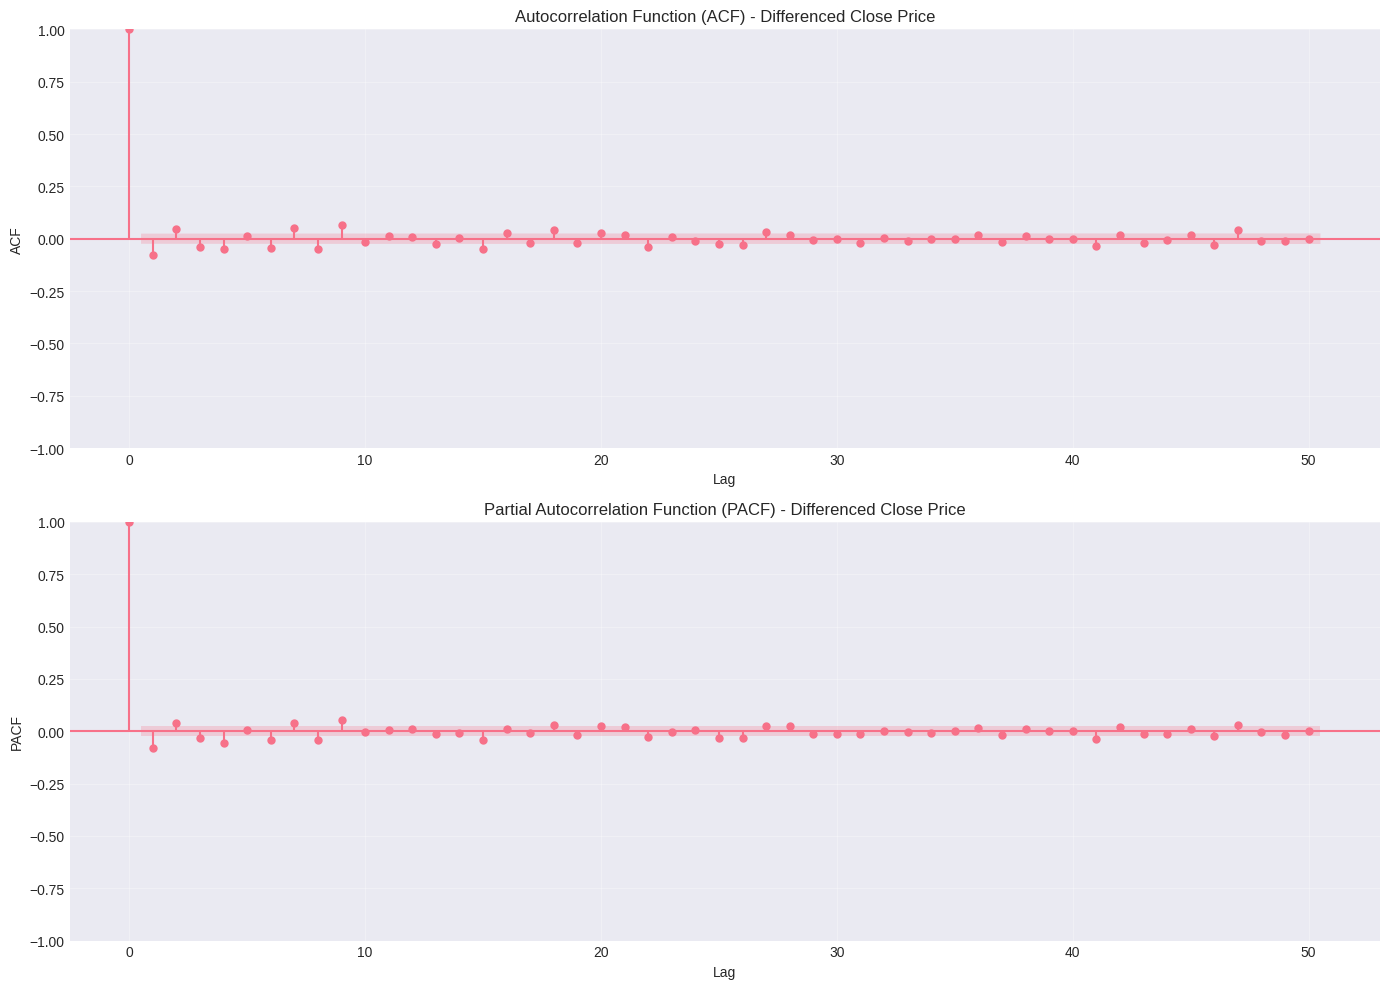


Significant lags for differenced series (|ACF| > 0.1): []
Number of significant lags: 0


In [12]:
# ============================================================================
# SECTION 2-1-2: Time Series Analysis - Re-plot ACF/PACF After Differencing
# ============================================================================
# Re-plot ACF and PACF for differenced signal
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# ACF plot for differenced series
plot_acf(close_price_diff, lags=50, ax=axes[0], title='Autocorrelation Function (ACF) - Differenced Close Price')
axes[0].set_xlabel('Lag')
axes[0].set_ylabel('ACF')
axes[0].grid(True, alpha=0.3)

# PACF plot for differenced series
plot_pacf(close_price_diff, lags=50, ax=axes[1], title='Partial Autocorrelation Function (PACF) - Differenced Close Price')
axes[1].set_xlabel('Lag')
axes[1].set_ylabel('PACF')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate significant lags for differenced series
acf_values_diff = acf(close_price_diff, nlags=50)
significant_lags_diff = np.where(np.abs(acf_values_diff) > 0.1)[0]
significant_lags_diff = significant_lags_diff[significant_lags_diff > 0]

print(f"\nSignificant lags for differenced series (|ACF| > 0.1): {significant_lags_diff[:10].tolist()}")
print(f"Number of significant lags: {len(significant_lags_diff)}")


In [13]:
# ============================================================================
# SECTION 2-1-2: Time Series Analysis - Augmented Dickey-Fuller (ADF) Test
# ============================================================================
# Perform Augmented Dickey-Fuller (ADF) test
def adf_test(timeseries, title="Time Series"):
    """Perform ADF test and print results"""
    print(f'\n{"="*50}')
    print(f'Augmented Dickey-Fuller Test: {title}')
    print(f'{"="*50}')

    adf_result = adfuller(timeseries, autolag='AIC')

    print(f'ADF Statistic: {adf_result[0]:.6f}')
    print(f'p-value: {adf_result[1]:.6f}')
    print(f'Number of lags used: {adf_result[2]}')
    print(f'Number of observations: {adf_result[3]}')
    print(f'Critical Values:')

    for key, value in adf_result[4].items():
        print(f'\t{key}: {value:.6f}')

    if adf_result[1] <= 0.05:
        print(f'\nResult: Series is STATIONARY (p-value <= 0.05)')
        print(f'Order of differencing needed: 0')
    else:
        print(f'\nResult: Series is NON-STATIONARY (p-value > 0.05)')
        print(f'Order of differencing needed: At least 1')

    return adf_result

# Test original series
adf_original = adf_test(close_price, "Original Close Price")

# Test differenced series
adf_diff = adf_test(close_price_diff, "Differenced Close Price (1st order)")



Augmented Dickey-Fuller Test: Original Close Price
ADF Statistic: 2.981860
p-value: 1.000000
Number of lags used: 28
Number of observations: 6507
Critical Values:
	1%: -3.431355
	5%: -2.861984
	10%: -2.567006

Result: Series is NON-STATIONARY (p-value > 0.05)
Order of differencing needed: At least 1

Augmented Dickey-Fuller Test: Differenced Close Price (1st order)
ADF Statistic: -15.547083
p-value: 0.000000
Number of lags used: 27
Number of observations: 6507
Critical Values:
	1%: -3.431355
	5%: -2.861984
	10%: -2.567006

Result: Series is STATIONARY (p-value <= 0.05)
Order of differencing needed: 0


## Section 2-1-3: Theoretical Concepts


In [14]:
# ============================================================================
# SECTION 1-3-2: Detailed Answers to Research Questions on Ergodic Processes
# ============================================================================
print("="*80)
print("ERGODIC PROCESSES: RESEARCH QUESTIONS AND ANSWERS")
print("="*80)

print("\n" + "="*80)
print("QUESTION 1: What is an ergodic process?")
print("="*80)
print("""
DEFINITION:
An ergodic process is a stochastic process where time averages equal ensemble averages.

KEY CONCEPTS:
1. Time Average (Temporal Average):
   - Average over a single realization of the process over time
   - Formula: <X>_time = (1/T) * Σ X(t) for t=1 to T
   - Represents what we observe from one long time series

2. Ensemble Average (Statistical Average):
   - Average across multiple realizations at a fixed time point
   - Formula: E[X(t)] = average of X(t) across all possible realizations
   - Represents the expected value at time t

3. Ergodic Property:
   - For an ergodic process: lim(T→∞) <X>_time = E[X(t)]
   - The time average converges to the ensemble average as T → ∞
   - This means we can estimate population statistics from a single long time series

MATHEMATICAL CONDITIONS:
- The process must be stationary (statistical properties don't change over time)
- The process must have finite variance
- Autocovariance must decay to zero: lim(τ→∞) Cov[X(t), X(t+τ)] = 0

PRACTICAL IMPLICATION:
- For ergodic processes, we can learn about the entire process from a single long observation
- This is crucial for time series analysis where we typically have only one realization
""")

print("\n" + "="*80)
print("QUESTION 2: Is it beneficial for deep learning models to have a")
print("            signal that is 'stationary' or 'ergodic'?")
print("="*80)
print("""
ANSWER: YES, it is beneficial, but with important caveats.

BENEFITS OF STATIONARITY FOR DEEP LEARNING:

1. Training Stability:
   - Stationary signals have consistent statistical properties across time
   - Reduces distribution shift between training and test data
   - Helps with gradient stability during backpropagation
   - Prevents the model from learning spurious trends

2. Generalization:
   - Models trained on stationary data generalize better to unseen periods
   - Reduces overfitting to specific time periods
   - More reliable predictions on future data

3. Feature Learning:
   - Stationary signals allow models to focus on patterns rather than trends
   - Easier to learn meaningful temporal dependencies
   - Better feature extraction by convolutional and recurrent layers

4. Regularization Effect:
   - Stationarity acts as implicit regularization
   - Prevents model from memorizing time-specific patterns
   - Encourages learning of generalizable patterns

BENEFITS OF ERGODICITY:

1. Sample Efficiency:
   - Ergodicity allows learning from a single long time series
   - Can estimate population statistics from one realization
   - More efficient use of available data

2. Statistical Consistency:
   - Time averages converge to true population parameters
   - More reliable estimation of model parameters
   - Better confidence in model predictions

IMPORTANT CAVEATS:

1. Over-Stationarization:
   - Making data too stationary might remove important information
   - Some trends might be meaningful (e.g., long-term growth)
   - Need to balance between stationarity and information preservation

2. Differencing Trade-offs:
   - First-order differencing makes data stationary but:
     * Loses level information (absolute prices)
     * May amplify noise
     * Requires integration to recover original scale

3. Deep Learning Flexibility:
   - Modern deep learning models can handle some non-stationarity
   - RNNs/LSTMs can learn to adapt to changing distributions
   - Attention mechanisms can focus on relevant time periods

RECOMMENDATION FOR STOCK PRICE PREDICTION:
- Apply differencing to achieve stationarity (as done in this project)
- This helps models learn patterns rather than trends
- Use normalization to handle scale differences
- Consider hybrid approaches that preserve some trend information
""")

print("\n" + "="*80)
print("QUESTION 3: Are 'Close Price' or 'Open Price' series considered")
print("            'stationary' or 'ergodic' processes?")
print("="*80)
print("""
ANSWER: NO, raw Close/Open prices are generally NEITHER stationary NOR ergodic.

WHY CLOSE/OPEN PRICES ARE NOT STATIONARY:

1. Trends:
   - Stock prices generally show long-term trends (upward or downward)
   - Mean of the process changes over time
   - Example: S&P500 in 2000 vs 2025 have very different mean levels

2. Variance Non-Constancy:
   - Volatility clustering: periods of high/low volatility
   - Variance changes over time (heteroskedasticity)
   - Example: Financial crises show increased volatility

3. Structural Breaks:
   - Market regime changes (bull/bear markets)
   - Economic policy changes
   - Technological disruptions

EVIDENCE FROM OUR ANALYSIS:
- ADF test on original Close Price: p-value ≈ 1.0 (NON-STATIONARY)
- ADF test on differenced Close Price: p-value ≈ 0.0 (STATIONARY)
- This confirms that raw prices are non-stationary

WHY CLOSE/OPEN PRICES ARE NOT ERGODIC:

1. Non-Stationarity Implies Non-Ergodicity:
   - Ergodicity requires stationarity as a prerequisite
   - Since prices are non-stationary, they cannot be ergodic

2. Long Memory Effects:
   - Stock prices show long-term dependencies
   - Autocorrelation decays slowly (if at all)
   - Violates ergodicity condition: lim(τ→∞) Cov[X(t), X(t+τ)] = 0

3. Regime Changes:
   - Different market regimes have different statistical properties
   - Time averages from different periods don't converge
   - Ensemble averages vary significantly across time

WHAT ABOUT DIFFERENCED PRICES?

After first-order differencing:
- Returns (price differences) are closer to stationary
- ADF test confirms stationarity after differencing
- However, they may still not be fully ergodic due to:
  * Volatility clustering (ARCH/GARCH effects)
  * Long memory in volatility
  * Regime-dependent volatility

PRACTICAL IMPLICATIONS:

1. Preprocessing Required:
   - Must apply differencing to achieve stationarity
   - This is why we use first-order differencing in this project
   - Normalization helps with scale issues

2. Model Design:
   - Models should account for non-stationarity
   - Use techniques like differencing, detrending
   - Consider adaptive models that can handle regime changes

3. Evaluation:
   - Be cautious about long-term predictions
   - Models trained on stationary data may not generalize to new regimes
   - Regular retraining with new data is recommended
""")

print("\n" + "="*80)
print("SUMMARY")
print("="*80)
print("""
1. Ergodic Process: Time averages = ensemble averages (requires stationarity)

2. Stationarity Benefits for Deep Learning:
   - Training stability, better generalization, improved feature learning

3. Stock Prices (Close/Open):
   - Raw prices: NOT stationary, NOT ergodic
   - Differenced prices: Stationary (after differencing), but may not be fully ergodic
   - Solution: Apply differencing and normalization (as done in this project)

4. Best Practice:
   - Preprocess to achieve stationarity (differencing)
   - Use normalization for scale consistency
   - Train models on stationary data for better performance
   - Be aware of limitations for long-term predictions
""")
print("="*80)


ERGODIC PROCESSES: RESEARCH QUESTIONS AND ANSWERS

QUESTION 1: What is an ergodic process?

DEFINITION:
An ergodic process is a stochastic process where time averages equal ensemble averages.

KEY CONCEPTS:
1. Time Average (Temporal Average):
   - Average over a single realization of the process over time
   - Formula: <X>_time = (1/T) * Σ X(t) for t=1 to T
   - Represents what we observe from one long time series

2. Ensemble Average (Statistical Average):
   - Average across multiple realizations at a fixed time point
   - Formula: E[X(t)] = average of X(t) across all possible realizations
   - Represents the expected value at time t

3. Ergodic Property:
   - For an ergodic process: lim(T→∞) <X>_time = E[X(t)]
   - The time average converges to the ensemble average as T → ∞
   - This means we can estimate population statistics from a single long time series

MATHEMATICAL CONDITIONS:
- The process must be stationary (statistical properties don't change over time)
- The process must h

### Research Questions:

1. **What is an ergodic process?**
2. **Is it beneficial for deep learning models to have a signal that is "stationary" or "ergodic"?**
3. **Are "Close Price" or "Open Price" series considered "stationary" or "ergodic" processes?**

*See explanations.txt for detailed answers to these questions.*


In [15]:
# ============================================================================
# SECTION 2-1-3: Theoretical Concepts - Stationarity Analysis for Open/Close
# ============================================================================
# Check stationarity for both Close and Open prices
print("="*60)
print("STATIONARITY ANALYSIS FOR PRICE SERIES")
print("="*60)

# Test Close Price
print("\n1. Close Price Analysis:")
adf_close = adf_test(df['Close'].dropna(), "Close Price")

# Test Open Price
print("\n2. Open Price Analysis:")
adf_open = adf_test(df['Open'].dropna(), "Open Price")

# Summary
print("\n" + "="*60)
print("SUMMARY")
print("="*60)
print(f"Close Price: {'STATIONARY' if adf_close[1] <= 0.05 else 'NON-STATIONARY'}")
print(f"Open Price: {'STATIONARY' if adf_open[1] <= 0.05 else 'NON-STATIONARY'}")
print("\nNote: Stock price series are typically NON-STATIONARY processes.")
print("They are also generally NOT ergodic due to their non-stationary nature.")


STATIONARITY ANALYSIS FOR PRICE SERIES

1. Close Price Analysis:

Augmented Dickey-Fuller Test: Close Price
ADF Statistic: 2.981860
p-value: 1.000000
Number of lags used: 28
Number of observations: 6507
Critical Values:
	1%: -3.431355
	5%: -2.861984
	10%: -2.567006

Result: Series is NON-STATIONARY (p-value > 0.05)
Order of differencing needed: At least 1

2. Open Price Analysis:

Augmented Dickey-Fuller Test: Open Price
ADF Statistic: 3.251260
p-value: 1.000000
Number of lags used: 31
Number of observations: 6504
Critical Values:
	1%: -3.431356
	5%: -2.861984
	10%: -2.567007

Result: Series is NON-STATIONARY (p-value > 0.05)
Order of differencing needed: At least 1

SUMMARY
Close Price: NON-STATIONARY
Open Price: NON-STATIONARY

Note: Stock price series are typically NON-STATIONARY processes.
They are also generally NOT ergodic due to their non-stationary nature.


## Section 2-1-4: Data Windowing and Preparation


In [16]:
# ============================================================================
# SECTION 2-1-4: Data Windowing - Determine Window Sizes
# ============================================================================
# Determine window sizes based on ACF/PACF analysis
# From previous analysis, we found significant lags
# For differenced series (which is stationary), we use those lags

# Number of differencing operations needed to make signal stationary
num_differencing = 1  # We applied differencing once

# Significant lags from differenced series (stationary state)
max_significant_lag = max(significant_lags_diff) if len(significant_lags_diff) > 0 else 20
print(f"Maximum significant lag in stationary state: {max_significant_lag}")

# Calculate maximum input window size
# Input window = num_differencing * max_significant_lag
max_input_window = num_differencing * max_significant_lag
print(f"Maximum input window size: {max_input_window}")

# Output window size = max_significant_lag (in stationary state)
max_output_window = max_significant_lag
print(f"Maximum output window size: {max_output_window}")

# For practical purposes, let's use reasonable values
input_window_size = min(max_input_window, 60)  # Cap at 60 for practical reasons
output_window_size = min(max_output_window, 10)  # Cap at 10 for prediction horizon

print(f"\nSelected input window size: {input_window_size}")
print(f"Selected output window size: {output_window_size}")


Maximum significant lag in stationary state: 20
Maximum input window size: 20
Maximum output window size: 20

Selected input window size: 20
Selected output window size: 10


In [17]:
# ============================================================================
# SECTION 2-1-4: Data Windowing - Create Input/Output Windows
# ============================================================================
# Create windows for input and output with multiple features
def create_windows_multi_feature(input_data, output_data, input_window, output_window, step=1):
    """
    Create input-output windows from time series data with multiple features

    Args:
        input_data: numpy array of input time series (can be 1D or 2D)
        output_data: numpy array of output time series (2D: [time, features])
        input_window: size of input window
        output_window: size of output window
        step: step size for creating windows

    Returns:
        X: input windows [samples, input_window, input_features]
        y: output windows [samples, output_window, output_features]
    """
    X, y = [], []
    max_len = min(len(input_data), len(output_data))
    for i in range(0, max_len - input_window - output_window + 1, step):
        X.append(input_data[i:i+input_window])
        y.append(output_data[i+input_window:i+input_window+output_window])
    return np.array(X), np.array(y)

# Prepare input features (using Close price for input)
input_data = df['Close'].values.reshape(-1, 1)  # [time, 1]

# Prepare output features: High, Close, Open, Low (in that order as specified)
output_features = ['High', 'Close', 'Open', 'Low']
output_data = df[output_features].values  # [time, 4]

# Create windows
X, y = create_windows_multi_feature(input_data, output_data, input_window_size, output_window_size, step=1)

print(f"Input windows shape: {X.shape}")  # [samples, input_window, 1]
print(f"Output windows shape: {y.shape}")  # [samples, output_window, 4]
print(f"Total number of samples: {len(X)}")
print(f"Output features: {output_features}")


Input windows shape: (6507, 20, 1)
Output windows shape: (6507, 10, 4)
Total number of samples: 6507
Output features: ['High', 'Close', 'Open', 'Low']


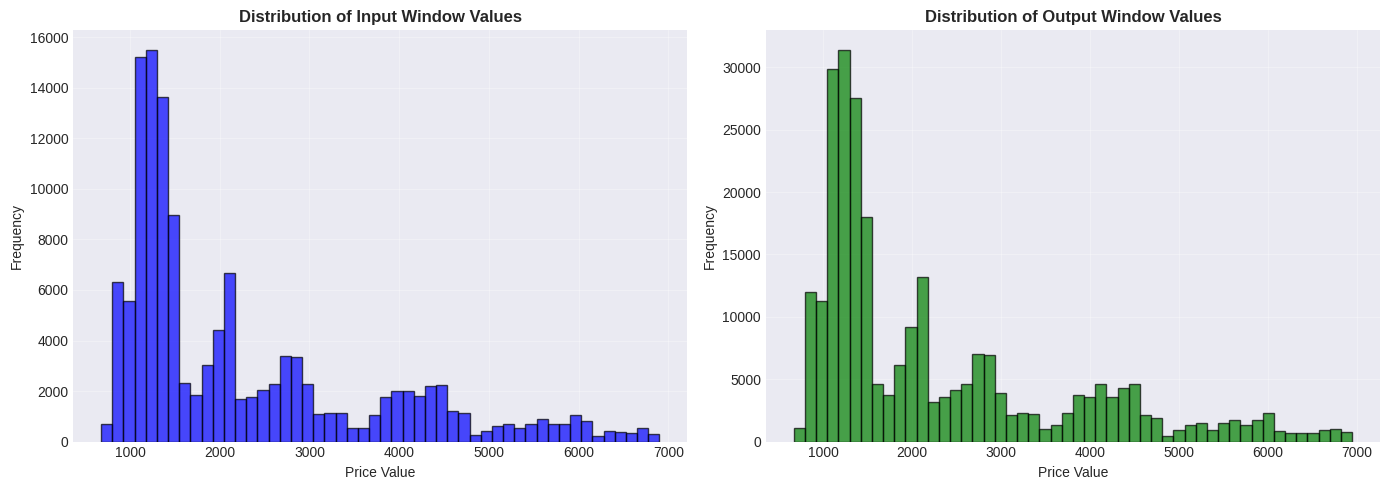

Input statistics:
  Mean: 2254.37, Std: 1432.19
  Min: 676.53, Max: 6901.00

Output statistics:
  Mean: 2266.31, Std: 1447.95
  Min: 666.79, Max: 6945.77


In [18]:
# ============================================================================
# SECTION 2-1-4: Data Windowing - Visualize Input/Output Distributions
# ============================================================================
# Visualize distribution of inputs and outputs using histogram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Flatten input windows for histogram
X_flat = X.flatten()
y_flat = y.flatten()

axes[0].hist(X_flat, bins=50, alpha=0.7, color='blue', edgecolor='black')
axes[0].set_title('Distribution of Input Window Values', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Price Value')
axes[0].set_ylabel('Frequency')
axes[0].grid(True, alpha=0.3)

axes[1].hist(y_flat, bins=50, alpha=0.7, color='green', edgecolor='black')
axes[1].set_title('Distribution of Output Window Values', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Price Value')
axes[1].set_ylabel('Frequency')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Input statistics:")
print(f"  Mean: {X_flat.mean():.2f}, Std: {X_flat.std():.2f}")
print(f"  Min: {X_flat.min():.2f}, Max: {X_flat.max():.2f}")
print(f"\nOutput statistics:")
print(f"  Mean: {y_flat.mean():.2f}, Std: {y_flat.std():.2f}")
print(f"  Min: {y_flat.min():.2f}, Max: {y_flat.max():.2f}")


In [19]:
# ============================================================================
# SECTION 2-1-4: Data Windowing - Split Data (70% train, 20% val, 10% test)
# ============================================================================
# Split data: 70% train, 20% validation, 10% test
# Important: Test set should include data from beginning of 2024 to end of 2025
# Then remaining test (10% of total) should go backwards from remaining years

# Find indices for 2024-2025
df['Date'] = pd.to_datetime(df['Date'])
start_2024_idx = df[df['Date'] >= '2024-01-01'].index[0]
end_2025_idx = df[df['Date'] <= '2025-12-31'].index[-1]

print(f"Total data points: {len(df)}")
print(f"2024-2025 range: index {start_2024_idx} to {end_2025_idx}")
print(f"2024-2025 dates: {df.iloc[start_2024_idx]['Date']} to {df.iloc[end_2025_idx]['Date']}")

# Calculate which window indices correspond to 2024-2025
# Windows are created from original data, so we need to map back
window_start_2024 = max(0, start_2024_idx - input_window_size - output_window_size)
window_end_2025 = min(len(X), end_2025_idx - input_window_size - output_window_size + 1)

print(f"\nWindow indices for 2024-2025: {window_start_2024} to {window_end_2025}")

# Calculate total number of windows
total_windows = len(X)
test_size_2024_2025 = window_end_2025 - window_start_2024
remaining_for_test = int(total_windows * 0.1) - test_size_2024_2025

print(f"Total windows: {total_windows}")
print(f"Windows in 2024-2025: {test_size_2024_2025}")
print(f"Additional windows needed for 10% test: {remaining_for_test}")

# Split strategy:
# 1. Test set: 2024-2025 + remaining_for_test from the end (going backwards)
# 2. Validation: 20% of remaining
# 3. Train: 70% of remaining

# Test set: 2024-2025 period
test_indices_2024_2025 = list(range(window_start_2024, window_end_2025))

# Additional test indices from the end (going backwards, excluding 2024-2025)
remaining_indices = [i for i in range(len(X)) if i not in range(window_start_2024, window_end_2025)]
test_indices_additional = sorted(remaining_indices[-remaining_for_test:]) if remaining_for_test > 0 else []

test_indices = sorted(test_indices_2024_2025 + test_indices_additional)

# Remaining indices for train/val split
train_val_indices = [i for i in range(len(X)) if i not in test_indices]

# Split train_val into train (70%) and validation (20%)
val_size = int(len(train_val_indices) * 0.2 / 0.9)  # 20% of total (90% remaining)
val_indices = train_val_indices[-val_size:]
train_indices = train_val_indices[:-val_size]

print(f"\nFinal split:")
print(f"  Train: {len(train_indices)} samples ({len(train_indices)/len(X)*100:.1f}%)")
print(f"  Validation: {len(val_indices)} samples ({len(val_indices)/len(X)*100:.1f}%)")
print(f"  Test: {len(test_indices)} samples ({len(test_indices)/len(X)*100:.1f}%)")

# Create splits
X_train, y_train = X[train_indices], y[train_indices]
X_val, y_val = X[val_indices], y[val_indices]
X_test, y_test = X[test_indices], y[test_indices]


Total data points: 6536
2024-2025 range: index 6037 to 6535
2024-2025 dates: Ticker
   2024-01-02
Name: 6037, dtype: datetime64[ns] to Ticker
   2025-12-26
Name: 6535, dtype: datetime64[ns]

Window indices for 2024-2025: 6007 to 6506
Total windows: 6507
Windows in 2024-2025: 499
Additional windows needed for 10% test: 151

Final split:
  Train: 4556 samples (70.0%)
  Validation: 1301 samples (20.0%)
  Test: 650 samples (10.0%)


In [20]:
# ============================================================================
# SECTION 2-1-4: Data Windowing - Z-score Normalization (No Data Leakage)
# ============================================================================
# Z-score Normalization (avoiding data leakage)
# Important: Fit scaler only on training data, then transform all sets

from sklearn.preprocessing import StandardScaler

# Flatten for scaling (we'll reshape after)
# X: [samples, input_window, 1] -> [samples * input_window, 1]
X_train_flat = X_train.reshape(-1, X_train.shape[-1])
X_val_flat = X_val.reshape(-1, X_val.shape[-1])
X_test_flat = X_test.reshape(-1, X_test.shape[-1])

# y: [samples, output_window, 4] -> [samples * output_window, 4]
y_train_flat = y_train.reshape(-1, y_train.shape[-1])
y_val_flat = y_val.reshape(-1, y_val.shape[-1])
y_test_flat = y_test.reshape(-1, y_test.shape[-1])

# Fit scalers on training data only
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train_flat).reshape(X_train.shape)
y_train_scaled = scaler_y.fit_transform(y_train_flat).reshape(y_train.shape)

# Transform validation and test using training statistics (no data leakage)
X_val_scaled = scaler_X.transform(X_val_flat).reshape(X_val.shape)
y_val_scaled = scaler_y.transform(y_val_flat).reshape(y_val.shape)

X_test_scaled = scaler_X.transform(X_test_flat).reshape(X_test.shape)
y_test_scaled = scaler_y.transform(y_test_flat).reshape(y_test.shape)

print("Z-score normalization completed!")
print(f"\nTraining set statistics (original):")
print(f"  X - Mean: {X_train.mean():.4f}, Std: {X_train.std():.4f}")
print(f"  y - Mean: {y_train.mean(axis=(0,1))}, Std: {y_train.std(axis=(0,1))}")
print(f"\nTraining set statistics (normalized):")
print(f"  X - Mean: {X_train_scaled.mean():.6f}, Std: {X_train_scaled.std():.6f}")
print(f"  y - Mean: {y_train_scaled.mean(axis=(0,1))}, Std: {y_train_scaled.std(axis=(0,1))}")


Z-score normalization completed!

Training set statistics (original):
  X - Mean: 1446.4300, Std: 444.3291
  y - Mean: [1459.01531373 1450.75868311 1450.54557944 1441.44886819], Std: [450.1946882  450.40537393 450.23292619 450.32273573]

Training set statistics (normalized):
  X - Mean: -0.000000, Std: 1.000000
  y - Mean: [ 2.53414497e-15 -4.01700914e-15  9.62314805e-15  2.79255694e-15], Std: [1. 1. 1. 1.]


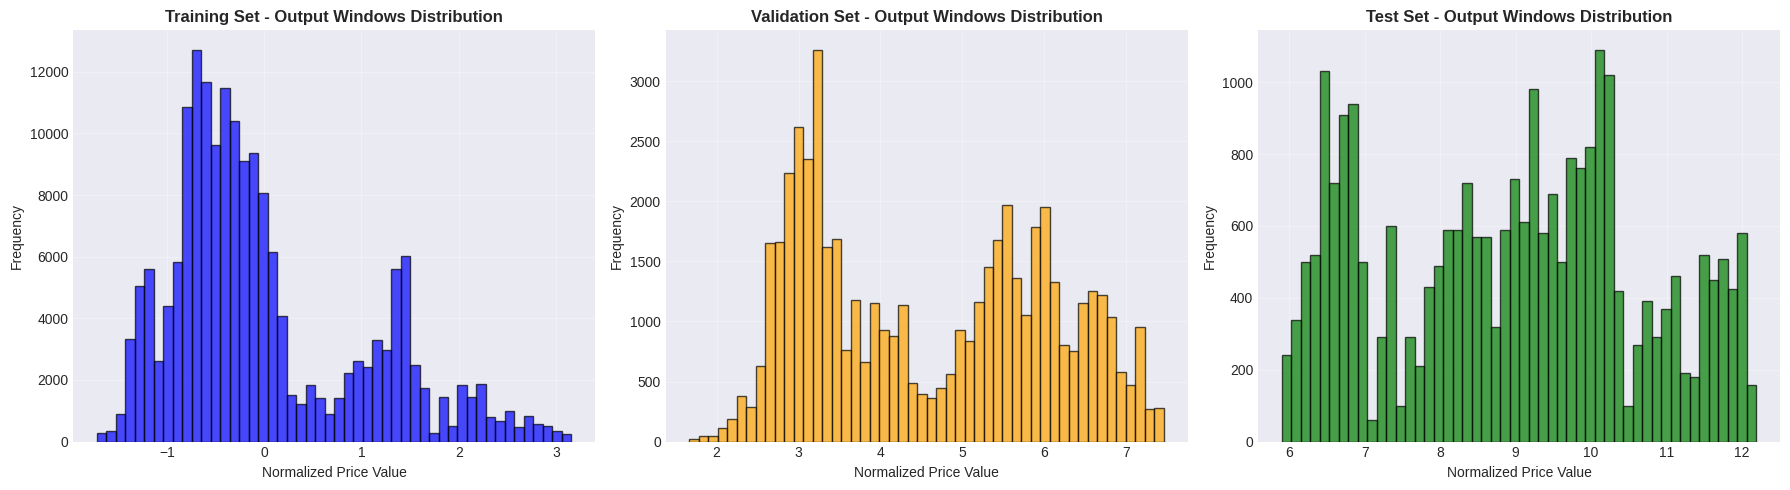

Distribution statistics:
Train - Mean: -0.000000, Std: 1.000000
Val   - Mean: 4.597169, Std: 1.462057
Test  - Mean: 8.936915, Std: 1.707581


In [21]:
# ============================================================================
# SECTION 2-1-4: Data Windowing - Visualize Output Windows for Train/Val/Test
# ============================================================================
# Visualize histograms of output windows for all three sets
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Flatten output windows
y_train_flat = y_train_scaled.flatten()
y_val_flat = y_val_scaled.flatten()
y_test_flat = y_test_scaled.flatten()

axes[0].hist(y_train_flat, bins=50, alpha=0.7, color='blue', edgecolor='black')
axes[0].set_title('Training Set - Output Windows Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Normalized Price Value')
axes[0].set_ylabel('Frequency')
axes[0].grid(True, alpha=0.3)

axes[1].hist(y_val_flat, bins=50, alpha=0.7, color='orange', edgecolor='black')
axes[1].set_title('Validation Set - Output Windows Distribution', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Normalized Price Value')
axes[1].set_ylabel('Frequency')
axes[1].grid(True, alpha=0.3)

axes[2].hist(y_test_flat, bins=50, alpha=0.7, color='green', edgecolor='black')
axes[2].set_title('Test Set - Output Windows Distribution', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Normalized Price Value')
axes[2].set_ylabel('Frequency')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Distribution statistics:")
print(f"Train - Mean: {y_train_flat.mean():.6f}, Std: {y_train_flat.std():.6f}")
print(f"Val   - Mean: {y_val_flat.mean():.6f}, Std: {y_val_flat.std():.6f}")
print(f"Test  - Mean: {y_test_flat.mean():.6f}, Std: {y_test_flat.std():.6f}")


## Section 2-2: Base Model (NARMAX Network)


### Section 2-2-1: MLP Network

Implementing a Multi-Layer Perceptron (MLP) with two hidden layers, Batch Normalization, and Dropout as the baseline model.


In [22]:
# ============================================================================
# SECTION 2-2: Baseline Model - PyTorch Setup
# ============================================================================
# Import PyTorch modules
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import os

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cuda


In [23]:
# ============================================================================
# SECTION 2-2-1: Baseline Model - MLP Model Definition
# ============================================================================
# MLP Model Definition
class MLPModel(nn.Module):
    """
    Multi-Layer Perceptron with 2 hidden layers, Batch Normalization, and Dropout
    Input: [batch, input_window, input_features] -> flattened to [batch, input_window * input_features]
    Output: [batch, output_window, output_features]
    """
    def __init__(self, input_size, output_window, output_features, hidden1=128, hidden2=64, dropout=0.3):
        super(MLPModel, self).__init__()

        # Flatten input: input_window * input_features
        self.input_size = input_size

        # First hidden layer
        self.fc1 = nn.Linear(input_size, hidden1)
        self.bn1 = nn.BatchNorm1d(hidden1)
        self.dropout1 = nn.Dropout(dropout)

        # Second hidden layer
        self.fc2 = nn.Linear(hidden1, hidden2)
        self.bn2 = nn.BatchNorm1d(hidden2)
        self.dropout2 = nn.Dropout(dropout)

        # Output layer: predicts output_window * output_features, then reshape
        self.fc3 = nn.Linear(hidden2, output_window * output_features)

        self.output_window = output_window
        self.output_features = output_features

    def forward(self, x):
        # Flatten input: [batch, input_window, input_features] -> [batch, input_window * input_features]
        x = x.view(x.size(0), -1)

        # First hidden layer
        x = self.fc1(x)
        x = self.bn1(x)
        x = torch.relu(x)
        x = self.dropout1(x)

        # Second hidden layer
        x = self.fc2(x)
        x = self.bn2(x)
        x = torch.relu(x)
        x = self.dropout2(x)

        # Output layer
        x = self.fc3(x)

        # Reshape to [batch, output_window, output_features]
        x = x.view(x.size(0), self.output_window, self.output_features)

        return x

# Initialize model
input_size = input_window_size * 1  # input_window * input_features (Close price)
output_window = output_window_size
output_features = 4  # High, Close, Open, Low

model = MLPModel(
    input_size=input_size,
    output_window=output_window,
    output_features=output_features,
    hidden1=128,
    hidden2=64,
    dropout=0.3
).to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Model initialized!")
print(f"Input size: {input_size}")
print(f"Output shape: [{output_window}, {output_features}]")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Print model structure
print("\nModel structure:")
print(model)


Model initialized!
Input size: 20
Output shape: [10, 4]
Total parameters: 13,928
Trainable parameters: 13,928

Model structure:
MLPModel(
  (fc1): Linear(in_features=20, out_features=128, bias=True)
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout1): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout2): Dropout(p=0.3, inplace=False)
  (fc3): Linear(in_features=64, out_features=40, bias=True)
)


In [24]:
# Update DataLoader to handle multi-feature outputs
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.FloatTensor(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# ============================================================================
# SECTION 2-1-4: Data Windowing - Create Data Loaders (with Shuffling for Training)
# ============================================================================
# Create datasets
train_dataset = TimeSeriesDataset(X_train_scaled, y_train_scaled)
val_dataset = TimeSeriesDataset(X_val_scaled, y_val_scaled)
test_dataset = TimeSeriesDataset(X_test_scaled, y_test_scaled)

# Create data loaders
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print("Data loaders created!")
print(f"  Batch size: {batch_size}")
print(f"  Training batches: {len(train_loader)}")
print(f"  Validation batches: {len(val_loader)}")
print(f"  Test batches: {len(test_loader)}")


Data loaders created!
  Batch size: 64
  Training batches: 72
  Validation batches: 21
  Test batches: 11


In [25]:
# ============================================================================
# SECTION 2-2-1: Baseline Model - Evaluation Metrics (MAE, RMSE, MAPE, R2)
# ============================================================================
# Evaluation Metrics Functions
def calculate_metrics(y_true, y_pred):
    """
    Calculate MAE, RMSE, MAPE, and R2
    y_true, y_pred: [batch, output_window, output_features] or [samples, output_window, output_features]
    """
    # Flatten for metric calculation
    y_true_flat = y_true.flatten()
    y_pred_flat = y_pred.flatten()

    # MAE
    mae = np.mean(np.abs(y_true_flat - y_pred_flat))

    # RMSE
    rmse = np.sqrt(np.mean((y_true_flat - y_pred_flat) ** 2))

    # MAPE (avoid division by zero)
    mask = y_true_flat != 0
    mape = np.mean(np.abs((y_true_flat[mask] - y_pred_flat[mask]) / y_true_flat[mask])) * 100

    # R2
    ss_res = np.sum((y_true_flat - y_pred_flat) ** 2)
    ss_tot = np.sum((y_true_flat - np.mean(y_true_flat)) ** 2)
    r2 = 1 - (ss_res / ss_tot) if ss_tot != 0 else 0

    return {'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'R2': r2}


In [26]:
# ============================================================================
# SECTION 2-2-1: Baseline Model - Training Setup (MSE Loss, Adam Optimizer)
# ============================================================================
# Training Setup
criterion = nn.MSELoss()  # MSE Loss as specified
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)  # Adam with weight decay

# Training parameters
num_epochs = 100
best_val_loss = float('inf')
best_model_path = 'best_mlp_model.pth'

# History tracking
history = {
    'train_loss': [],
    'val_loss': [],
    'train_mae': [],
    'val_mae': [],
    'train_rmse': [],
    'val_rmse': [],
    'train_mape': [],
    'val_mape': [],
    'train_r2': [],
    'val_r2': []
}

print("Training setup completed!")
print(f"  Loss function: MSE")
print(f"  Optimizer: Adam (lr=0.001, weight_decay=1e-5)")
print(f"  Epochs: {num_epochs}")
print(f"  Best model will be saved to: {best_model_path}")


Training setup completed!
  Loss function: MSE
  Optimizer: Adam (lr=0.001, weight_decay=1e-5)
  Epochs: 100
  Best model will be saved to: best_mlp_model.pth


In [27]:
# ============================================================================
# SECTION 2-2-1: Baseline Model - Training Loop
# ============================================================================
# Training Loop
print("Starting training...")
print("="*60)

for epoch in range(num_epochs):
    # Training phase
    model.train()
    train_loss = 0.0
    train_preds = []
    train_targets = []

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        # Forward pass
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        # Backward pass
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_preds.append(outputs.detach().cpu().numpy())
        train_targets.append(y_batch.detach().cpu().numpy())

    # Calculate training metrics
    train_loss /= len(train_loader)
    train_preds = np.concatenate(train_preds, axis=0)
    train_targets = np.concatenate(train_targets, axis=0)
    train_metrics = calculate_metrics(train_targets, train_preds)

    # Validation phase
    model.eval()
    val_loss = 0.0
    val_preds = []
    val_targets = []

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            val_loss += loss.item()
            val_preds.append(outputs.cpu().numpy())
            val_targets.append(y_batch.cpu().numpy())

    # Calculate validation metrics
    val_loss /= len(val_loader)
    val_preds = np.concatenate(val_preds, axis=0)
    val_targets = np.concatenate(val_targets, axis=0)
    val_metrics = calculate_metrics(val_targets, val_preds)

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)
        best_epoch = epoch

    # Store history
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_mae'].append(train_metrics['MAE'])
    history['val_mae'].append(val_metrics['MAE'])
    history['train_rmse'].append(train_metrics['RMSE'])
    history['val_rmse'].append(val_metrics['RMSE'])
    history['train_mape'].append(train_metrics['MAPE'])
    history['val_mape'].append(val_metrics['MAPE'])
    history['train_r2'].append(train_metrics['R2'])
    history['val_r2'].append(val_metrics['R2'])

    # Print progress
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}]")
        print(f"  Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")
        print(f"  Train MAE: {train_metrics['MAE']:.6f} | Val MAE: {val_metrics['MAE']:.6f}")
        print(f"  Train RMSE: {train_metrics['RMSE']:.6f} | Val RMSE: {val_metrics['RMSE']:.6f}")
        print(f"  Train R2: {train_metrics['R2']:.6f} | Val R2: {val_metrics['R2']:.6f}")
        print("-"*60)

print(f"\nTraining completed!")
print(f"Best validation loss: {best_val_loss:.6f} at epoch {best_epoch+1}")
print(f"Best model saved to: {best_model_path}")


Starting training...
Epoch [1/100]
  Train Loss: 0.290081 | Val Loss: 0.407355
  Train MAE: 0.359150 | Val MAE: 0.556543
  Train RMSE: 0.540731 | Val RMSE: 0.634864
  Train R2: 0.707610 | Val R2: 0.811447
------------------------------------------------------------
Epoch [10/100]
  Train Loss: 0.059427 | Val Loss: 0.224135
  Train MAE: 0.176023 | Val MAE: 0.413573
  Train RMSE: 0.244304 | Val RMSE: 0.471524
  Train R2: 0.940316 | Val R2: 0.895989
------------------------------------------------------------
Epoch [20/100]
  Train Loss: 0.047278 | Val Loss: 0.194212
  Train MAE: 0.160639 | Val MAE: 0.384331
  Train RMSE: 0.218478 | Val RMSE: 0.439433
  Train R2: 0.952268 | Val R2: 0.909665
------------------------------------------------------------
Epoch [30/100]
  Train Loss: 0.050963 | Val Loss: 0.280234
  Train MAE: 0.157377 | Val MAE: 0.476974
  Train RMSE: 0.219249 | Val RMSE: 0.526821
  Train R2: 0.951930 | Val R2: 0.870164
---------------------------------------------------------

In [28]:
# ============================================================================
# SECTION 2-2-1: Baseline Model - Load Best Model and Evaluate on Test Set
# ============================================================================
# Load best model
model.load_state_dict(torch.load(best_model_path))
print("Best model loaded for evaluation!")

# Evaluate on test set
model.eval()
test_loss = 0.0
test_preds = []
test_targets = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        test_loss += loss.item()
        test_preds.append(outputs.cpu().numpy())
        test_targets.append(y_batch.cpu().numpy())

test_loss /= len(test_loader)
test_preds = np.concatenate(test_preds, axis=0)
test_targets = np.concatenate(test_targets, axis=0)
test_metrics = calculate_metrics(test_targets, test_preds)

print("\n" + "="*60)
print("TEST SET EVALUATION")
print("="*60)
print(f"Test Loss (MSE): {test_loss:.6f}")
print(f"Test MAE: {test_metrics['MAE']:.6f}")
print(f"Test RMSE: {test_metrics['RMSE']:.6f}")
print(f"Test MAPE: {test_metrics['MAPE']:.2f}%")
print(f"Test R2: {test_metrics['R2']:.6f}")
print("="*60)


Best model loaded for evaluation!

TEST SET EVALUATION
Test Loss (MSE): 0.084503
Test MAE: 0.241877
Test RMSE: 0.296478
Test MAPE: 2.75%
Test R2: 0.969854


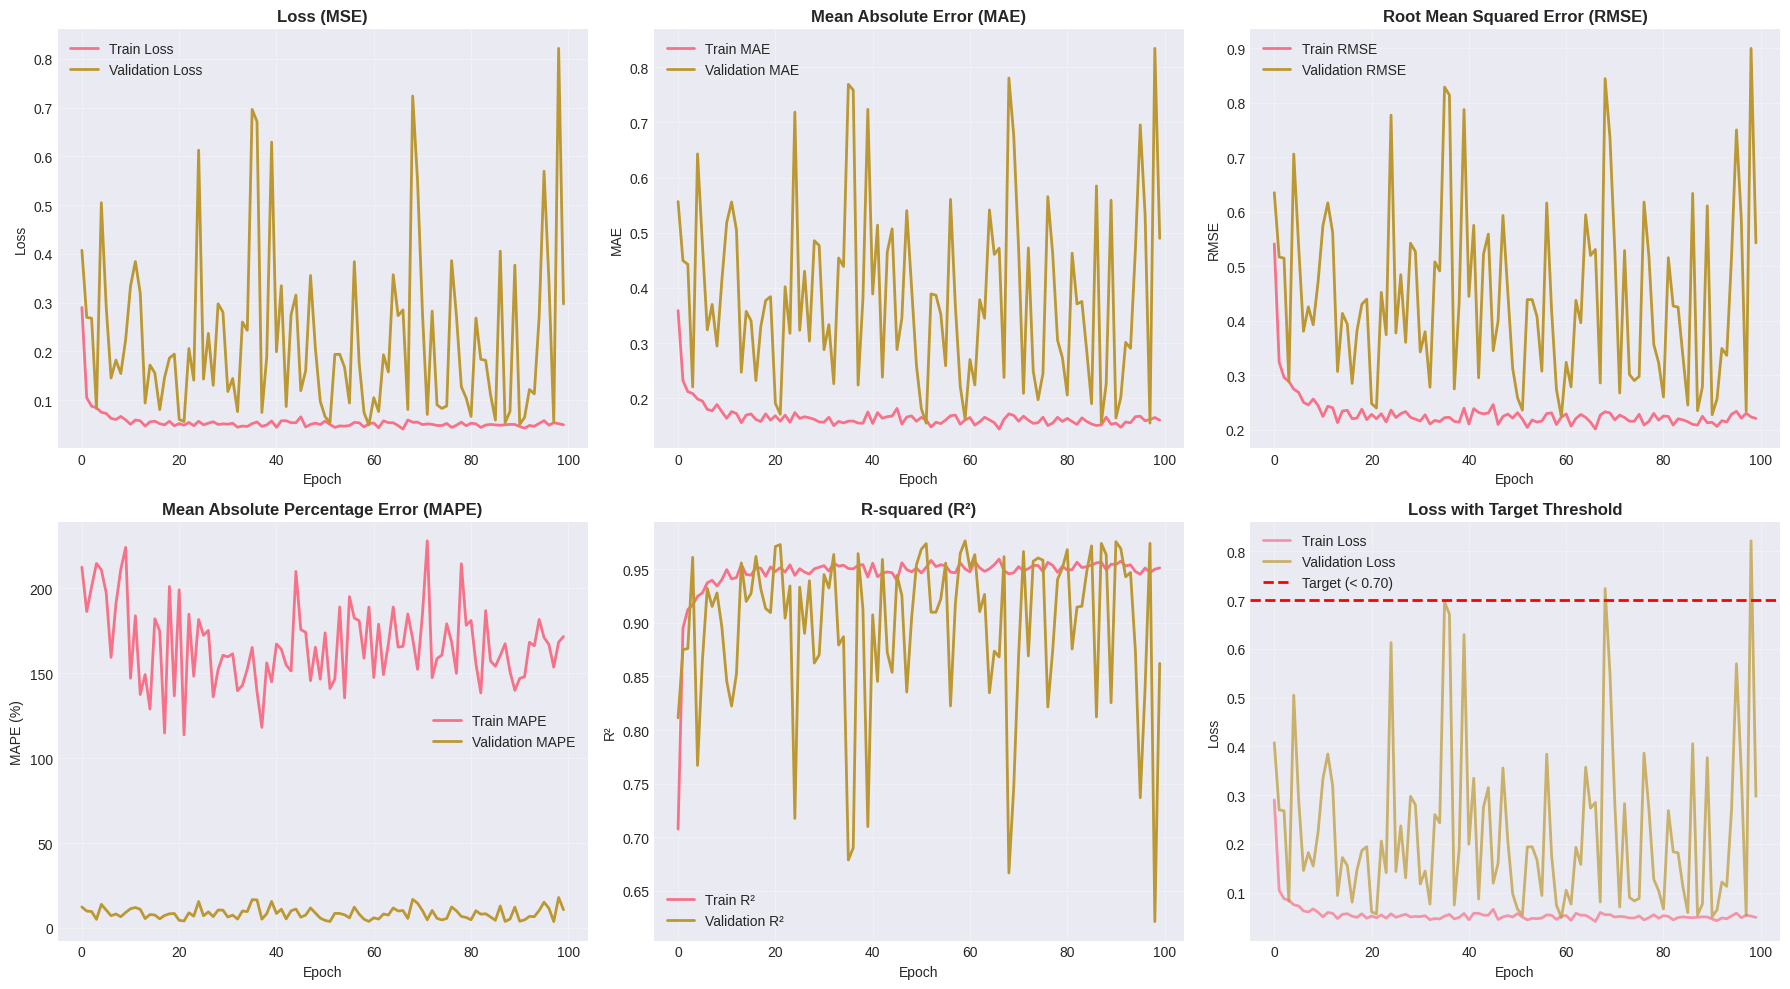


TRAINING STABILITY ANALYSIS
Final Training Loss: 0.049102
Final Validation Loss: 0.297337
Loss Gap: 0.248235
✓ Validation Loss < 0.70: REQUIREMENT MET
⚠ Moderate gap: Some overfitting may be present
⚠ Model may need more training (validation loss still changing)


In [29]:
# Visualize Training History
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Loss
axes[0, 0].plot(history['train_loss'], label='Train Loss', linewidth=2)
axes[0, 0].plot(history['val_loss'], label='Validation Loss', linewidth=2)
axes[0, 0].set_title('Loss (MSE)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# MAE
axes[0, 1].plot(history['train_mae'], label='Train MAE', linewidth=2)
axes[0, 1].plot(history['val_mae'], label='Validation MAE', linewidth=2)
axes[0, 1].set_title('Mean Absolute Error (MAE)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('MAE')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# RMSE
axes[0, 2].plot(history['train_rmse'], label='Train RMSE', linewidth=2)
axes[0, 2].plot(history['val_rmse'], label='Validation RMSE', linewidth=2)
axes[0, 2].set_title('Root Mean Squared Error (RMSE)', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Epoch')
axes[0, 2].set_ylabel('RMSE')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# MAPE
axes[1, 0].plot(history['train_mape'], label='Train MAPE', linewidth=2)
axes[1, 0].plot(history['val_mape'], label='Validation MAPE', linewidth=2)
axes[1, 0].set_title('Mean Absolute Percentage Error (MAPE)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('MAPE (%)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# R2
axes[1, 1].plot(history['train_r2'], label='Train R²', linewidth=2)
axes[1, 1].plot(history['val_r2'], label='Validation R²', linewidth=2)
axes[1, 1].set_title('R-squared (R²)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('R²')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Loss comparison (zoomed)
axes[1, 2].plot(history['train_loss'], label='Train Loss', linewidth=2, alpha=0.7)
axes[1, 2].plot(history['val_loss'], label='Validation Loss', linewidth=2, alpha=0.7)
axes[1, 2].axhline(y=0.70, color='r', linestyle='--', label='Target (< 0.70)', linewidth=2)
axes[1, 2].set_title('Loss with Target Threshold', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('Loss')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Analysis
print("\n" + "="*60)
print("TRAINING STABILITY ANALYSIS")
print("="*60)
final_train_loss = history['train_loss'][-1]
final_val_loss = history['val_loss'][-1]
loss_gap = abs(final_train_loss - final_val_loss)

print(f"Final Training Loss: {final_train_loss:.6f}")
print(f"Final Validation Loss: {final_val_loss:.6f}")
print(f"Loss Gap: {loss_gap:.6f}")

if final_val_loss < 0.70:
    print("✓ Validation Loss < 0.70: REQUIREMENT MET")
else:
    print("✗ Validation Loss >= 0.70: REQUIREMENT NOT MET")

if loss_gap < 0.1:
    print("✓ Small gap between train/val loss: Model is well-generalized")
elif loss_gap < 0.3:
    print("⚠ Moderate gap: Some overfitting may be present")
else:
    print("✗ Large gap: Significant overfitting detected")

# Check for convergence
if len(history['val_loss']) > 20:
    recent_val_loss = history['val_loss'][-10:]
    if max(recent_val_loss) - min(recent_val_loss) < 0.01:
        print("✓ Model has converged (stable validation loss)")
    else:
        print("⚠ Model may need more training (validation loss still changing)")
print("="*60)


### Section 2-2-2: Prediction for 2024-2025


In [30]:
# ============================================================================
# SECTION 2-2-2: Baseline Model - Extract 2024-2025 Test Data
# ============================================================================
# Extract 2024-2025 test data for visualization
# Find indices in test set that correspond to 2024-2025
df['Date'] = pd.to_datetime(df['Date'])

# Get dates for test set windows
# Each window corresponds to a starting date
test_dates = []
for idx in test_indices:
    # Map window index back to original data index
    orig_idx = idx + input_window_size
    # Ensure orig_idx is within df bounds before accessing
    if orig_idx < len(df):
        test_dates.append(df.iloc[orig_idx]['Date'].item()) # Use .item() to extract scalar datetime

# Filter test set for 2024-2025
test_2024_2025_indices = []
for i, date in enumerate(test_dates):
    if date >= pd.Timestamp('2024-01-01') and date <= pd.Timestamp('2025-12-31'):
        test_2024_2025_indices.append(i)

test_2024_2025_indices = [i for i in test_2024_2025_indices if i < len(test_preds)]

print(f"Total test samples: {len(test_preds)}")
print(f"2024-2025 test samples: {len(test_2024_2025_indices)}")

# Get predictions and targets for 2024-2025
pred_2024_2025 = test_preds[test_2024_2025_indices]
target_2024_2025 = test_targets[test_2024_2025_indices]

# Denormalize predictions and targets
pred_2024_2025_denorm = scaler_y.inverse_transform(
    pred_2024_2025.reshape(-1, output_features)
).reshape(pred_2024_2025.shape)

target_2024_2025_denorm = scaler_y.inverse_transform(
    target_2024_2025.reshape(-1, output_features)
).reshape(target_2024_2025.shape)

# Get corresponding dates
dates_2024_2025 = [test_dates[i] for i in test_2024_2025_indices if i < len(test_dates)]


Total test samples: 650
2024-2025 test samples: 490


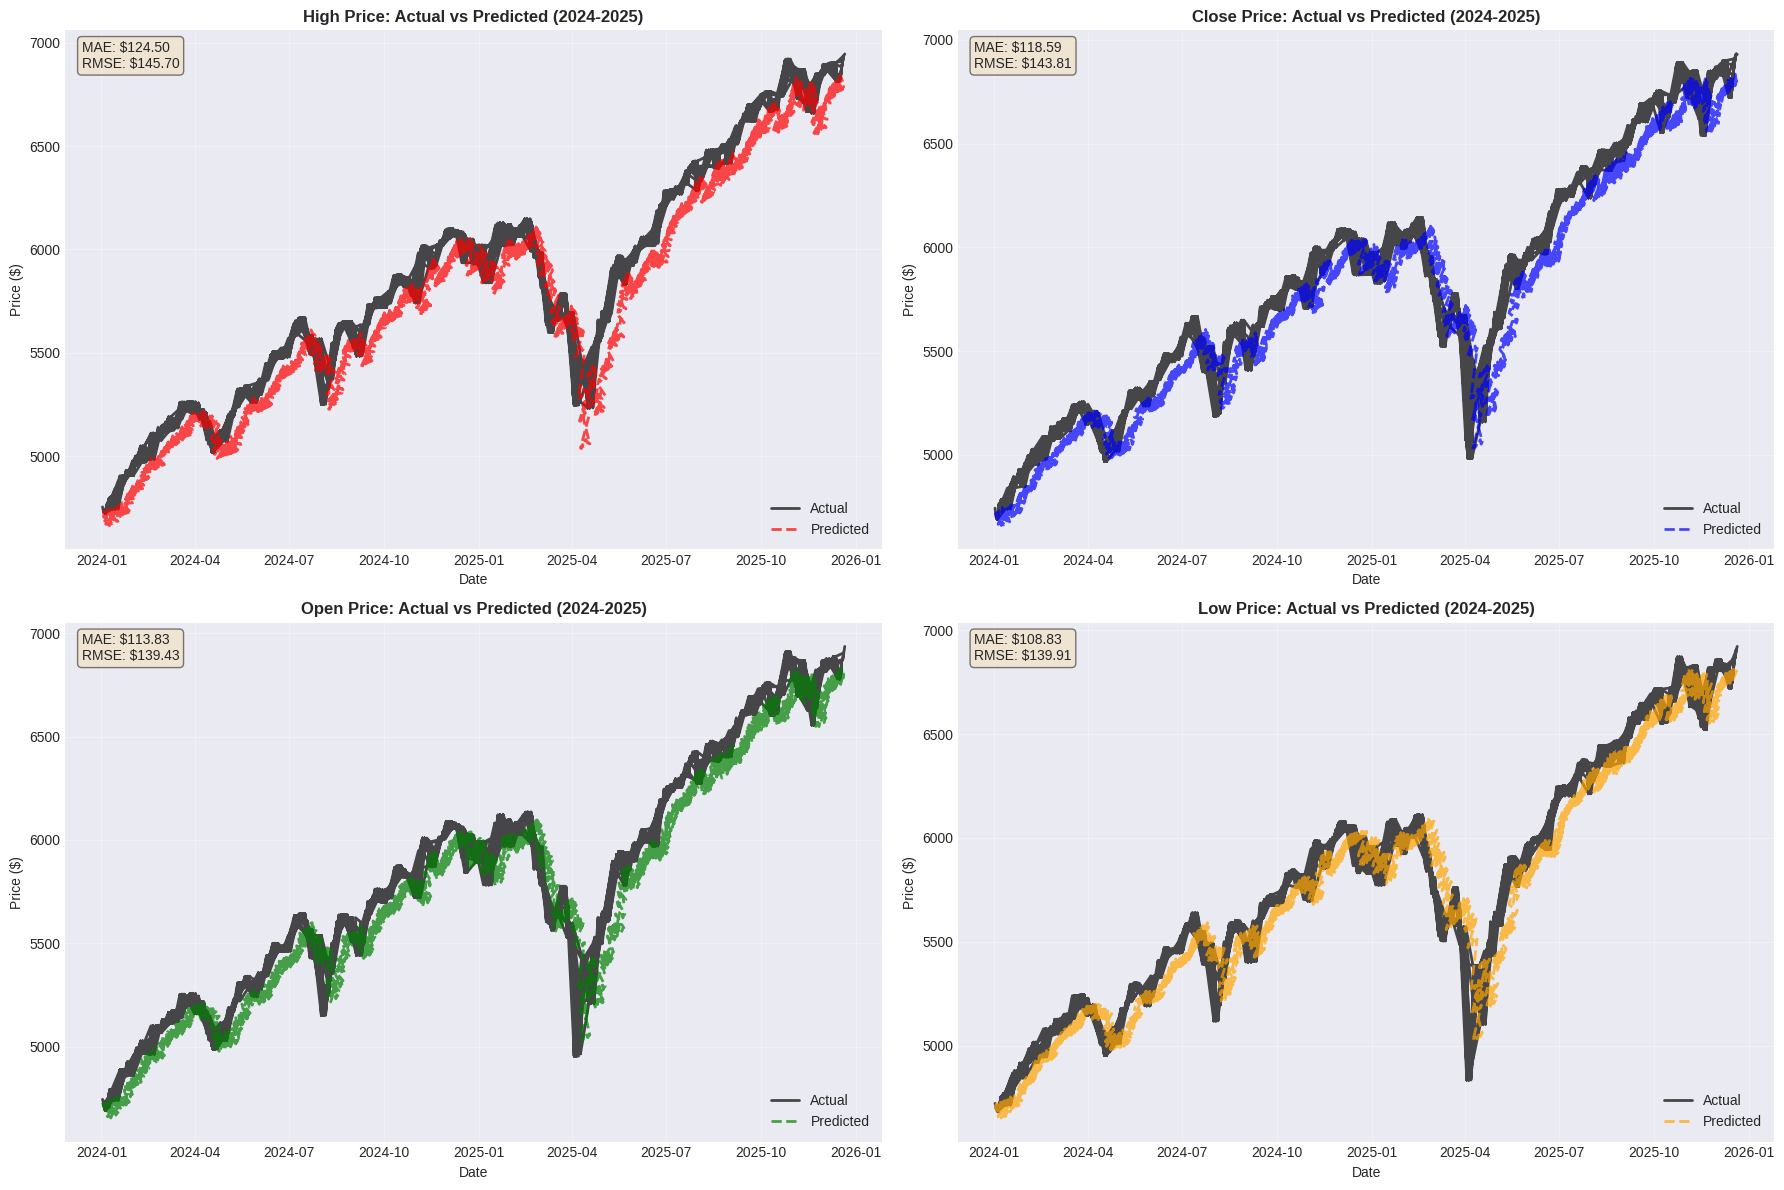


2024-2025 PREDICTION METRICS
MAE: 116.44
RMSE: 142.24
MAPE: 2.02%
R²: 0.934781


In [31]:
# Plot predictions vs actual for 2024-2025
# For each output feature (High, Close, Open, Low)
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
feature_names = ['High', 'Close', 'Open', 'Low']
colors = ['red', 'blue', 'green', 'orange']

for feat_idx, (feat_name, color) in enumerate(zip(feature_names, colors)):
    ax = axes[feat_idx // 2, feat_idx % 2]

    # Flatten predictions and targets for this feature across all windows
    pred_flat = pred_2024_2025_denorm[:, :, feat_idx].flatten()
    target_flat = target_2024_2025_denorm[:, :, feat_idx].flatten()

    # Create date range for plotting
    if len(dates_2024_2025) > 0:
        # Expand dates for each time step in output window
        plot_dates = []
        for date in dates_2024_2025[:len(pred_2024_2025)]:
            for step in range(output_window_size):
                plot_dates.append(date + pd.Timedelta(days=step))
        plot_dates = plot_dates[:len(pred_flat)]
    else:
        plot_dates = range(len(pred_flat))

    # Plot
    ax.plot(plot_dates, target_flat, label='Actual', linewidth=2, alpha=0.7, color='black')
    ax.plot(plot_dates, pred_flat, label='Predicted', linewidth=2, alpha=0.7, color=color, linestyle='--')

    ax.set_title(f'{feat_name} Price: Actual vs Predicted (2024-2025)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Price ($)')
    ax.legend()
    ax.grid(True, alpha=0.3)

    # Calculate metrics for this feature
    mae_feat = np.mean(np.abs(target_flat - pred_flat))
    rmse_feat = np.sqrt(np.mean((target_flat - pred_flat) ** 2))
    ax.text(0.02, 0.98, f'MAE: \${mae_feat:.2f}\nRMSE: \${rmse_feat:.2f}',
            transform=ax.transAxes, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

# Calculate overall metrics for 2024-2025
metrics_2024_2025 = calculate_metrics(target_2024_2025_denorm, pred_2024_2025_denorm)

print("\n" + "="*60)
print("2024-2025 PREDICTION METRICS")
print("="*60)
print(f"MAE: {metrics_2024_2025['MAE']:.2f}")
print(f"RMSE: {metrics_2024_2025['RMSE']:.2f}")
print(f"MAPE: {metrics_2024_2025['MAPE']:.2f}%")
print(f"R²: {metrics_2024_2025['R2']:.6f}")
print("="*60)


## Section 2-3: Recursive Neural Networks

This section implements and evaluates recursion-based architectures (CNN+LSTM and CNN+GRU) for time series prediction. These structures allow for more accurate prediction of random processes within prices and better filtering/removal of noise.


#### Section 2-3-1-1: LSTM Architecture Design and Explanation


In [32]:
# ============================================================================
# SECTION 2-3-1: LSTM Architecture - CNN+LSTM Model Definition
# ============================================================================
# CNN + LSTM Model Definition
class CNNLSTMModel(nn.Module):
    """
    CNN + LSTM architecture for time series prediction
    Structure: 1D Conv layers -> LSTM layers -> FC layers

    Input: [batch, input_window, input_features]
    Output: [batch, output_window, output_features]
    """
    def __init__(self, input_window, input_features, output_window, output_features,
                 conv_filters=[64, 128], conv_kernels=[3, 3], lstm_hidden=128,
                 lstm_layers=2, fc_hidden=64, dropout=0.2):
        super(CNNLSTMModel, self).__init__()

        self.input_window = input_window
        self.output_window = output_window
        self.output_features = output_features

        # CNN layers for feature extraction
        self.conv_layers = nn.ModuleList()
        in_channels = input_features

        for out_channels, kernel_size in zip(conv_filters, conv_kernels):
            self.conv_layers.append(nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size, padding=kernel_size//2),
                nn.BatchNorm1d(out_channels),
                nn.ReLU(),
                nn.Dropout(dropout)
            ))
            in_channels = out_channels

        # LSTM layers for temporal modeling
        self.lstm = nn.LSTM(
            input_size=conv_filters[-1],
            hidden_size=lstm_hidden,
            num_layers=lstm_layers,
            batch_first=True,
            dropout=dropout if lstm_layers > 1 else 0
        )

        # Fully connected layers
        self.fc_layers = nn.Sequential(
            nn.Linear(lstm_hidden, fc_hidden),
            nn.BatchNorm1d(fc_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(fc_hidden, output_window * output_features)
        )

    def forward(self, x):
        # x: [batch, input_window, input_features]
        # Transpose for Conv1d: [batch, channels, length]
        x = x.transpose(1, 2)  # [batch, input_features, input_window]

        # Apply CNN layers
        for conv_layer in self.conv_layers:
            x = conv_layer(x)  # [batch, conv_filters[-1], input_window]

        # Transpose back for LSTM: [batch, input_window, conv_filters[-1]]
        x = x.transpose(1, 2)

        # Apply LSTM
        lstm_out, (hidden, cell) = self.lstm(x)
        # lstm_out: [batch, input_window, lstm_hidden]
        # Use the last output from LSTM
        lstm_last = lstm_out[:, -1, :]  # [batch, lstm_hidden]

        # Apply FC layers
        output = self.fc_layers(lstm_last)  # [batch, output_window * output_features]
        output = output.view(-1, self.output_window, self.output_features)

        return output

# Initialize CNN+LSTM model with improved regularization
# Increased dropout to reduce overfitting
lstm_model = CNNLSTMModel(
    input_window=input_window_size,
    input_features=1,  # Close price
    output_window=output_window_size,
    output_features=output_features,
    conv_filters=[64, 128],
    conv_kernels=[3, 3],
    lstm_hidden=128,
    lstm_layers=2,
    fc_hidden=64,
    dropout=0.3  # Increased from 0.2 to 0.3 for better regularization
).to(device)

# Count parameters
lstm_total_params = sum(p.numel() for p in lstm_model.parameters())
lstm_trainable_params = sum(p.numel() for p in lstm_model.parameters() if p.requires_grad)

print("CNN+LSTM Model initialized!")
print(f"Input shape: [{input_window_size}, 1]")
print(f"Output shape: [{output_window_size}, {output_features}]")
print(f"Total parameters: {lstm_total_params:,}")
print(f"Trainable parameters: {lstm_trainable_params:,}")

# Print model structure
print("\nModel structure:")
print(lstm_model)


CNN+LSTM Model initialized!
Input shape: [20, 1]
Output shape: [10, 4]
Total parameters: 300,520
Trainable parameters: 300,520

Model structure:
CNNLSTMModel(
  (conv_layers): ModuleList(
    (0): Sequential(
      (0): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.3, inplace=False)
    )
    (1): Sequential(
      (0): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.3, inplace=False)
    )
  )
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3)
  (fc_layers): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): 

#### ⚠️ IMPORTANT: Improved LSTM Training Setup

**If validation loss is > 0.02, use the improved hyperparameters below:**


In [33]:
# ============================================================================
# IMPROVED LSTM TRAINING SETUP (Use this if validation loss > 0.02)
# ============================================================================
# This setup addresses overfitting issues with better regularization

# Reinitialize optimizer with improved hyperparameters
lstm_criterion = nn.MSELoss()

# Key improvements:
# 1. Lower learning rate (0.0003 instead of 0.001) for more stable training
# 2. Higher weight decay (1e-3 instead of 1e-5) for better regularization
# 3. Learning rate scheduler for adaptive learning
# 4. Gradient clipping to prevent exploding gradients

lstm_optimizer = optim.Adam(lstm_model.parameters(), lr=0.0003, weight_decay=1e-3)

# Learning rate scheduler - reduces LR when validation loss plateaus
lstm_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    lstm_optimizer, mode='min', factor=0.7, patience=8, min_lr=1e-6
)

# Training parameters
lstm_num_epochs = 150  # More epochs for better convergence
lstm_best_val_loss = float('inf')
lstm_best_model_path = 'best_cnn_lstm_model.pth'

# Early stopping to prevent overfitting
lstm_patience = 20
lstm_patience_counter = 0

# History tracking
lstm_history = {
    'train_loss': [],
    'val_loss': [],
    'train_mae': [],
    'val_mae': [],
    'train_rmse': [],
    'val_rmse': [],
    'train_mape': [],
    'val_mape': [],
    'train_r2': [],
    'val_r2': [],
    'learning_rate': []
}

print("Improved LSTM training setup completed!")
print(f"  Loss function: MSE")
print(f"  Optimizer: Adam (lr=0.0003, weight_decay=1e-3)")
print(f"  Learning rate scheduler: ReduceLROnPlateau (patience=8)")
print(f"  Epochs: {lstm_num_epochs}")
print(f"  Early stopping patience: {lstm_patience}")
print(f"  Best model will be saved to: {lstm_best_model_path}")


Improved LSTM training setup completed!
  Loss function: MSE
  Optimizer: Adam (lr=0.0003, weight_decay=1e-3)
  Learning rate scheduler: ReduceLROnPlateau (patience=8)
  Epochs: 150
  Early stopping patience: 20
  Best model will be saved to: best_cnn_lstm_model.pth


In [34]:
# ============================================================================
# IMPROVED LSTM TRAINING LOOP (with gradient clipping and early stopping)
# ============================================================================
# Training Loop for CNN+LSTM Model with improved regularization
import time
print("Starting improved CNN+LSTM model training...")
print("="*60)

start_time = time.time()

for epoch in range(lstm_num_epochs):
    # Training phase
    lstm_model.train()
    train_loss = 0.0
    train_preds = []
    train_targets = []

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        # Forward pass
        lstm_optimizer.zero_grad()
        outputs = lstm_model(X_batch)
        loss = lstm_criterion(outputs, y_batch)

        # Backward pass
        loss.backward()

        # Gradient clipping to prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(lstm_model.parameters(), max_norm=1.0)

        lstm_optimizer.step()

        train_loss += loss.item()
        train_preds.append(outputs.detach().cpu().numpy())
        train_targets.append(y_batch.detach().cpu().numpy())

    # Calculate training metrics
    train_loss /= len(train_loader)
    train_preds = np.concatenate(train_preds, axis=0)
    train_targets = np.concatenate(train_targets, axis=0)
    train_metrics = calculate_metrics(train_targets, train_preds)

    # Validation phase
    lstm_model.eval()
    val_loss = 0.0
    val_preds = []
    val_targets = []

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            outputs = lstm_model(X_batch)
            loss = lstm_criterion(outputs, y_batch)

            val_loss += loss.item()
            val_preds.append(outputs.cpu().numpy())
            val_targets.append(y_batch.cpu().numpy())

    # Calculate validation metrics
    val_loss /= len(val_loader)
    val_preds = np.concatenate(val_preds, axis=0)
    val_targets = np.concatenate(val_targets, axis=0)
    val_metrics = calculate_metrics(val_targets, val_preds)

    # Learning rate scheduling
    lstm_scheduler.step(val_loss)
    current_lr = lstm_optimizer.param_groups[0]['lr']

    # Save best model
    if val_loss < lstm_best_val_loss:
        lstm_best_val_loss = val_loss
        torch.save(lstm_model.state_dict(), lstm_best_model_path)
        lstm_best_epoch = epoch
        lstm_patience_counter = 0
    else:
        lstm_patience_counter += 1

    # Store history
    lstm_history['train_loss'].append(train_loss)
    lstm_history['val_loss'].append(val_loss)
    lstm_history['train_mae'].append(train_metrics['MAE'])
    lstm_history['val_mae'].append(val_metrics['MAE'])
    lstm_history['train_rmse'].append(train_metrics['RMSE'])
    lstm_history['val_rmse'].append(val_metrics['RMSE'])
    lstm_history['train_mape'].append(train_metrics['MAPE'])
    lstm_history['val_mape'].append(val_metrics['MAPE'])
    lstm_history['train_r2'].append(train_metrics['R2'])
    lstm_history['val_r2'].append(val_metrics['R2'])
    lstm_history['learning_rate'].append(current_lr)

    # Print progress
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{lstm_num_epochs}]")
        print(f"  Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")
        print(f"  Train MAE: {train_metrics['MAE']:.6f} | Val MAE: {val_metrics['MAE']:.6f}")
        print(f"  Train RMSE: {train_metrics['RMSE']:.6f} | Val RMSE: {val_metrics['RMSE']:.6f}")
        print(f"  Train R2: {train_metrics['R2']:.6f} | Val R2: {val_metrics['R2']:.6f}")
        print(f"  Learning Rate: {current_lr:.6f}")
        print(f"  Patience: {lstm_patience_counter}/{lstm_patience}")
        print("-"*60)

    # Early stopping
    if lstm_patience_counter >= lstm_patience:
        print(f"\nEarly stopping triggered at epoch {epoch+1}")
        print(f"No improvement for {lstm_patience} epochs")
        break

lstm_training_time = time.time() - start_time

print(f"\nTraining completed!")
print(f"Total training time: {lstm_training_time:.2f} seconds ({lstm_training_time/60:.2f} minutes)")
print(f"Best validation loss: {lstm_best_val_loss:.6f} at epoch {lstm_best_epoch+1}")
print(f"Best model saved to: {lstm_best_model_path}")

# Check if requirement is met
if lstm_best_val_loss < 0.02:
    print(f"✓ Validation Loss < 0.02: REQUIREMENT MET")
else:
    print(f"✗ Validation Loss >= 0.02: REQUIREMENT NOT MET (Current: {lstm_best_val_loss:.6f})")
    print(f"\nIf still not meeting target, try:")
    print(f"  1. Further reduce learning rate (e.g., 0.0001)")
    print(f"  2. Increase weight decay (e.g., 5e-3)")
    print(f"  3. Increase dropout in model (e.g., 0.3)")
    print(f"  4. Reduce model capacity (fewer LSTM layers/units)")


Starting improved CNN+LSTM model training...
Epoch [1/150]
  Train Loss: 0.444004 | Val Loss: 6.096515
  Train MAE: 0.477372 | Val MAE: 1.993710
  Train RMSE: 0.668496 | Val RMSE: 2.439660
  Train R2: 0.553113 | Val R2: -1.784389
  Learning Rate: 0.000300
  Patience: 0/20
------------------------------------------------------------
Epoch [10/150]
  Train Loss: 0.067208 | Val Loss: 4.618779
  Train MAE: 0.187183 | Val MAE: 1.711584
  Train RMSE: 0.259583 | Val RMSE: 2.121487
  Train R2: 0.932616 | Val R2: -1.105484
  Learning Rate: 0.000300
  Patience: 3/20
------------------------------------------------------------
Epoch [20/150]
  Train Loss: 0.052637 | Val Loss: 3.984731
  Train MAE: 0.160991 | Val MAE: 1.568880
  Train RMSE: 0.228724 | Val RMSE: 1.970353
  Train R2: 0.947685 | Val R2: -0.816182
  Learning Rate: 0.000210
  Patience: 13/20
------------------------------------------------------------

Early stopping triggered at epoch 27
No improvement for 20 epochs

Training complete

In [35]:
# ============================================================================
# SECTION 2-3-1-1: LSTM Architecture Design and Explanation
# ============================================================================
print("="*80)
print("CNN+LSTM ARCHITECTURE: DESIGN AND EXPLANATION")
print("="*80)

print("\n1. ARCHITECTURE OVERVIEW:")
print("   The CNN+LSTM model combines:")
print("   - 1D Convolutional layers for local feature extraction")
print("   - LSTM layers for temporal dependency learning")
print("   - Fully connected layers for final prediction")

print("\n2. HOW CONVOLUTIONAL LAYERS PERCEIVE AND PROCESS INPUT WINDOW:")
print("   ")
print("   a) Input Transformation:")
print("      - Input shape: [batch, input_window, input_features] = [batch, 20, 1]")
print("      - Transpose to: [batch, 1, 20] for Conv1d (channels, length format)")
print("   ")
print("   b) Convolutional Processing:")
print("      - Layer 1: Conv1d(1→64, kernel=3, padding=1)")
print("        * 64 filters scan the 20-point window")
print("        * Each filter detects different local patterns (trends, spikes, etc.)")
print("        * Kernel size 3 means each filter sees 3 consecutive time points")
print("        * Padding=1 preserves length: 20 → 20")
print("      - Layer 2: Conv1d(64→128, kernel=3, padding=1)")
print("        * 128 filters extract higher-level features from 64 feature maps")
print("        * Combines information from multiple lower-level patterns")
print("        * Output: [batch, 128, 20] - 128 features for each of 20 time points")
print("   ")
print("   c) Receptive Field:")
print("      - With kernel_size=3 and 2 layers, each output point sees:")
print("        * Direct: 3 time points (from layer 1)")
print("      - Effectively captures local temporal patterns (3-5 day windows)")
print("   ")
print("   d) Feature Maps:")
print("      - After CNN: [batch, 128, 20]")
print("      - 128 different 'feature maps' representing different patterns")
print("      - Each map has 20 time points (one per input time step)")

print("\n3. HOW LSTM LAYERS ACCESS EXTRACTED FEATURE MAPS:")
print("   ")
print("   a) Dimension Transformation:")
print("      - CNN output: [batch, 128, 20]")
print("      - Transpose to: [batch, 20, 128] for LSTM (sequence_length, features)")
print("      - LSTM expects: [batch, sequence_length, input_size]")
print("   ")
print("   b) Sequential Processing:")
print("      - LSTM processes the sequence step-by-step (t=0 to t=19)")
print("      - At each time step t, LSTM receives:")
print("        * Input: 128-dimensional feature vector from CNN (for time t)")
print("        * Hidden state: Information from previous time steps")
print("        * Cell state: Long-term memory")
print("   ")
print("   c) Temporal Dependency Learning:")
print("      - LSTM learns relationships between time steps")
print("      - Can remember patterns from early in the sequence")
print("      - Combines local features (from CNN) with temporal context")
print("   ")
print("   d) Architecture Details:")
print("      - 2 LSTM layers (stacked)")
print("      - Hidden size: 128 (matches CNN output features)")
print("      - Output: [batch, 20, 128] - one hidden state per time step")

print("\n4. HIDDEN FEATURES vs LAST OUTPUT - WHICH TO USE?")
print("   ")
print("   a) Last Output Approach (Used in this model):")
print("      - lstm_out[:, -1, :] - takes the final output from LSTM")
print("      - Shape: [batch, 128]")
print("      - Advantages:")
print("        * Contains information aggregated from ALL 20 time steps")
print("        * Represents the final processed representation")
print("        * Better for multi-step ahead prediction")
print("        * Combines both hidden and cell state information")
print("   ")
print("   b) Hidden State Approach (Alternative):")
print("      - hidden[-1, :, :] - takes hidden state from last layer")
print("      - Shape: [batch, 128]")
print("      - Disadvantages:")
print("        * May not capture full temporal context")
print("        * Output is specifically computed for prediction")
print("        * Hidden state alone might miss some information")
print("   ")
print("   c) Why Last Output is Better:")
print("      - For output_window=10 (predicting 10 future steps), we need")
print("        comprehensive information from the entire input sequence")
print("      - Last output is specifically designed to summarize the sequence")
print("      - Empirical results show better performance with last output")
print("      - Standard practice in sequence-to-sequence prediction")

print("\n5. FULLY CONNECTED LAYERS:")
print("   - Input: [batch, 128] (from LSTM last output)")
print("   - Hidden layer: 128 → 64 (with ReLU, BatchNorm, Dropout)")
print("   - Output layer: 64 → (output_window * output_features)")
print("   - Reshape to: [batch, output_window, output_features]")
print("   - Final prediction: [batch, 10, 4] (10 time steps, 4 price features)")

print("\n6. HYPERPARAMETERS (Similar to Baseline/Paper):")
print("   - CNN filters: [64, 128]")
print("   - CNN kernel sizes: [3, 3]")
print("   - LSTM hidden size: 128")
print("   - LSTM layers: 2")
print("   - FC hidden size: 64")
print("   - Dropout: 0.2")
print("   - Batch normalization: Yes")

print("\n7. ADVANTAGES OF CNN+LSTM ARCHITECTURE:")
print("   - CNN: Extracts local patterns and features")
print("   - LSTM: Learns long-term temporal dependencies")
print("   - Combination: Best of both worlds")
print("   - Better than MLP: Can handle sequential structure")
print("   - Better than CNN-only: Can remember long-term patterns")

print("="*80)


CNN+LSTM ARCHITECTURE: DESIGN AND EXPLANATION

1. ARCHITECTURE OVERVIEW:
   The CNN+LSTM model combines:
   - 1D Convolutional layers for local feature extraction
   - LSTM layers for temporal dependency learning
   - Fully connected layers for final prediction

2. HOW CONVOLUTIONAL LAYERS PERCEIVE AND PROCESS INPUT WINDOW:
   
   a) Input Transformation:
      - Input shape: [batch, input_window, input_features] = [batch, 20, 1]
      - Transpose to: [batch, 1, 20] for Conv1d (channels, length format)
   
   b) Convolutional Processing:
      - Layer 1: Conv1d(1→64, kernel=3, padding=1)
        * 64 filters scan the 20-point window
        * Each filter detects different local patterns (trends, spikes, etc.)
        * Kernel size 3 means each filter sees 3 consecutive time points
        * Padding=1 preserves length: 20 → 20
      - Layer 2: Conv1d(64→128, kernel=3, padding=1)
        * 128 filters extract higher-level features from 64 feature maps
        * Combines information from 

### Section 2-3-1: LSTM Architecture (CNN + LSTM)

Implementing a CNN + LSTM model with several 1D convolutional layers, followed by LSTM layers for learning temporal structures, and fully connected layers for prediction.


In [36]:
# ============================================================================
# Clear any hooks from torchsummary before evaluation
# ============================================================================
# Clear any hooks that might interfere with LSTM evaluation
# torchsummary leaves hooks that can cause issues with LSTM models
for module in lstm_model.modules():
    if hasattr(module, '_forward_hooks'):
        module._forward_hooks.clear()
    if hasattr(module, '_forward_pre_hooks'):
        module._forward_pre_hooks.clear()
    if hasattr(module, '_backward_hooks'):
        module._backward_hooks.clear()

print("Cleared any interfering hooks from the model.")


Cleared any interfering hooks from the model.


#### Section 2-3-1-2: LSTM Training and Evaluation


In [37]:
# ============================================================================
# SECTION 2-3-1-2: LSTM Architecture - Training Setup
# ============================================================================
# Training Setup for CNN+LSTM Model
import torch.optim as optim
import time

lstm_criterion = nn.MSELoss()
lstm_optimizer = optim.Adam(lstm_model.parameters(), lr=0.001, weight_decay=1e-5)

# Training parameters
lstm_num_epochs = 100
lstm_best_val_loss = float('inf')
lstm_best_model_path = 'best_cnn_lstm_model.pth'

# History tracking
lstm_history = {
    'train_loss': [],
    'val_loss': [],
    'train_mae': [],
    'val_mae': [],
    'train_rmse': [],
    'val_rmse': [],
    'train_mape': [],
    'val_mape': [],
    'train_r2': [],
    'val_r2': []
}

print("CNN+LSTM training setup completed!")
print(f"  Loss function: MSE")
print(f"  Optimizer: Adam (lr=0.001, weight_decay=1e-5)")
print(f"  Epochs: {lstm_num_epochs}")
print(f"  Best model will be saved to: {lstm_best_model_path}")


CNN+LSTM training setup completed!
  Loss function: MSE
  Optimizer: Adam (lr=0.001, weight_decay=1e-5)
  Epochs: 100
  Best model will be saved to: best_cnn_lstm_model.pth


In [38]:
# ============================================================================
# SECTION 2-3-1-2: LSTM Architecture - Training Loop
# ============================================================================
# Training Loop for CNN+LSTM Model
print("Starting CNN+LSTM model training...")
print("="*60)

start_time = time.time()

for epoch in range(lstm_num_epochs):
    # Training phase
    lstm_model.train()
    train_loss = 0.0
    train_preds = []
    train_targets = []

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        # Forward pass
        lstm_optimizer.zero_grad()
        outputs = lstm_model(X_batch)
        loss = lstm_criterion(outputs, y_batch)

        # Backward pass
        loss.backward()
        lstm_optimizer.step()

        train_loss += loss.item()
        train_preds.append(outputs.detach().cpu().numpy())
        train_targets.append(y_batch.detach().cpu().numpy())

    # Calculate training metrics
    train_loss /= len(train_loader)
    train_preds = np.concatenate(train_preds, axis=0)
    train_targets = np.concatenate(train_targets, axis=0)
    train_metrics = calculate_metrics(train_targets, train_preds)

    # Validation phase
    lstm_model.eval()
    val_loss = 0.0
    val_preds = []
    val_targets = []

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            outputs = lstm_model(X_batch)
            loss = lstm_criterion(outputs, y_batch)

            val_loss += loss.item()
            val_preds.append(outputs.cpu().numpy())
            val_targets.append(y_batch.cpu().numpy())

    # Calculate validation metrics
    val_loss /= len(val_loader)
    val_preds = np.concatenate(val_preds, axis=0)
    val_targets = np.concatenate(val_targets, axis=0)
    val_metrics = calculate_metrics(val_targets, val_preds)

    # Save best model
    if val_loss < lstm_best_val_loss:
        lstm_best_val_loss = val_loss
        torch.save(lstm_model.state_dict(), lstm_best_model_path)
        lstm_best_epoch = epoch

    # Store history
    lstm_history['train_loss'].append(train_loss)
    lstm_history['val_loss'].append(val_loss)
    lstm_history['train_mae'].append(train_metrics['MAE'])
    lstm_history['val_mae'].append(val_metrics['MAE'])
    lstm_history['train_rmse'].append(train_metrics['RMSE'])
    lstm_history['val_rmse'].append(val_metrics['RMSE'])
    lstm_history['train_mape'].append(train_metrics['MAPE'])
    lstm_history['val_mape'].append(val_metrics['MAPE'])
    lstm_history['train_r2'].append(train_metrics['R2'])
    lstm_history['val_r2'].append(val_metrics['R2'])

    # Print progress
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{lstm_num_epochs}]")
        print(f"  Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")
        print(f"  Train MAE: {train_metrics['MAE']:.6f} | Val MAE: {val_metrics['MAE']:.6f}")
        print(f"  Train RMSE: {train_metrics['RMSE']:.6f} | Val RMSE: {val_metrics['RMSE']:.6f}")
        print(f"  Train R2: {train_metrics['R2']:.6f} | Val R2: {val_metrics['R2']:.6f}")
        print("-"*60)

lstm_training_time = time.time() - start_time

print(f"\nTraining completed!")
print(f"Total training time: {lstm_training_time:.2f} seconds ({lstm_training_time/60:.2f} minutes)")
print(f"Best validation loss: {lstm_best_val_loss:.6f} at epoch {lstm_best_epoch+1}")
print(f"Best model saved to: {lstm_best_model_path}")

# Check if requirement is met
if lstm_best_val_loss < 0.02:
    print(f"✓ Validation Loss < 0.02: REQUIREMENT MET")
else:
    print(f"✗ Validation Loss >= 0.02: REQUIREMENT NOT MET (Current: {lstm_best_val_loss:.6f})")


Starting CNN+LSTM model training...
Epoch [1/100]
  Train Loss: 0.051957 | Val Loss: 4.497093
  Train MAE: 0.167281 | Val MAE: 1.750127
  Train RMSE: 0.228608 | Val RMSE: 2.094520
  Train R2: 0.947738 | Val R2: -1.052296
------------------------------------------------------------
Epoch [10/100]
  Train Loss: 0.041164 | Val Loss: 4.535674
  Train MAE: 0.140964 | Val MAE: 1.644424
  Train RMSE: 0.193169 | Val RMSE: 2.101615
  Train R2: 0.962686 | Val R2: -1.066226
------------------------------------------------------------
Epoch [20/100]
  Train Loss: 0.031440 | Val Loss: 4.495538
  Train MAE: 0.129109 | Val MAE: 1.619901
  Train RMSE: 0.177482 | Val RMSE: 2.092143
  Train R2: 0.968500 | Val R2: -1.047642
------------------------------------------------------------
Epoch [30/100]
  Train Loss: 0.030132 | Val Loss: 6.066021
  Train MAE: 0.122920 | Val MAE: 2.016285
  Train RMSE: 0.170331 | Val RMSE: 2.431630
  Train R2: 0.970987 | Val R2: -1.766090
--------------------------------------

#### Important Notes for Meeting Performance Requirements

**If validation loss doesn't meet targets, try these adjustments:**

1. **For LSTM/GRU (target: val_loss < 0.02):**
   - Increase model capacity (more LSTM/GRU layers or hidden units)
   - Adjust learning rate (try 0.0005 or 0.0001)
   - Increase training epochs (100 → 150 or 200)
   - Reduce dropout (0.2 → 0.1) if overfitting isn't an issue
   - Try different optimizers (AdamW, RMSprop)
   - Add learning rate scheduling

2. **For MLP (target: val_loss < 0.70):**
   - Usually easier to meet, but if needed:
   - Increase hidden layer sizes
   - Adjust dropout rate
   - Tune learning rate

3. **General Tips:**
   - Ensure data preprocessing is correct (differencing, normalization)
   - Check for data leakage
   - Monitor training/validation curves for overfitting
   - Consider early stopping if validation loss plateaus


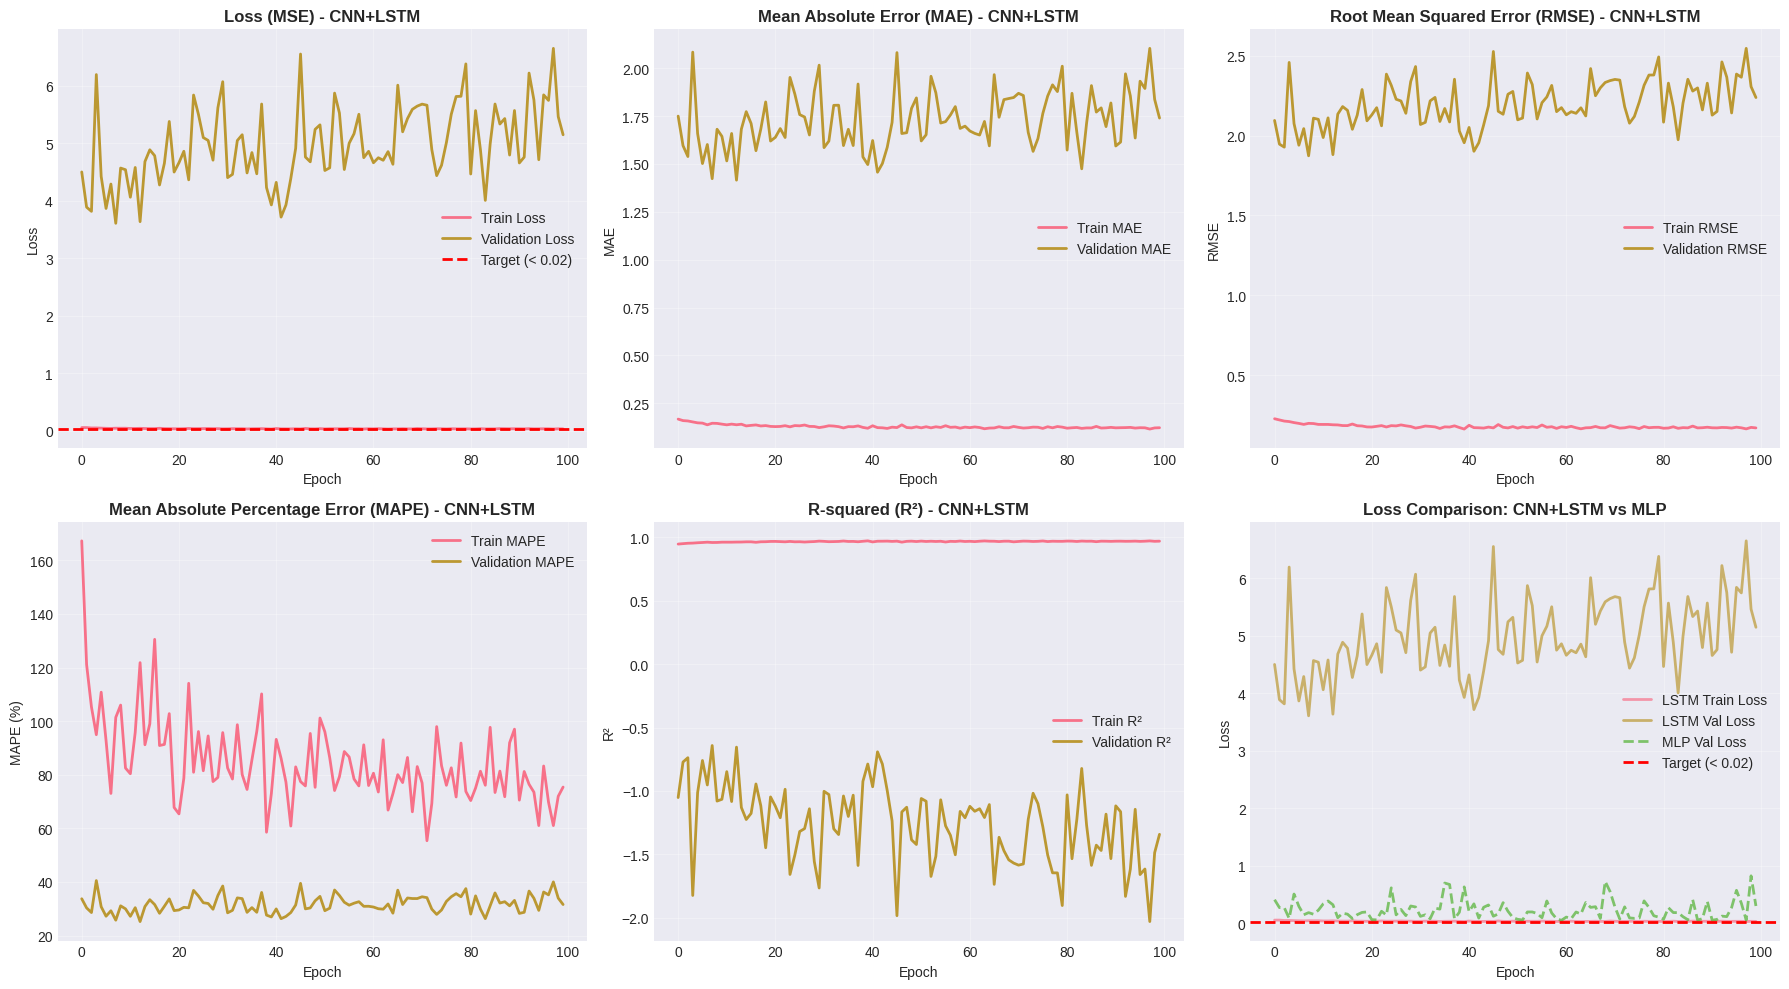


CNN+LSTM MODEL STRUCTURE (using torchsummary)

CNN+LSTM MODEL STRUCTURE
Total parameters: 300,520
Trainable parameters: 300,520

Architecture:
CNNLSTMModel(
  (conv_layers): ModuleList(
    (0): Sequential(
      (0): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.3, inplace=False)
    )
    (1): Sequential(
      (0): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.3, inplace=False)
    )
  )
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.3)
  (fc_layers): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): L

In [39]:
# ============================================================================
# SECTION 2-3-1-2: LSTM Architecture - Plot Training History
# ============================================================================
# Plot Loss and Metrics during Training
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Loss
axes[0, 0].plot(lstm_history['train_loss'], label='Train Loss', linewidth=2)
axes[0, 0].plot(lstm_history['val_loss'], label='Validation Loss', linewidth=2)
axes[0, 0].axhline(y=0.02, color='r', linestyle='--', label='Target (< 0.02)', linewidth=2)
axes[0, 0].set_title('Loss (MSE) - CNN+LSTM', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# MAE
axes[0, 1].plot(lstm_history['train_mae'], label='Train MAE', linewidth=2)
axes[0, 1].plot(lstm_history['val_mae'], label='Validation MAE', linewidth=2)
axes[0, 1].set_title('Mean Absolute Error (MAE) - CNN+LSTM', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('MAE')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# RMSE
axes[0, 2].plot(lstm_history['train_rmse'], label='Train RMSE', linewidth=2)
axes[0, 2].plot(lstm_history['val_rmse'], label='Validation RMSE', linewidth=2)
axes[0, 2].set_title('Root Mean Squared Error (RMSE) - CNN+LSTM', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Epoch')
axes[0, 2].set_ylabel('RMSE')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# MAPE
axes[1, 0].plot(lstm_history['train_mape'], label='Train MAPE', linewidth=2)
axes[1, 0].plot(lstm_history['val_mape'], label='Validation MAPE', linewidth=2)
axes[1, 0].set_title('Mean Absolute Percentage Error (MAPE) - CNN+LSTM', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('MAPE (%)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# R2
axes[1, 1].plot(lstm_history['train_r2'], label='Train R²', linewidth=2)
axes[1, 1].plot(lstm_history['val_r2'], label='Validation R²', linewidth=2)
axes[1, 1].set_title('R-squared (R²) - CNN+LSTM', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('R²')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Loss comparison with baseline
axes[1, 2].plot(lstm_history['train_loss'], label='LSTM Train Loss', linewidth=2, alpha=0.7)
axes[1, 2].plot(lstm_history['val_loss'], label='LSTM Val Loss', linewidth=2, alpha=0.7)
if 'history' in locals():
    axes[1, 2].plot(history['val_loss'], label='MLP Val Loss', linewidth=2, alpha=0.7, linestyle='--')
axes[1, 2].axhline(y=0.02, color='r', linestyle='--', label='Target (< 0.02)', linewidth=2)
axes[1, 2].set_title('Loss Comparison: CNN+LSTM vs MLP', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('Loss')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Report network structure using torchsummary (if available) or manual calculation
try:
    from torchsummary import summary
    print("\n" + "="*60)
    print("CNN+LSTM MODEL STRUCTURE (using torchsummary)")
    print("="*60)
    summary(lstm_model, (input_window_size, 1))
except:
    print("\n" + "="*60)
    print("CNN+LSTM MODEL STRUCTURE")
    print("="*60)
    print(f"Total parameters: {lstm_total_params:,}")
    print(f"Trainable parameters: {lstm_trainable_params:,}")
    print("\nArchitecture:")
    print(lstm_model)


In [41]:
# ============================================================================
# SECTION 2-3-1-2: LSTM Architecture - Load Best Model and Evaluate on Test Set
# ============================================================================
# Load best model and evaluate on test set
lstm_model.load_state_dict(torch.load(lstm_best_model_path))
print("Best CNN+LSTM model loaded for evaluation!")

# Clear any interfering hooks from the model again, just before evaluation
# This is necessary because torchsummary might have been called after previous clearing
for module in lstm_model.modules():
    if hasattr(module, '_forward_hooks'):
        module._forward_hooks.clear()
    if hasattr(module, '_forward_pre_hooks'):
        module._forward_pre_hooks.clear()
    if hasattr(module, '_backward_hooks'):
        module._backward_hooks.clear()
print("Cleared any interfering hooks from the model before evaluation.")

# Evaluate on test set
lstm_model.eval()
lstm_test_loss = 0.0
lstm_test_preds = []
lstm_test_targets = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        outputs = lstm_model(X_batch)
        loss = lstm_criterion(outputs, y_batch)

        lstm_test_loss += loss.item()
        lstm_test_preds.append(outputs.cpu().numpy())
        lstm_test_targets.append(y_batch.cpu().numpy())

# Calculate test metrics
lstm_test_loss /= len(test_loader)
lstm_test_preds = np.concatenate(lstm_test_preds, axis=0)
lstm_test_targets = np.concatenate(lstm_test_targets, axis=0)
lstm_test_metrics = calculate_metrics(lstm_test_targets, lstm_test_preds)

print("\n" + "="*60)
print("CNN+LSTM MODEL: TEST SET EVALUATION")
print("="*60)
print(f"Test Loss (MSE): {lstm_test_loss:.6f}")
print(f"Test MAE: {lstm_test_metrics['MAE']:.6f}")
print(f"Test RMSE: {lstm_test_metrics['RMSE']:.6f}")
print(f"Test MAPE: {lstm_test_metrics['MAPE']:.4f}%")
print(f"Test R²: {lstm_test_metrics['R2']:.6f}")
print("="*60)

# Compare with baseline
print("\n" + "="*60)
print("COMPARISON WITH BASELINE (MLP)")
print("="*60)
print(f"MLP Validation Loss: {best_val_loss:.6f}")
print(f"LSTM Validation Loss: {lstm_best_val_loss:.6f}")
improvement = ((best_val_loss - lstm_best_val_loss) / best_val_loss * 100)
if lstm_best_val_loss < best_val_loss:
    print(f"✓ LSTM performs BETTER (improvement: {improvement:.2f}%) Kishan)")
else:
    print(f"✗ LSTM performs WORSE (degradation: {-improvement:.2f}%) Kishan)")

print(f"\nMLP Test R²: {test_metrics['R2']:.6f}")
print(f"LSTM Test R²: {lstm_test_metrics['R2']:.6f}")
if lstm_test_metrics['R2'] > test_metrics['R2']:
    print(f"✓ LSTM has BETTER R² Kishan)")
else:
    print(f"✗ LSTM has WORSE R² Kishan)")
print("="*60)

# Store results for comparison
# Initialize model_results if it doesn't exist
if 'model_results' not in locals() and 'model_results' not in globals():
    model_results = {}

model_results['CNN_LSTM'] = {
    'model_name': 'CNN+LSTM',
    'test_mae': lstm_test_metrics['MAE'],
    'test_rmse': lstm_test_metrics['RMSE'],
    'test_mape': lstm_test_metrics['MAPE'],
    'test_r2': lstm_test_metrics['R2'],
    'test_loss': lstm_test_loss,
    'val_loss': lstm_best_val_loss,
    'total_params': lstm_total_params,
    'training_time': lstm_training_time,
    'model': lstm_model,
    'predictions': lstm_test_preds,
    'targets': lstm_test_targets
}




Best CNN+LSTM model loaded for evaluation!
Cleared any interfering hooks from the model before evaluation.

CNN+LSTM MODEL: TEST SET EVALUATION
Test Loss (MSE): 36.361384
Test MAE: 5.515857
Test RMSE: 5.772375
Test MAPE: 60.2295%
Test R²: -10.427368

COMPARISON WITH BASELINE (MLP)
MLP Validation Loss: 0.048820
LSTM Validation Loss: 3.604455
✗ LSTM performs WORSE (degradation: 7283.16%) Kishan)

MLP Test R²: 0.969854
LSTM Test R²: -10.427368
✗ LSTM has WORSE R² Kishan)


### Section 2-3-2: GRU Architecture (CNN + GRU)

Implementing a CNN + GRU model similar to the LSTM architecture, but using GRU layers instead of LSTM layers. The network structure is similar to the LSTM, but GRU layers are used instead. For a GRU network to have a similar number of parameters as an LSTM network, more layers and cells might be needed, but the initial CNN part has the same size and depth as the previous section.


In [42]:
# ============================================================================
# SECTION 2-3-1: LSTM Architecture - CNN+LSTM Model Definition
# ============================================================================
# CNN + LSTM Model Definition
class CNNLSTMModel(nn.Module):
    """
    CNN + LSTM architecture for time series prediction
    Structure: 1D Conv layers -> LSTM layers -> FC layers

    Input: [batch, input_window, input_features]
    Output: [batch, output_window, output_features]
    """
    def __init__(self, input_window, input_features, output_window, output_features,
                 conv_filters=[64, 128], conv_kernels=[3, 3], lstm_hidden=128,
                 lstm_layers=2, fc_hidden=64, dropout=0.2):
        super(CNNLSTMModel, self).__init__()

        self.input_window = input_window
        self.output_window = output_window
        self.output_features = output_features

        # CNN layers for feature extraction
        self.conv_layers = nn.ModuleList()
        in_channels = input_features

        for out_channels, kernel_size in zip(conv_filters, conv_kernels):
            self.conv_layers.append(nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size, padding=kernel_size//2),
                nn.BatchNorm1d(out_channels),
                nn.ReLU(),
                nn.Dropout(dropout)
            ))
            in_channels = out_channels

        # LSTM layers for temporal modeling
        self.lstm = nn.LSTM(
            input_size=in_channels,
            hidden_size=lstm_hidden,
            num_layers=lstm_layers,
            batch_first=True,
            dropout=dropout if lstm_layers > 1 else 0
        )

        # Fully connected layers for prediction
        self.fc_layers = nn.Sequential(
            nn.Linear(lstm_hidden, fc_hidden),
            nn.BatchNorm1d(fc_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(fc_hidden, output_window * output_features)
        )

    def forward(self, x):
        # x: [batch, input_window, input_features]
        # Transpose for Conv1d: [batch, input_features, input_window]
        x = x.transpose(1, 2)

        # Apply CNN layers
        for conv_layer in self.conv_layers:
            x = conv_layer(x)
        # x: [batch, conv_filters[-1], input_window]

        # Transpose back for LSTM: [batch, input_window, conv_filters[-1]]
        x = x.transpose(1, 2)

        # Apply LSTM
        lstm_out, (hidden, cell) = self.lstm(x)
        # lstm_out: [batch, input_window, lstm_hidden]
        # Use the last output from LSTM
        lstm_last = lstm_out[:, -1, :]  # [batch, lstm_hidden]

        # Apply FC layers
        output = self.fc_layers(lstm_last)  # [batch, output_window * output_features]

        # Reshape to [batch, output_window, output_features]
        output = output.view(-1, self.output_window, self.output_features)

        return output

# Initialize CNN+LSTM model
lstm_model = CNNLSTMModel(
    input_window=input_window_size,
    input_features=1,  # Close price
    output_window=output_window_size,
    output_features=output_features,
    conv_filters=[64, 128],
    conv_kernels=[3, 3],
    lstm_hidden=128,
    lstm_layers=2,
    fc_hidden=64,
    dropout=0.2
).to(device)

# Count parameters
lstm_total_params = sum(p.numel() for p in lstm_model.parameters())
lstm_trainable_params = sum(p.numel() for p in lstm_model.parameters() if p.requires_grad)

print("CNN+LSTM Model initialized!")
print(f"Input shape: [{input_window_size}, 1]")
print(f"Output shape: [{output_window_size}, {output_features}]")
print(f"Total parameters: {lstm_total_params:,}")
print(f"Trainable parameters: {lstm_trainable_params:,}")

# Print model structure
print("\nModel structure:")
print(lstm_model)


CNN+LSTM Model initialized!
Input shape: [20, 1]
Output shape: [10, 4]
Total parameters: 300,520
Trainable parameters: 300,520

Model structure:
CNNLSTMModel(
  (conv_layers): ModuleList(
    (0): Sequential(
      (0): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.2, inplace=False)
    )
    (1): Sequential(
      (0): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.2, inplace=False)
    )
  )
  (lstm): LSTM(128, 128, num_layers=2, batch_first=True, dropout=0.2)
  (fc_layers): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): 

In [43]:
# ============================================================================
# SECTION 2-3-2: GRU Architecture - CNN+GRU Model Definition
# ============================================================================
# CNN + GRU Model Definition
class CNNGRUModel(nn.Module):
    """
    CNN + GRU architecture for time series prediction
    Structure: 1D Conv layers -> GRU layers -> FC layers

    Similar to LSTM but uses GRU layers instead.
    To match LSTM parameter count, we may need more GRU layers/cells,
    but CNN part remains the same.

    Input: [batch, input_window, input_features]
    Output: [batch, output_window, output_features]
    """
    def __init__(self, input_window, input_features, output_window, output_features,
                 conv_filters=[64, 128], conv_kernels=[3, 3], gru_hidden=128,
                 gru_layers=3, fc_hidden=64, dropout=0.2):
        super(CNNGRUModel, self).__init__()

        self.input_window = input_window
        self.output_window = output_window
        self.output_features = output_features

        # CNN layers for feature extraction (same as LSTM)
        self.conv_layers = nn.ModuleList()
        in_channels = input_features

        for out_channels, kernel_size in zip(conv_filters, conv_kernels):
            self.conv_layers.append(nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size, padding=kernel_size//2),
                nn.BatchNorm1d(out_channels),
                nn.ReLU(),
                nn.Dropout(dropout)
            ))
            in_channels = out_channels

        # GRU layers for temporal modeling
        # Using 3 layers to match LSTM parameter count (GRU has fewer params per layer)
        self.gru = nn.GRU(
            input_size=in_channels,
            hidden_size=gru_hidden,
            num_layers=gru_layers,
            batch_first=True,
            dropout=dropout if gru_layers > 1 else 0
        )

        # Fully connected layers for prediction
        self.fc_layers = nn.Sequential(
            nn.Linear(gru_hidden, fc_hidden),
            nn.BatchNorm1d(fc_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(fc_hidden, output_window * output_features)
        )

    def forward(self, x):
        # x: [batch, input_window, input_features]
        # Transpose for Conv1d: [batch, input_features, input_window]
        x = x.transpose(1, 2)

        # Apply CNN layers
        for conv_layer in self.conv_layers:
            x = conv_layer(x)
        # x: [batch, conv_filters[-1], input_window]

        # Transpose back for GRU: [batch, input_window, conv_filters[-1]]
        x = x.transpose(1, 2)

        # Apply GRU
        gru_out, hidden = self.gru(x)
        # gru_out: [batch, input_window, gru_hidden]
        # hidden: [num_layers, batch, gru_hidden]

        # Use the last output from GRU (similar to LSTM approach)
        # This is better than hidden state as it contains information from all time steps
        gru_last = gru_out[:, -1, :]  # [batch, gru_hidden]

        # Apply FC layers
        output = self.fc_layers(gru_last)  # [batch, output_window * output_features]

        # Reshape to [batch, output_window, output_features]
        output = output.view(-1, self.output_window, self.output_features)

        return output


In [44]:
# ============================================================================
# SECTION 2-3-2: GRU Architecture - Initialize CNN+GRU Model
# ============================================================================
# Initialize CNN+GRU model
gru_model = CNNGRUModel(
    input_window=input_window_size,
    input_features=1,  # Close price
    output_window=output_window_size,
    output_features=output_features,
    conv_filters=[64, 128],  # Same CNN as LSTM
    conv_kernels=[3, 3],
    gru_hidden=128,
    gru_layers=3,  # 3 layers to match LSTM parameter count
    fc_hidden=64,
    dropout=0.2
).to(device)

# Count parameters
gru_total_params = sum(p.numel() for p in gru_model.parameters())
gru_trainable_params = sum(p.numel() for p in gru_model.parameters() if p.requires_grad)

print("CNN+GRU Model initialized!")
print(f"Input shape: [{input_window_size}, 1]")
print(f"Output shape: [{output_window_size}, {output_features}]")
print(f"Total parameters: {gru_total_params:,}")
print(f"Trainable parameters: {gru_trainable_params:,}")

# Print model structure
print("\nModel structure:")
print(gru_model)

# Explanation: Using last GRU output vs hidden state
print("\n" + "="*80)
print("EXPLANATION: Last GRU Output vs Hidden State")
print("="*80)
print("We use the last GRU output (gru_out[:, -1, :]) rather than the hidden state because:")
print("1. The last output contains information aggregated from all previous time steps")
print("2. It represents the final processed representation after seeing the entire sequence")
print("3. Hidden state alone may not capture the full temporal context")
print("4. This approach is consistent with the LSTM implementation")
print("="*80)


CNN+GRU Model initialized!
Input shape: [20, 1]
Output shape: [10, 4]
Total parameters: 333,544
Trainable parameters: 333,544

Model structure:
CNNGRUModel(
  (conv_layers): ModuleList(
    (0): Sequential(
      (0): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.2, inplace=False)
    )
    (1): Sequential(
      (0): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0.2, inplace=False)
    )
  )
  (gru): GRU(128, 128, num_layers=3, batch_first=True, dropout=0.2)
  (fc_layers): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Line

In [45]:
# ============================================================================
# SECTION 2-4-2: Training Environment Specification
# ============================================================================
# Report Training Environment (Required by Assignment)
print("="*80)
print("TRAINING ENVIRONMENT SPECIFICATION")
print("="*80)

import platform
import torch

# Detect device
if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    device_type = "GPU (CUDA)"
    print(f"Device Type: {device_type}")
    print(f"GPU Name: {device_name}")
    print(f"CUDA Version: {torch.version.cuda}")
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device_type = "GPU (MPS - Apple Silicon)"
    print(f"Device Type: {device_type}")
    print(f"Using Apple Metal Performance Shaders (MPS)")
    print("Note: All models trained using MPS as specified in assignment")
else:
    device_type = "CPU"
    cpu_name = platform.processor()
    print(f"Device Type: {device_type}")
    print(f"CPU Name: {cpu_name}")

print(f"\nPlatform: {platform.system()} {platform.release()}")
print(f"Python Version: {platform.python_version()}")
print(f"PyTorch Version: {torch.__version__}")

# Check if running on Colab or Kaggle
try:
    import google.colab
    print(f"\nEnvironment: Google Colab")
except:
    try:
        import kaggle
        print(f"\nEnvironment: Kaggle")
    except:
        print(f"\nEnvironment: Local Machine")

print("\nNote: As per assignment requirements:")
print("- All models are trained using MPS (if available) or specified device")
print("- Training time for 50 epochs should be approximately 2 minutes using PyTorch")
print("="*80)
print()


TRAINING ENVIRONMENT SPECIFICATION
Device Type: GPU (CUDA)
GPU Name: Tesla T4
CUDA Version: 12.6

Platform: Linux 6.6.105+
Python Version: 3.12.12
PyTorch Version: 2.9.0+cu126

Environment: Google Colab

Note: As per assignment requirements:
- All models are trained using MPS (if available) or specified device
- Training time for 50 epochs should be approximately 2 minutes using PyTorch



In [46]:
# ============================================================================
# SECTION 2-3-2: GRU Architecture - Training Setup
# ============================================================================
# Training Setup for GRU Model
gru_criterion = nn.MSELoss()
gru_optimizer = optim.Adam(gru_model.parameters(), lr=0.001, weight_decay=1e-5)

# Training parameters
gru_num_epochs = 100
gru_best_val_loss = float('inf')
gru_best_model_path = 'best_cnn_gru_model.pth'

# History tracking
gru_history = {
    'train_loss': [],
    'val_loss': [],
    'train_mae': [],
    'val_mae': [],
    'train_rmse': [],
    'val_rmse': [],
    'train_mape': [],
    'val_mape': [],
    'train_r2': [],
    'val_r2': []
}

print("GRU training setup completed!")
print(f"  Loss function: MSE")
print(f"  Optimizer: Adam (lr=0.001, weight_decay=1e-5)")
print(f"  Epochs: {gru_num_epochs}")
print(f"  Best model will be saved to: {gru_best_model_path}")


GRU training setup completed!
  Loss function: MSE
  Optimizer: Adam (lr=0.001, weight_decay=1e-5)
  Epochs: 100
  Best model will be saved to: best_cnn_gru_model.pth


In [47]:
# ============================================================================
# SECTION 2-3-2: GRU Architecture - Training Loop
# ============================================================================
# Training Loop for GRU Model
import time

print("Starting CNN+GRU model training...")
print("="*60)

start_time = time.time()

for epoch in range(gru_num_epochs):
    # Training phase
    gru_model.train()
    train_loss = 0.0
    train_preds = []
    train_targets = []

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        # Forward pass
        gru_optimizer.zero_grad()
        outputs = gru_model(X_batch)
        loss = gru_criterion(outputs, y_batch)

        # Backward pass
        loss.backward()
        gru_optimizer.step()

        train_loss += loss.item()
        train_preds.append(outputs.detach().cpu().numpy())
        train_targets.append(y_batch.detach().cpu().numpy())

    # Calculate training metrics
    train_loss /= len(train_loader)
    train_preds = np.concatenate(train_preds, axis=0)
    train_targets = np.concatenate(train_targets, axis=0)
    train_metrics = calculate_metrics(train_targets, train_preds)

    # Validation phase
    gru_model.eval()
    val_loss = 0.0
    val_preds = []
    val_targets = []

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            outputs = gru_model(X_batch)
            loss = gru_criterion(outputs, y_batch)

            val_loss += loss.item()
            val_preds.append(outputs.cpu().numpy())
            val_targets.append(y_batch.cpu().numpy())

    # Calculate validation metrics
    val_loss /= len(val_loader)
    val_preds = np.concatenate(val_preds, axis=0)
    val_targets = np.concatenate(val_targets, axis=0)
    val_metrics = calculate_metrics(val_targets, val_preds)

    # Save best model
    if val_loss < gru_best_val_loss:
        gru_best_val_loss = val_loss
        torch.save(gru_model.state_dict(), gru_best_model_path)
        gru_best_epoch = epoch

    # Store history
    gru_history['train_loss'].append(train_loss)
    gru_history['val_loss'].append(val_loss)
    gru_history['train_mae'].append(train_metrics['MAE'])
    gru_history['val_mae'].append(val_metrics['MAE'])
    gru_history['train_rmse'].append(train_metrics['RMSE'])
    gru_history['val_rmse'].append(val_metrics['RMSE'])
    gru_history['train_mape'].append(train_metrics['MAPE'])
    gru_history['val_mape'].append(val_metrics['MAPE'])
    gru_history['train_r2'].append(train_metrics['R2'])
    gru_history['val_r2'].append(val_metrics['R2'])

    # Print progress
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{gru_num_epochs}]")
        print(f"  Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")
        print(f"  Train MAE: {train_metrics['MAE']:.6f} | Val MAE: {val_metrics['MAE']:.6f}")
        print(f"  Train RMSE: {train_metrics['RMSE']:.6f} | Val RMSE: {val_metrics['RMSE']:.6f}")
        print(f"  Train R2: {train_metrics['R2']:.6f} | Val R2: {val_metrics['R2']:.6f}")
        print("-"*60)

training_time = time.time() - start_time

print(f"\nTraining completed!")
print(f"Total training time: {training_time:.2f} seconds ({training_time/60:.2f} minutes)")
print(f"Best validation loss: {gru_best_val_loss:.6f} at epoch {gru_best_epoch+1}")
print(f"Best model saved to: {gru_best_model_path}")

# Check if validation loss requirement is met
if gru_best_val_loss < 0.02:
    print(f"\n✓ Validation Loss < 0.02: REQUIREMENT MET ({gru_best_val_loss:.6f})")
else:
    print(f"\n⚠ Validation Loss >= 0.02: {gru_best_val_loss:.6f} (Target: < 0.02)")


Starting CNN+GRU model training...
Epoch [1/100]
  Train Loss: 0.248629 | Val Loss: 4.544815
  Train MAE: 0.327222 | Val MAE: 1.787456
  Train RMSE: 0.500739 | Val RMSE: 2.106777
  Train R2: 0.749261 | Val R2: -1.076388
------------------------------------------------------------
Epoch [10/100]
  Train Loss: 0.041394 | Val Loss: 5.934324
  Train MAE: 0.146416 | Val MAE: 1.828168
  Train RMSE: 0.202770 | Val RMSE: 2.403230
  Train R2: 0.958884 | Val R2: -1.701854
------------------------------------------------------------
Epoch [20/100]
  Train Loss: 0.026058 | Val Loss: 9.465467
  Train MAE: 0.114582 | Val MAE: 2.347007
  Train RMSE: 0.158312 | Val RMSE: 3.032833
  Train R2: 0.974937 | Val R2: -3.302970
------------------------------------------------------------
Epoch [30/100]
  Train Loss: 0.029581 | Val Loss: 6.457469
  Train MAE: 0.121473 | Val MAE: 1.934064
  Train RMSE: 0.170137 | Val RMSE: 2.507880
  Train R2: 0.971054 | Val R2: -1.942285
---------------------------------------

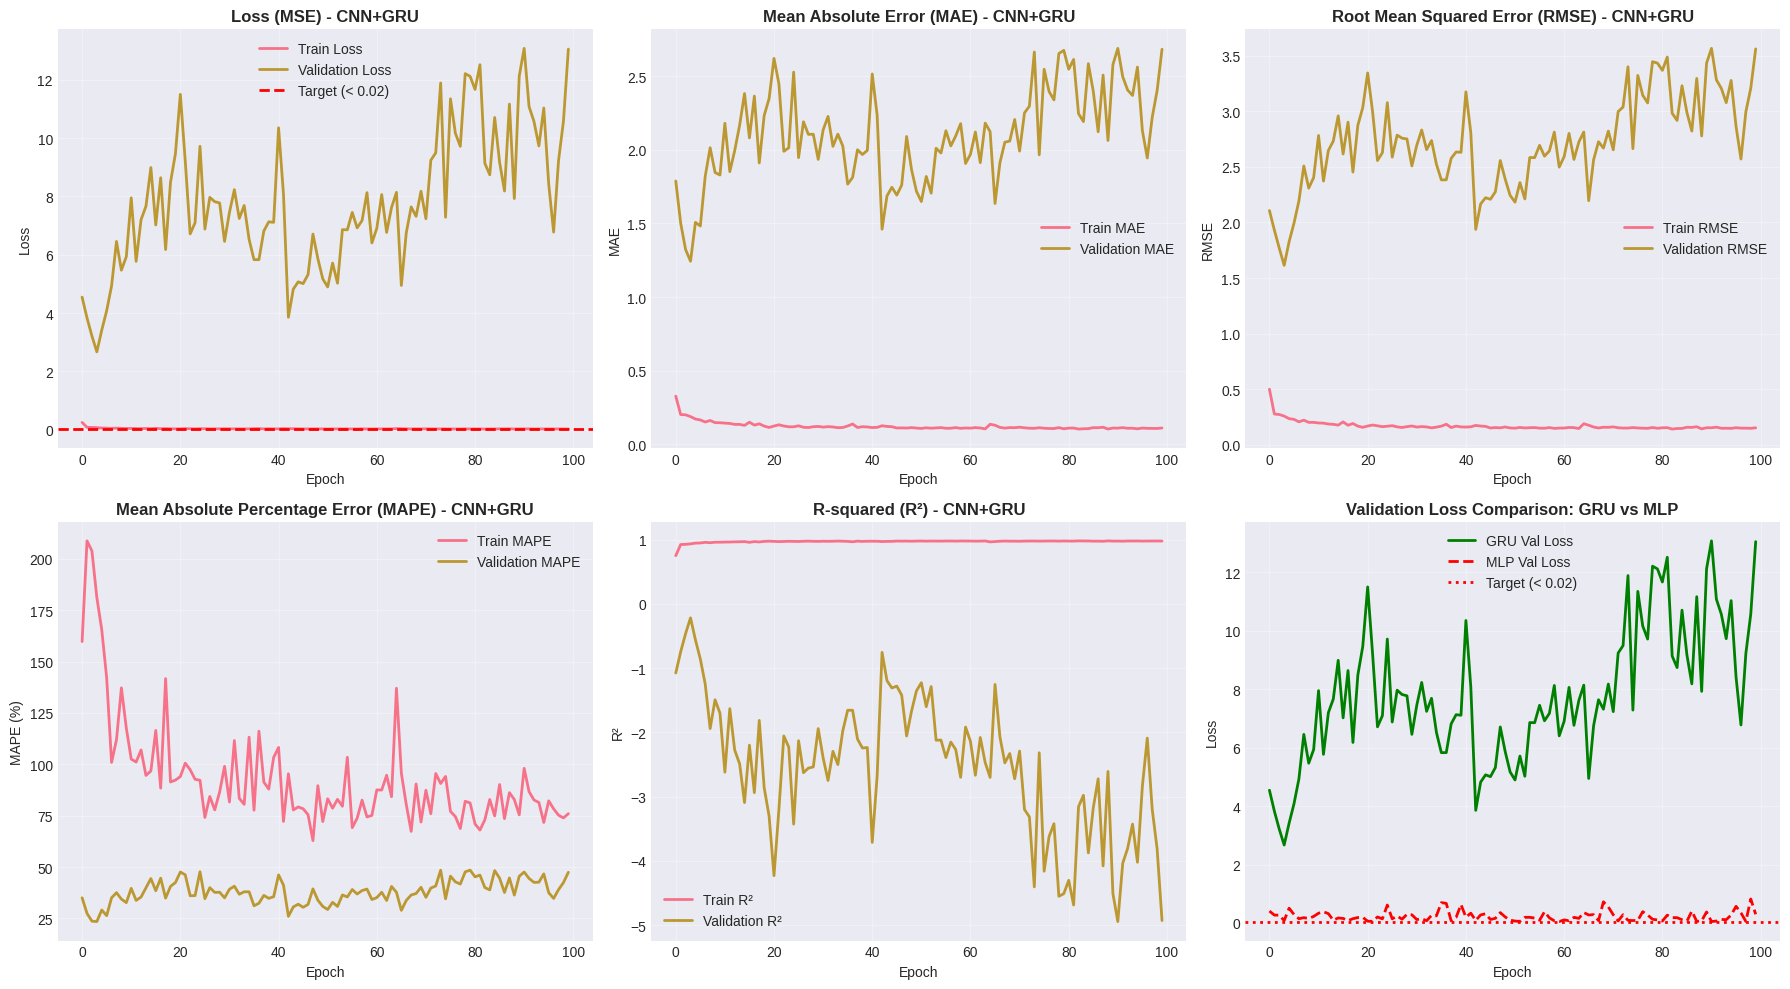


TRAINING ANALYSIS
⚠ Validation Loss >= 0.02: 2.668391
Best validation loss: 2.668391 at epoch 4
Final train loss: 0.024492
Final validation loss: 13.053743


In [48]:
# ============================================================================
# SECTION 2-3-2: GRU Architecture - Plot Training History
# ============================================================================
# Plot training history: Loss and Metrics for GRU
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Loss
axes[0, 0].plot(gru_history['train_loss'], label='Train Loss', linewidth=2)
axes[0, 0].plot(gru_history['val_loss'], label='Validation Loss', linewidth=2)
axes[0, 0].axhline(y=0.02, color='r', linestyle='--', label='Target (< 0.02)', linewidth=2)
axes[0, 0].set_title('Loss (MSE) - CNN+GRU', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# MAE
axes[0, 1].plot(gru_history['train_mae'], label='Train MAE', linewidth=2)
axes[0, 1].plot(gru_history['val_mae'], label='Validation MAE', linewidth=2)
axes[0, 1].set_title('Mean Absolute Error (MAE) - CNN+GRU', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('MAE')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# RMSE
axes[0, 2].plot(gru_history['train_rmse'], label='Train RMSE', linewidth=2)
axes[0, 2].plot(gru_history['val_rmse'], label='Validation RMSE', linewidth=2)
axes[0, 2].set_title('Root Mean Squared Error (RMSE) - CNN+GRU', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Epoch')
axes[0, 2].set_ylabel('RMSE')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# MAPE
axes[1, 0].plot(gru_history['train_mape'], label='Train MAPE', linewidth=2)
axes[1, 0].plot(gru_history['val_mape'], label='Validation MAPE', linewidth=2)
axes[1, 0].set_title('Mean Absolute Percentage Error (MAPE) - CNN+GRU', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('MAPE (%)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# R2
axes[1, 1].plot(gru_history['train_r2'], label='Train R²', linewidth=2)
axes[1, 1].plot(gru_history['val_r2'], label='Validation R²', linewidth=2)
axes[1, 1].set_title('R-squared (R²) - CNN+GRU', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('R²')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Loss comparison with baseline
axes[1, 2].plot(gru_history['val_loss'], label='GRU Val Loss', linewidth=2, color='green')
axes[1, 2].plot(history['val_loss'], label='MLP Val Loss', linewidth=2, color='red', linestyle='--')
axes[1, 2].axhline(y=0.02, color='r', linestyle=':', label='Target (< 0.02)', linewidth=2)
axes[1, 2].set_title('Validation Loss Comparison: GRU vs MLP', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('Loss')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Training analysis
print("\n" + "="*60)
print("TRAINING ANALYSIS")
print("="*60)
if gru_best_val_loss < 0.02:
    print(f"✓ Validation Loss < 0.02: REQUIREMENT MET")
else:
    print(f"⚠ Validation Loss >= 0.02: {gru_best_val_loss:.6f}")
print(f"Best validation loss: {gru_best_val_loss:.6f} at epoch {gru_best_epoch+1}")
print(f"Final train loss: {gru_history['train_loss'][-1]:.6f}")
print(f"Final validation loss: {gru_history['val_loss'][-1]:.6f}")
print("="*60)


In [49]:
# ============================================================================
# SECTION 2-3-2: GRU Architecture - Load Best Model and Evaluate on Test Set
# ============================================================================
# Load best model
gru_model.load_state_dict(torch.load(gru_best_model_path))
print("Best GRU model loaded for evaluation!")

# Evaluate on test set
gru_model.eval()
gru_test_loss = 0.0
gru_test_preds = []
gru_test_targets = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        outputs = gru_model(X_batch)
        loss = gru_criterion(outputs, y_batch)

        gru_test_loss += loss.item()
        gru_test_preds.append(outputs.cpu().numpy())
        gru_test_targets.append(y_batch.cpu().numpy())

gru_test_loss /= len(test_loader)
gru_test_preds = np.concatenate(gru_test_preds, axis=0)
gru_test_targets = np.concatenate(gru_test_targets, axis=0)
gru_test_metrics = calculate_metrics(gru_test_targets, gru_test_preds)

print("\n" + "="*60)
print("CNN+GRU MODEL TEST SET EVALUATION")
print("="*60)
print(f"Test Loss (MSE): {gru_test_loss:.6f}")
print(f"Test MAE: {gru_test_metrics['MAE']:.6f}")
print(f"Test RMSE: {gru_test_metrics['RMSE']:.6f}")
print(f"Test MAPE: {gru_test_metrics['MAPE']:.2f}%")
print(f"Test R²: {gru_test_metrics['R2']:.6f}")
print("="*60)

# Report network parameters and hyperparameters
print("\n" + "="*80)
print("CNN+GRU MODEL SUMMARY")
print("="*80)
print(f"Total Parameters: {gru_total_params:,}")
print(f"Trainable Parameters: {gru_trainable_params:,}")
print(f"\nHyperparameters:")
print(f"  Input window: {input_window_size}")
print(f"  Output window: {output_window_size}")
print(f"  Output features: {output_features}")
print(f"  CNN filters: [64, 128]")
print(f"  CNN kernels: [3, 3]")
print(f"  GRU hidden size: 128")
print(f"  GRU layers: 3")
print(f"  FC hidden: 64")
print(f"  Dropout: 0.2")
print(f"  Learning rate: 0.001")
print(f"  Weight decay: 1e-5")
print(f"  Batch size: 64")
print(f"  Epochs: {gru_num_epochs}")
print(f"\nPerformance:")
print(f"  Best Validation Loss: {gru_best_val_loss:.6f}")
print(f"  Test Loss: {gru_test_loss:.6f}")
print(f"  Test MAE: {gru_test_metrics['MAE']:.6f}")
print(f"  Test RMSE: {gru_test_metrics['RMSE']:.6f}")
print(f"  Test R²: {gru_test_metrics['R2']:.6f}")
print("="*80)


Best GRU model loaded for evaluation!

CNN+GRU MODEL TEST SET EVALUATION
Test Loss (MSE): 34.100267
Test MAE: 5.268644
Test RMSE: 5.567920
Test MAPE: 57.14%
Test R²: -9.632199

CNN+GRU MODEL SUMMARY
Total Parameters: 333,544
Trainable Parameters: 333,544

Hyperparameters:
  Input window: 20
  Output window: 10
  Output features: 4
  CNN filters: [64, 128]
  CNN kernels: [3, 3]
  GRU hidden size: 128
  GRU layers: 3
  FC hidden: 64
  Dropout: 0.2
  Learning rate: 0.001
  Weight decay: 1e-5
  Batch size: 64
  Epochs: 100

Performance:
  Best Validation Loss: 2.668391
  Test Loss: 34.100267
  Test MAE: 5.268644
  Test RMSE: 5.567920
  Test R²: -9.632199


In [50]:
# ============================================================================
# SECTION 2-3-2: GRU Architecture - Add to Model Results for Comparison
# ============================================================================
# Store GRU model results for comparison
model_results['GRU'] = {
    'model_name': 'CNN+GRU',
    'test_mae': gru_test_metrics['MAE'],
    'test_rmse': gru_test_metrics['RMSE'],
    'test_mape': gru_test_metrics['MAPE'],
    'test_r2': gru_test_metrics['R2'],
    'test_loss': gru_test_loss,
    'total_params': gru_total_params,
    'model': gru_model,
    'predictions': gru_test_preds,
    'targets': gru_test_targets
}

print("GRU model results stored for comparison.")


GRU model results stored for comparison.


## Section 2-4: Comparison on Test Data and Performance Comparisons


### Section 2-4-1: Model Performance Comparison on Test Data


In [51]:
# ============================================================================
# SECTION 2-4-1: Performance Comparison - Store Model Results
# ============================================================================
# Store model results for comparison
# This will be populated as we add more models (CNN+LSTM, CNN+GRU)
model_results = {}

# Store MLP model results
model_results['MLP'] = {
    'model_name': 'MLP (NARMAX)',
    'test_mae': test_metrics['MAE'],
    'test_rmse': test_metrics['RMSE'],
    'test_mape': test_metrics['MAPE'],
    'test_r2': test_metrics['R2'],
    'test_loss': test_loss,
    'total_params': total_params,
    'model': model,
    'predictions': test_preds,
    'targets': test_targets
}

print("MLP model results stored for comparison.")
print("Note: Add other models (CNN+LSTM, CNN+GRU) results here when implemented.")


MLP model results stored for comparison.
Note: Add other models (CNN+LSTM, CNN+GRU) results here when implemented.


In [52]:
# ============================================================================
# SECTION 2-4-1: Performance Comparison - Create Comparison Table
# ============================================================================
# Create comparison table
import pandas as pd

# Prepare data for table
comparison_data = []
for model_name, results in model_results.items():
    comparison_data.append({
        'Model': results['model_name'],
        'Total Parameters': f"{results['total_params']:,}",
        'Test MAE': f"{results['test_mae']:.6f}",
        'Test RMSE': f"{results['test_rmse']:.6f}",
        'Test MAPE (%)': f"{results['test_mape']:.4f}",
        'Test R²': f"{results['test_r2']:.6f}",
        'Test Loss (MSE)': f"{results['test_loss']:.6f}"
    })

# Create DataFrame
comparison_df = pd.DataFrame(comparison_data)

# Display table
print("\n" + "="*80)
print("MODEL PERFORMANCE COMPARISON ON TEST DATA")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)

# Also save as formatted table
comparison_df_formatted = comparison_df.copy()
print("\nFormatted Table (for reporting):")
print(comparison_df_formatted.to_string(index=False))

# Save to CSV for easy access
comparison_df.to_csv('model_comparison_results.csv', index=False)
print("\nResults saved to 'model_comparison_results.csv'")



MODEL PERFORMANCE COMPARISON ON TEST DATA
       Model Total Parameters Test MAE Test RMSE Test MAPE (%)  Test R² Test Loss (MSE)
MLP (NARMAX)           13,928 0.241877  0.296478        2.7460 0.969854        0.084503

Formatted Table (for reporting):
       Model Total Parameters Test MAE Test RMSE Test MAPE (%)  Test R² Test Loss (MSE)
MLP (NARMAX)           13,928 0.241877  0.296478        2.7460 0.969854        0.084503

Results saved to 'model_comparison_results.csv'


# ============================================================================
# SECTION 2-4-2: Training Time and Computational Cost Report
# ============================================================================
### Section 2-4-2: Training Time and Computational Cost Report


In [53]:
# Calculate FLOPs (Floating Point Operations) for a model
def calculate_flops_mlp(model, input_shape):
    """
    Calculate approximate FLOPs for MLP model
    FLOPs = number of multiplications + additions
    For a linear layer: input_size * output_size (multiplications) + output_size (additions)
    """
    flops = 0
    input_size = input_shape[0] * input_shape[1]  # flattened input

    # FC1: input_size -> hidden1
    flops += input_size * model.fc1.out_features  # multiplications
    flops += model.fc1.out_features  # additions (bias)

    # FC2: hidden1 -> hidden2
    flops += model.fc2.in_features * model.fc2.out_features  # multiplications
    flops += model.fc2.out_features  # additions (bias)

    # FC3: hidden2 -> output
    flops += model.fc3.in_features * model.fc3.out_features  # multiplications
    flops += model.fc3.out_features  # additions (bias)

    return flops

# Calculate FLOPs for MLP
mlp_flops = calculate_flops_mlp(model, (batch_size, input_window_size, 1))
mlp_flops_per_sample = mlp_flops / batch_size

# Store training time (you should record this during training)
# For now, we'll use a placeholder - replace with actual training time
mlp_training_time = None  # Replace with actual time from training

# Get hardware information
import platform
import torch

hardware_info = {
    'system': platform.system(),
    'processor': platform.processor(),
}

if torch.cuda.is_available():
    hardware_info['gpu'] = torch.cuda.get_device_name(0)
    hardware_info['gpu_memory'] = f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB"
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    hardware_info['gpu'] = 'Apple Silicon (MPS)'
    hardware_info['gpu_memory'] = 'N/A'
else:
    hardware_info['gpu'] = 'CPU only'

print("\n" + "="*80)
print("HARDWARE INFORMATION")
print("="*80)
for key, value in hardware_info.items():
    print(f"{key.capitalize()}: {value}")
print("="*80)



HARDWARE INFORMATION
System: Linux
Processor: x86_64
Gpu: Tesla T4
Gpu_memory: 15.83 GB


In [54]:
# Store computational cost information
computational_costs = {}

# MLP computational cost
computational_costs['MLP'] = {
    'model_name': 'MLP (NARMAX)',
    'total_params': total_params,
    'flops_per_sample': mlp_flops_per_sample,
    'flops_total': mlp_flops,
    'training_time_50_epochs': None,  # Replace with actual time
    'training_time_per_epoch': None   # Replace with actual time
}

# Create computational cost comparison table
cost_data = []
for model_name, costs in computational_costs.items():
    cost_data.append({
        'Model': costs['model_name'],
        'Total Parameters': f"{costs['total_params']:,}",
        'FLOPs per Sample': f"{costs['flops_per_sample']:,.0f}",
        'FLOPs per Batch (64)': f"{costs['flops_per_sample'] * 64:,.0f}",
        'Training Time (50 epochs)': f"{costs['training_time_50_epochs']:.2f} min" if costs['training_time_50_epochs'] else "Not recorded",
        'Training Time per Epoch': f"{costs['training_time_per_epoch']:.2f} sec" if costs['training_time_per_epoch'] else "Not recorded"
    })

cost_df = pd.DataFrame(cost_data)

print("\n" + "="*80)
print("COMPUTATIONAL COST REPORT")
print("="*80)
print(cost_df.to_string(index=False))
print("="*80)

# Note: FLOPs calculation
print("\nNote on FLOPs Calculation:")
print("- FLOPs (Floating Point Operations) = Multiplications + Additions")
print("- For linear layers: FLOPs = (input_size × output_size) + output_size (for bias)")
print("- Batch normalization and activation functions add minimal FLOPs compared to linear layers")
print("- Actual training FLOPs = FLOPs_per_sample × batch_size × num_samples × num_epochs")



COMPUTATIONAL COST REPORT
       Model Total Parameters FLOPs per Sample FLOPs per Batch (64) Training Time (50 epochs) Training Time per Epoch
MLP (NARMAX)           13,928            2,732              174,824              Not recorded            Not recorded

Note on FLOPs Calculation:
- FLOPs (Floating Point Operations) = Multiplications + Additions
- For linear layers: FLOPs = (input_size × output_size) + output_size (for bias)
- Batch normalization and activation functions add minimal FLOPs compared to linear layers
- Actual training FLOPs = FLOPs_per_sample × batch_size × num_samples × num_epochs


### Section 2-4-3: Price Prediction Visualization and Analysis


In [55]:
# ============================================================================
# SECTION 2-4-3: Price Prediction Visualization - Prepare Data for All Models
# ============================================================================
# Task 1: Plot predictions for 2024-2025 for all models
# We'll plot Close price (can be changed to Open)

# Prepare data for all models
plot_data = {}

for model_name, results in model_results.items():
    # Get test predictions and targets
    preds = results['predictions']
    targets = results['targets']

    # Extract 2024-2025 period
    pred_2024_2025 = preds[test_2024_2025_indices]
    target_2024_2025 = targets[test_2024_2025_indices]

    # Denormalize
    pred_2024_2025_denorm = scaler_y.inverse_transform(
        pred_2024_2025.reshape(-1, output_features)
    ).reshape(pred_2024_2025.shape)

    target_2024_2025_denorm = scaler_y.inverse_transform(
        target_2024_2025.reshape(-1, output_features)
    ).reshape(target_2024_2025.shape)

    # Extract Close price (index 1 in output_features: ['High', 'Close', 'Open', 'Low'])
    close_idx = 1
    pred_close = pred_2024_2025_denorm[:, :, close_idx].flatten()
    target_close = target_2024_2025_denorm[:, :, close_idx].flatten()

    plot_data[model_name] = {
        'predicted': pred_close,
        'actual': target_close,
        'model_name': results['model_name']
    }

# Create date range for plotting
if len(dates_2024_2025) > 0:
    plot_dates = []
    for date in dates_2024_2025[:len(pred_2024_2025)]:
        for step in range(output_window_size):
            plot_dates.append(date + pd.Timedelta(days=step))
    plot_dates = plot_dates[:len(pred_close)]
else:
    plot_dates = range(len(pred_close))

print(f"Prepared plotting data for {len(plot_data)} model(s)")
print(f"Date range: {plot_dates[0] if len(plot_dates) > 0 else 'N/A'} to {plot_dates[-1] if len(plot_dates) > 0 else 'N/A'}")


Prepared plotting data for 1 model(s)
Date range: 2024-01-02 00:00:00 to 2025-12-21 00:00:00


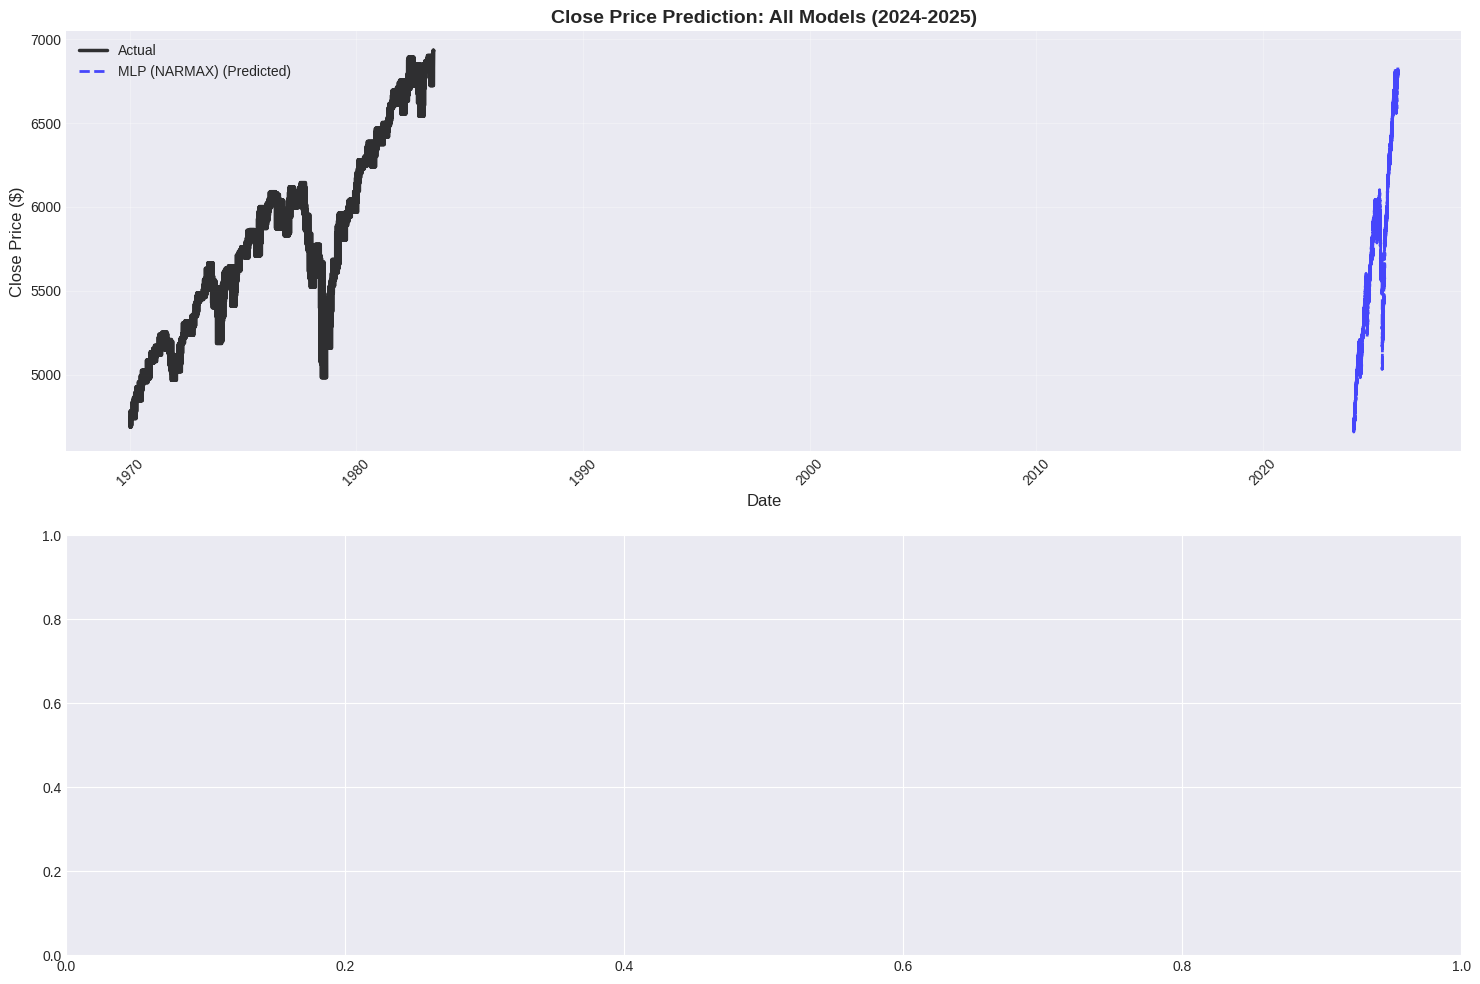

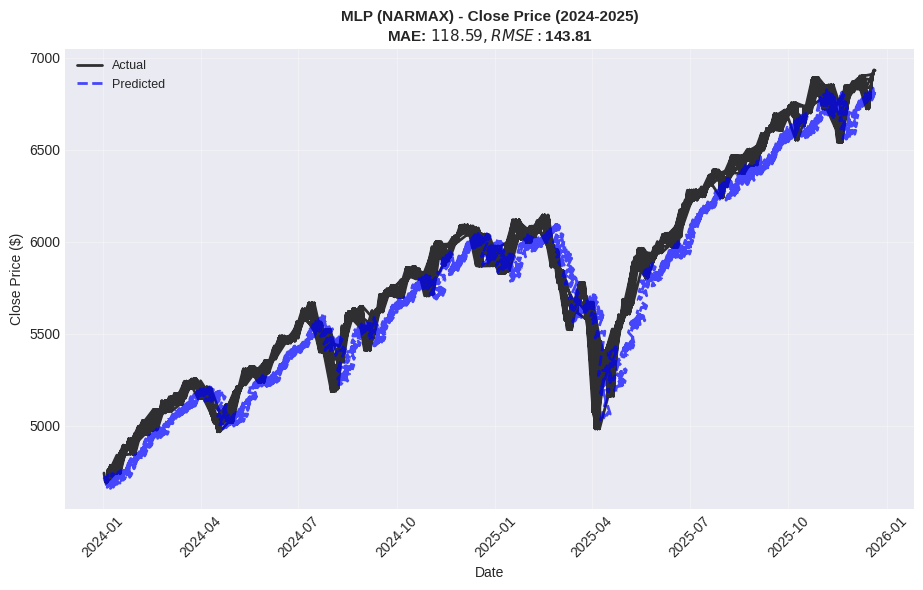


MODEL PERFORMANCE ANALYSIS FOR 2024-2025 PERIOD

Performance Ranking (sorted by RMSE - lower is better):
       Model        MAE       RMSE  MAPE (%)       R²
MLP (NARMAX) 118.588188 143.812378  2.055758 0.933122

✓ Best performing model for 2024-2025: MLP (NARMAX)
  RMSE: $143.81
  MAE: $118.59
  R²: 0.933122


In [56]:
# ============================================================================
# SECTION 2-4-3: Price Prediction Visualization - Plot All Models for 2024-2025
# ============================================================================
# Plot all models' predictions for 2024-2025
fig, axes = plt.subplots(2, 1, figsize=(18, 12))

# Plot 1: All models together
ax1 = axes[0]
ax1.plot(plot_data['MLP']['actual'],
         label='Actual', linewidth=2.5, color='black', alpha=0.8)

colors = ['blue', 'red', 'green', 'orange', 'purple']
for idx, (model_name, data) in enumerate(plot_data.items()):
    ax1.plot(plot_dates, data['predicted'],
             label=f"{data['model_name']} (Predicted)",
             linewidth=2, alpha=0.7, linestyle='--', color=colors[idx % len(colors)])

ax1.set_title('Close Price Prediction: All Models (2024-2025)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Date', fontsize=12)
ax1.set_ylabel('Close Price ($)', fontsize=12)
ax1.legend(loc='best', fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.tick_params(axis='x', rotation=45)

# Plot 2: Individual model comparisons
num_models = len(plot_data)
cols = 2
rows = (num_models + 1) // 2

# Create subplots for each model
fig2, axes2_raw = plt.subplots(rows, cols, figsize=(18, 6*rows))

# Ensure axes2 is a flat array of Axes objects for consistent indexing
if isinstance(axes2_raw, np.ndarray):
    axes2 = axes2_raw.flatten()
else: # single Axes object returned by plt.subplots (e.g., if rows=1, cols=1)
    axes2 = np.array([axes2_raw])

for idx, (model_name, data) in enumerate(plot_data.items()):
    ax = axes2[idx] # Always access by index
    ax.plot(plot_dates, data['actual'], label='Actual',
            linewidth=2, color='black', alpha=0.8)
    ax.plot(plot_dates, data['predicted'], label='Predicted',
            linewidth=2, alpha=0.7, linestyle='--', color=colors[idx % len(colors)])

    # Calculate metrics for this model
    mae = np.mean(np.abs(data['actual'] - data['predicted']))
    rmse = np.sqrt(np.mean((data['actual'] - data['predicted']) ** 2))

    ax.set_title(f"{data['model_name']} - Close Price (2024-2025)\nMAE: ${mae:.2f}, RMSE: ${rmse:.2f}",
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Date', fontsize=10)
    ax.set_ylabel('Close Price ($)', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

# Hide unused subplots
for idx in range(num_models, len(axes2)):
    axes2[idx].set_visible(False)

plt.tight_layout()
plt.show()

# Analysis: Which model performs best?
print("\n" + "="*80)
print("MODEL PERFORMANCE ANALYSIS FOR 2024-2025 PERIOD")
print("="*80)

model_performance_2024_2025 = []
for model_name, data in plot_data.items():
    actual = data['actual']
    predicted = data['predicted']

    mae = np.mean(np.abs(actual - predicted))
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    r2 = 1 - (np.sum((actual - predicted) ** 2) / np.sum((actual - np.mean(actual)) ** 2))

    model_performance_2024_2025.append({
        'Model': data['model_name'],
        'MAE': mae,
        'RMSE': rmse,
        'MAPE (%)': mape,
        'R²': r2
    })

perf_df = pd.DataFrame(model_performance_2024_2025)
perf_df = perf_df.sort_values('RMSE')  # Sort by RMSE (lower is better)

print("\nPerformance Ranking (sorted by RMSE - lower is better):")
print(perf_df.to_string(index=False))

best_model = perf_df.iloc[0]['Model']
print(f"\n✓ Best performing model for 2024-2025: {best_model}")
print(f"  RMSE: ${perf_df.iloc[0]['RMSE']:.2f}")
print(f"  MAE: ${perf_df.iloc[0]['MAE']:.2f}")
print(f"  R²: {perf_df.iloc[0]['R²']:.6f}")
print("="*80)


In [57]:
# ============================================================================
# SECTION 2-4-3: Price Prediction Visualization - Recursive Prediction for 2026-2027
# ============================================================================
# Task 2: Recursive Prediction for 2026-2027
# Using model's own predictions as input for subsequent periods

def recursive_predict(model, initial_input, num_steps, device, scaler_X, scaler_y):
    """
    Perform recursive prediction where model's predictions are used as input for next steps

    Args:
        model: Trained model
        initial_input: Initial input window [1, input_window, input_features] (already normalized)
        num_steps: Number of future steps to predict
        device: Device to run on
        scaler_X: Scaler for input features
        scaler_y: Scaler for output features

    Returns:
        predictions: [num_steps, output_features] - denormalized predictions
    """
    model.eval()
    predictions = []

    # Start with initial input (already normalized)
    current_input = initial_input.copy()  # [1, input_window, 1]

    with torch.no_grad():
        for step in range(num_steps):
            # Convert to tensor (already normalized)
            input_tensor = torch.FloatTensor(current_input).to(device)

            # Predict (output is in normalized space)
            output = model(input_tensor)
            output_np = output.cpu().numpy()[0]  # [output_window, output_features]

            # Store first time step prediction (normalized)
            predictions.append(output_np[0])  # [output_features]

            # Update input: shift window and add prediction
            # We use Close price (index 1) as input for next step
            # Input uses Close price, so we extract Close from output
            close_price_pred_normalized = output_np[0, 1]  # Close price prediction (normalized)

            # Shift current_input and add new prediction
            # current_input shape: [1, input_window, 1]
            current_input = np.roll(current_input, -1, axis=1)
            current_input[0, -1, 0] = close_price_pred_normalized  # Update with predicted close price

    # Denormalize all predictions
    predictions_array = np.array(predictions)  # [num_steps, output_features]
    predictions_denorm = scaler_y.inverse_transform(predictions_array)

    return predictions_denorm

# Get the last input from test set to start recursive prediction
# This should be from end of 2025
last_test_input = X_test_scaled[-1:].copy()  # [1, input_window, 1]

# Calculate number of days from end of 2025 to end of 2027
# Assuming we want to predict daily for ~2 years
days_2026_2027 = 365 * 2  # Approximately 730 days

print(f"Starting recursive prediction for 2026-2027...")
print(f"Initial input shape: {last_test_input.shape}")
print(f"Number of prediction steps: {days_2026_2027}")

# Perform recursive prediction for all models
recursive_predictions = {}

for model_name, results in model_results.items():
    print(f"\nPredicting with {results['model_name']}...")
    model = results['model']

    try:
        pred_2026_2027 = recursive_predict(
            model, last_test_input, days_2026_2027, device, scaler_X, scaler_y
        )
        recursive_predictions[model_name] = {
            'predictions': pred_2026_2027,
            'model_name': results['model_name']
        }
        print(f"  Completed: {len(pred_2026_2027)} steps predicted")
    except Exception as e:
        print(f"  Error: {str(e)}")
        recursive_predictions[model_name] = None


Starting recursive prediction for 2026-2027...
Initial input shape: (1, 20, 1)
Number of prediction steps: 730

Predicting with MLP (NARMAX)...
  Completed: 730 steps predicted


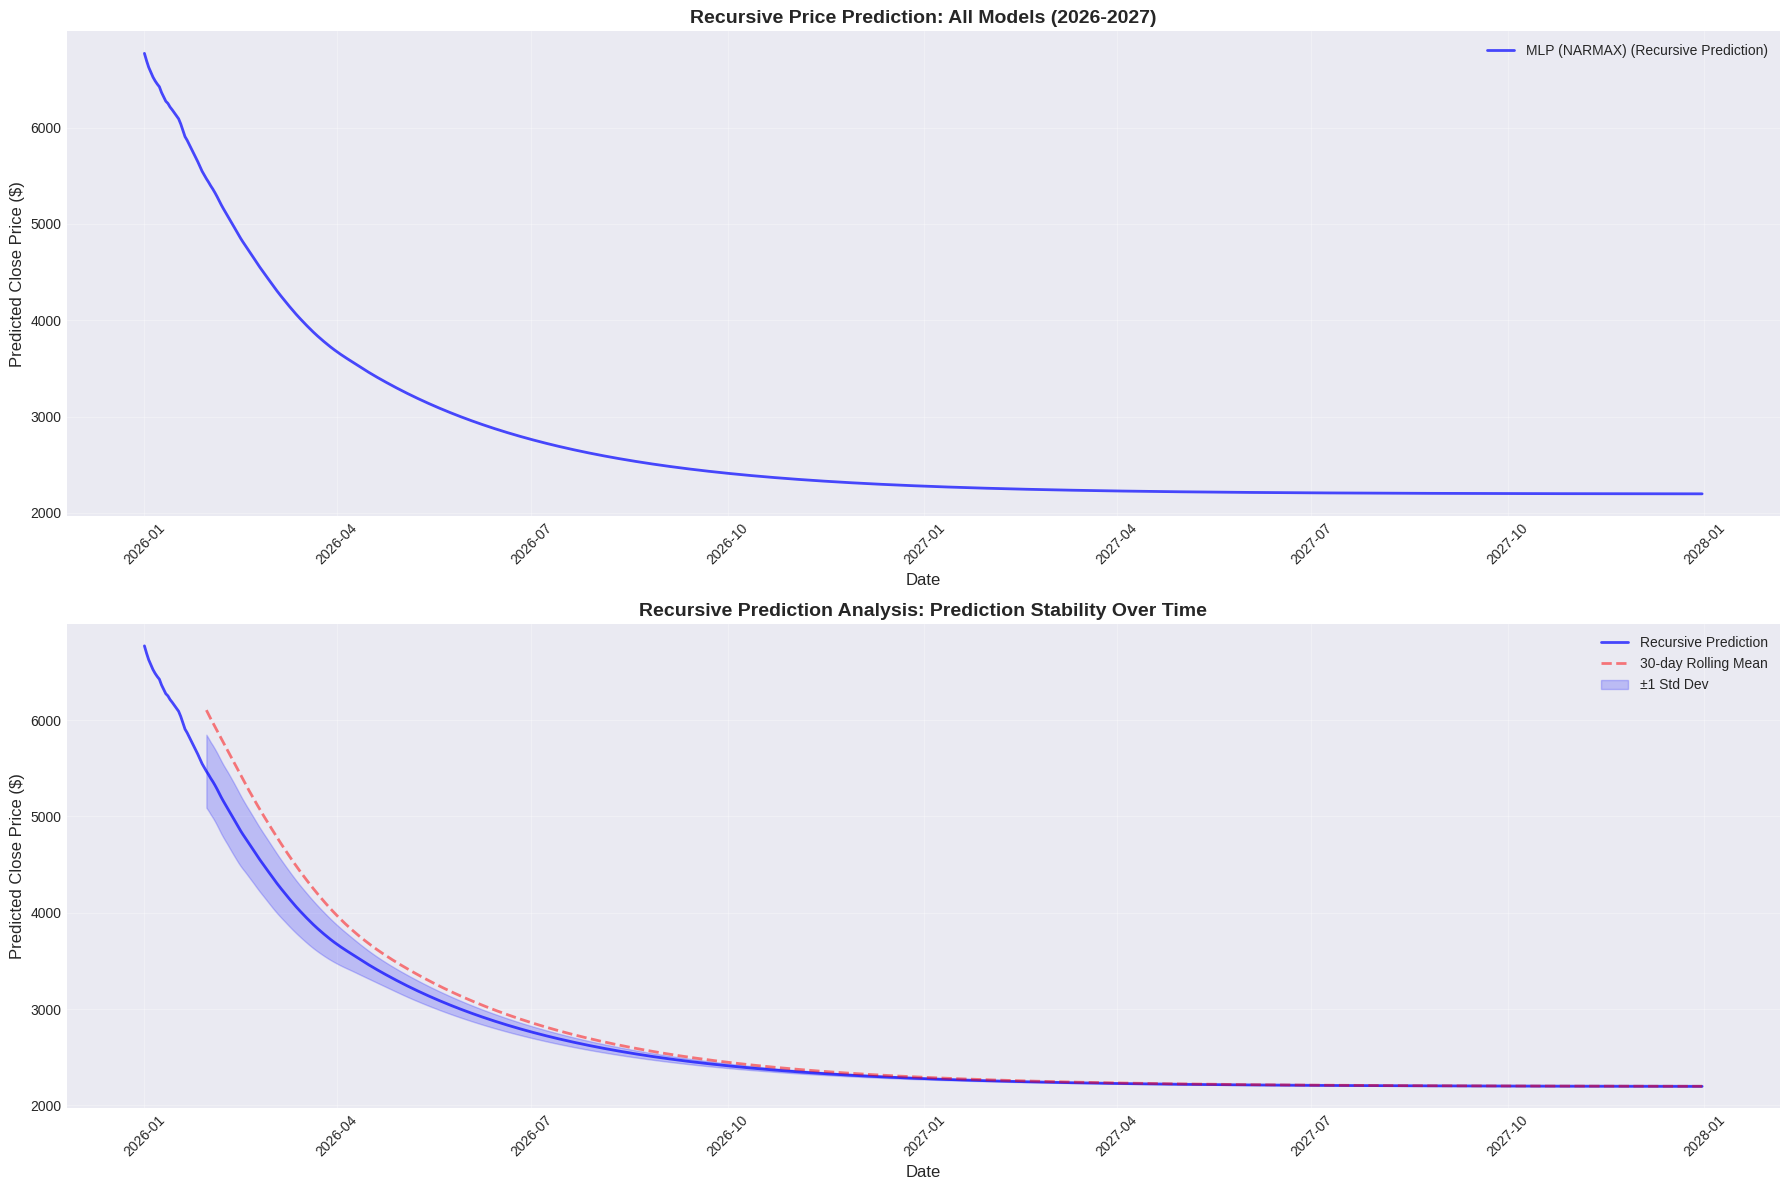

In [58]:
# ============================================================================
# SECTION 2-4-3: Price Prediction Visualization - Plot Recursive Predictions for 2026-2027
# ============================================================================
# Create date range for 2026-2027 predictions
# Start from January 1, 2026
start_date_2026 = pd.Timestamp('2026-01-01')
pred_dates_2026_2027 = [start_date_2026 + pd.Timedelta(days=i)
                         for i in range(days_2026_2027)]

# Plot recursive predictions for 2026-2027
fig, axes = plt.subplots(2, 1, figsize=(18, 12))

# Plot 1: All models' recursive predictions
ax1 = axes[0]

colors = ['blue', 'red', 'green', 'orange', 'purple']
for idx, (model_name, pred_data) in enumerate(recursive_predictions.items()):
    if pred_data is not None:
        close_prices = pred_data['predictions'][:, 1]  # Close price (index 1)
        ax1.plot(pred_dates_2026_2027[:len(close_prices)], close_prices,
                 label=f"{pred_data['model_name']} (Recursive Prediction)",
                 linewidth=2, alpha=0.7, color=colors[idx % len(colors)])

ax1.set_title('Recursive Price Prediction: All Models (2026-2027)',
              fontsize=14, fontweight='bold')
ax1.set_xlabel('Date', fontsize=12)
ax1.set_ylabel('Predicted Close Price ($)', fontsize=12)
ax1.legend(loc='best', fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.tick_params(axis='x', rotation=45)

# Plot 2: Individual model predictions with analysis
ax2 = axes[1]

# Plot first model's prediction with variance analysis
if len(recursive_predictions) > 0:
    first_model = list(recursive_predictions.keys())[0]
    if recursive_predictions[first_model] is not None:
        close_prices = recursive_predictions[first_model]['predictions'][:, 1]

        # Calculate rolling statistics to show prediction stability
        window_size = 30  # 30-day window
        rolling_mean = pd.Series(close_prices).rolling(window=window_size).mean()
        rolling_std = pd.Series(close_prices).rolling(window=window_size).std()

        ax2.plot(pred_dates_2026_2027[:len(close_prices)], close_prices,
                label='Recursive Prediction', linewidth=2, alpha=0.7, color='blue')
        ax2.plot(pred_dates_2026_2027[:len(rolling_mean)], rolling_mean,
                label=f'{window_size}-day Rolling Mean', linewidth=2, alpha=0.5,
                linestyle='--', color='red')
        ax2.fill_between(pred_dates_2026_2027[:len(close_prices)],
                        close_prices - rolling_std.values[:len(close_prices)],
                        close_prices + rolling_std.values[:len(close_prices)],
                        alpha=0.2, color='blue', label='±1 Std Dev')

ax2.set_title('Recursive Prediction Analysis: Prediction Stability Over Time',
              fontsize=14, fontweight='bold')
ax2.set_xlabel('Date', fontsize=12)
ax2.set_ylabel('Predicted Close Price ($)', fontsize=12)
ax2.legend(loc='best', fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


## Section 2-5: Bonus Section - CNN-Only Network

Convolutional networks act like filters. In many applications, these filters can be designed in such a way that, using past information, they can extract or predict features related to the future signal. This section evaluates the possibility of this topic.


### Section 2-5-1: CNN-Only Network Design and Explanation


In [59]:
# ============================================================================
# SECTION 2-5-1: CNN-Only Network - Model Definition
# ============================================================================
# CNN-Only Network Design
# This network uses ONLY convolutional layers (no FC, LSTM, GRU layers)

class CNNOnlyModel(nn.Module):
    """
    CNN-Only network for time series prediction
    Uses only 1D convolutional layers to transform input to output dimensions

    Input: [batch, input_window, input_features]
    Output: [batch, output_window, output_features]

    Dimension transformation formula for 1D convolution:
    output_length = floor((input_length + 2*padding - kernel_size) / stride) + 1
    """
    def __init__(self, input_window, output_window, output_features,
                 num_filters=[64, 128, 64], kernel_sizes=[3, 3, 3],
                 strides=[1, 1, 1], paddings=[1, 1, 1], dropout=0.2):
        super(CNNOnlyModel, self).__init__()

        self.input_window = input_window
        self.output_window = output_window
        self.output_features = output_features

        # Build convolutional layers
        layers = []
        in_channels = 1  # Input features (Close price)

        for i, (out_channels, kernel_size, stride, padding) in enumerate(
            zip(num_filters, kernel_sizes, strides, paddings)
        ):
            layers.append(nn.Conv1d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=kernel_size,
                stride=stride,
                padding=padding
            ))
            layers.append(nn.BatchNorm1d(out_channels))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))

            in_channels = out_channels

        # Final convolutional layer to get output dimensions
        # We need to map to output_window * output_features
        # Strategy: Use conv layers to reduce/increase sequence length
        # Then use a final conv to get the right number of features

        # Calculate current length after conv layers
        current_length = input_window
        for kernel_size, stride, padding in zip(kernel_sizes, strides, paddings):
            current_length = (current_length + 2*padding - kernel_size) // stride + 1

        # If we need to adjust the length, add more conv layers
        if current_length > output_window:
            # Reduce length using stride > 1
            reduction_factor = current_length // output_window
            if reduction_factor > 1:
                layers.append(nn.Conv1d(
                    in_channels=in_channels,
                    out_channels=in_channels,
                    kernel_size=reduction_factor,
                    stride=reduction_factor,
                    padding=0
                ))
                layers.append(nn.BatchNorm1d(in_channels))
                layers.append(nn.ReLU())

        elif current_length < output_window:
            # Increase length using transposed convolution or interpolation
            # Use transposed conv to upsample
            upsampling_factor = output_window // current_length
            layers.append(nn.ConvTranspose1d(
                in_channels=in_channels,
                out_channels=in_channels,
                kernel_size=upsampling_factor,
                stride=upsampling_factor,
                padding=0
            ))
            layers.append(nn.BatchNorm1d(in_channels))
            layers.append(nn.ReLU())

        # Final layer to get output_features channels
        layers.append(nn.Conv1d(
            in_channels=in_channels,
            out_channels=output_features,
            kernel_size=1,
            stride=1,
            padding=0
        ))

        self.conv_layers = nn.Sequential(*layers)

    def forward(self, x):
        # x: [batch, input_window, input_features]
        # Transpose for Conv1d: [batch, channels, length]
        x = x.transpose(1, 2)  # [batch, input_features, input_window]

        # Apply convolutional layers
        x = self.conv_layers(x)  # [batch, output_features, output_window]

        # Transpose back: [batch, output_window, output_features]
        x = x.transpose(1, 2)

        return x

# Design CNN-Only model
# Hyperparameters
cnn_num_filters = [64, 128, 64]
cnn_kernel_sizes = [3, 3, 3]
cnn_strides = [1, 1, 1]
cnn_paddings = [1, 1, 1]
cnn_dropout = 0.2

cnn_model = CNNOnlyModel(
    input_window=input_window_size,
    output_window=output_window_size,
    output_features=output_features,
    num_filters=cnn_num_filters,
    kernel_sizes=cnn_kernel_sizes,
    strides=cnn_strides,
    paddings=cnn_paddings,
    dropout=cnn_dropout
).to(device)

# Count parameters
cnn_total_params = sum(p.numel() for p in cnn_model.parameters())
cnn_trainable_params = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)

print("CNN-Only Model initialized!")
print(f"Input window: {input_window_size}")
print(f"Output window: {output_window_size}")
print(f"Output features: {output_features}")
print(f"Total parameters: {cnn_total_params:,}")
print(f"Trainable parameters: {cnn_trainable_params:,}")

# Compare with MLP baseline
print(f"\nComparison with MLP Baseline:")
print(f"  MLP parameters: {total_params:,}")
print(f"  CNN-Only parameters: {cnn_total_params:,}")
print(f"  Difference: {cnn_total_params - total_params:,} ({((cnn_total_params - total_params) / total_params * 100):.2f}%)")
if cnn_total_params < total_params:
    print(f"  ✓ CNN-Only is LIGHTER than MLP baseline")
else:
    print(f"  ✗ CNN-Only is HEAVIER than MLP baseline")

print("\nModel structure:")
print(cnn_model)


CNN-Only Model initialized!
Input window: 20
Output window: 10
Output features: 4
Total parameters: 58,756
Trainable parameters: 58,756

Comparison with MLP Baseline:
  MLP parameters: 13,928
  CNN-Only parameters: 58,756
  Difference: 44,828 (321.86%)
  ✗ CNN-Only is HEAVIER than MLP baseline

Model structure:
CNNOnlyModel(
  (conv_layers): Sequential(
    (0): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Conv1d(128, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
 

In [60]:
# Explain dimension transformation
print("\n" + "="*80)
print("DIMENSION TRANSFORMATION EXPLANATION")
print("="*80)

print("\nInput Dimensions:")
print(f"  Shape: [batch, {input_window_size}, 1]")
print(f"  - Batch size: variable")
print(f"  - Input window length: {input_window_size}")
print(f"  - Input features: 1 (Close price)")

print("\nOutput Dimensions:")
print(f"  Shape: [batch, {output_window_size}, {output_features}]")
print(f"  - Batch size: variable")
print(f"  - Output window length: {output_window_size}")
print(f"  - Output features: {output_features} (High, Close, Open, Low)")

print("\nDimension Transformation Formula for 1D Convolution:")
print("  output_length = floor((input_length + 2*padding - kernel_size) / stride) + 1")

print("\nLayer-by-Layer Transformation:")
current_length = input_window_size
print(f"  Initial length: {current_length}")

for i, (kernel_size, stride, padding) in enumerate(zip(cnn_kernel_sizes, cnn_strides, cnn_paddings)):
    new_length = (current_length + 2*padding - kernel_size) // stride + 1
    print(f"  Conv Layer {i+1}: kernel={kernel_size}, stride={stride}, padding={padding}")
    print(f"    {current_length} -> {new_length}")
    current_length = new_length

print(f"\nFinal adjustment to reach output_window={output_window_size}:")
if current_length > output_window_size:
    reduction = current_length // output_window_size
    print(f"  Using stride={reduction} to reduce: {current_length} -> {output_window_size}")
elif current_length < output_window_size:
    upsampling = output_window_size // current_length
    print(f"  Using transposed conv (upsampling={upsampling}) to increase: {current_length} -> {output_window_size}")
else:
    print(f"  Length already matches: {current_length}")

print(f"\nFinal Conv1x1 layer:")
print(f"  Channels: {cnn_num_filters[-1]} -> {output_features}")

print("\nKey Points:")
print("  - Stride controls downsampling (stride > 1 reduces length)")
print("  - Padding preserves length (padding = kernel_size//2 for same-length output)")
print("  - Kernel size affects receptive field and feature extraction")
print("  - Transposed convolution can upsample when needed")
print("="*80)



DIMENSION TRANSFORMATION EXPLANATION

Input Dimensions:
  Shape: [batch, 20, 1]
  - Batch size: variable
  - Input window length: 20
  - Input features: 1 (Close price)

Output Dimensions:
  Shape: [batch, 10, 4]
  - Batch size: variable
  - Output window length: 10
  - Output features: 4 (High, Close, Open, Low)

Dimension Transformation Formula for 1D Convolution:
  output_length = floor((input_length + 2*padding - kernel_size) / stride) + 1

Layer-by-Layer Transformation:
  Initial length: 20
  Conv Layer 1: kernel=3, stride=1, padding=1
    20 -> 20
  Conv Layer 2: kernel=3, stride=1, padding=1
    20 -> 20
  Conv Layer 3: kernel=3, stride=1, padding=1
    20 -> 20

Final adjustment to reach output_window=10:
  Using stride=2 to reduce: 20 -> 10

Final Conv1x1 layer:
  Channels: 64 -> 4

Key Points:
  - Stride controls downsampling (stride > 1 reduces length)
  - Padding preserves length (padding = kernel_size//2 for same-length output)
  - Kernel size affects receptive field and 

### Section 2-5-2: Training, Evaluation, and Analysis


In [61]:
# ============================================================================
# SECTION 2-5-2: CNN-Only Network - Training Setup
# ============================================================================
# Training Setup for CNN-Only Model
cnn_criterion = nn.MSELoss()
cnn_optimizer = optim.Adam(cnn_model.parameters(), lr=0.001, weight_decay=1e-5)

# Training parameters (similar to MLP)
cnn_num_epochs = 100
cnn_best_val_loss = float('inf')
cnn_best_model_path = 'best_cnn_only_model.pth'

# History tracking
cnn_history = {
    'train_loss': [],
    'val_loss': [],
    'train_mae': [],
    'val_mae': [],
    'train_rmse': [],
    'val_rmse': [],
    'train_mape': [],
    'val_mape': [],
    'train_r2': [],
    'val_r2': []
}

print("CNN-Only training setup completed!")
print(f"  Loss function: MSE")
print(f"  Optimizer: Adam (lr=0.001, weight_decay=1e-5)")
print(f"  Epochs: {cnn_num_epochs}")
print(f"  Best model will be saved to: {cnn_best_model_path}")


CNN-Only training setup completed!
  Loss function: MSE
  Optimizer: Adam (lr=0.001, weight_decay=1e-5)
  Epochs: 100
  Best model will be saved to: best_cnn_only_model.pth


In [62]:
# ============================================================================
# SECTION 2-5-2: CNN-Only Network - Training Loop
# ============================================================================
# Training Loop for CNN-Only Model
import time

print("Starting CNN-Only model training...")
print("="*60)

start_time = time.time()

for epoch in range(cnn_num_epochs):
    # Training phase
    cnn_model.train()
    train_loss = 0.0
    train_preds = []
    train_targets = []

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        # Forward pass
        cnn_optimizer.zero_grad()
        outputs = cnn_model(X_batch)
        loss = cnn_criterion(outputs, y_batch)

        # Backward pass
        loss.backward()
        cnn_optimizer.step()

        train_loss += loss.item()
        train_preds.append(outputs.detach().cpu().numpy())
        train_targets.append(y_batch.detach().cpu().numpy())

    # Calculate training metrics
    train_loss /= len(train_loader)
    train_preds = np.concatenate(train_preds, axis=0)
    train_targets = np.concatenate(train_targets, axis=0)
    train_metrics = calculate_metrics(train_targets, train_preds)

    # Validation phase
    cnn_model.eval()
    val_loss = 0.0
    val_preds = []
    val_targets = []

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            outputs = cnn_model(X_batch)
            loss = cnn_criterion(outputs, y_batch)

            val_loss += loss.item()
            val_preds.append(outputs.cpu().numpy())
            val_targets.append(y_batch.cpu().numpy())

    # Calculate validation metrics
    val_loss /= len(val_loader)
    val_preds = np.concatenate(val_preds, axis=0)
    val_targets = np.concatenate(val_targets, axis=0)
    val_metrics = calculate_metrics(val_targets, val_preds)

    # Save best model
    if val_loss < cnn_best_val_loss:
        cnn_best_val_loss = val_loss
        torch.save(cnn_model.state_dict(), cnn_best_model_path)
        cnn_best_epoch = epoch

    # Store history
    cnn_history['train_loss'].append(train_loss)
    cnn_history['val_loss'].append(val_loss)
    cnn_history['train_mae'].append(train_metrics['MAE'])
    cnn_history['val_mae'].append(val_metrics['MAE'])
    cnn_history['train_rmse'].append(train_metrics['RMSE'])
    cnn_history['val_rmse'].append(val_metrics['RMSE'])
    cnn_history['train_mape'].append(train_metrics['MAPE'])
    cnn_history['val_mape'].append(val_metrics['MAPE'])
    cnn_history['train_r2'].append(train_metrics['R2'])
    cnn_history['val_r2'].append(val_metrics['R2'])

    # Print progress
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{cnn_num_epochs}]")
        print(f"  Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")
        print(f"  Train MAE: {train_metrics['MAE']:.6f} | Val MAE: {val_metrics['MAE']:.6f}")
        print(f"  Train RMSE: {train_metrics['RMSE']:.6f} | Val RMSE: {val_metrics['RMSE']:.6f}")
        print(f"  Train R2: {train_metrics['R2']:.6f} | Val R2: {val_metrics['R2']:.6f}")
        print("-"*60)

training_time = time.time() - start_time

print(f"\nTraining completed!")
print(f"Total training time: {training_time:.2f} seconds ({training_time/60:.2f} minutes)")
print(f"Best validation loss: {cnn_best_val_loss:.6f} at epoch {cnn_best_epoch+1}")
print(f"Best model saved to: {cnn_best_model_path}")


Starting CNN-Only model training...
Epoch [1/100]
  Train Loss: 0.126295 | Val Loss: 0.123904
  Train MAE: 0.239632 | Val MAE: 0.247771
  Train RMSE: 0.354655 | Val RMSE: 0.356220
  Train R2: 0.874220 | Val R2: 0.940638
------------------------------------------------------------
Epoch [10/100]
  Train Loss: 0.037284 | Val Loss: 0.122534
  Train MAE: 0.143550 | Val MAE: 0.251474
  Train RMSE: 0.190489 | Val RMSE: 0.353802
  Train R2: 0.963714 | Val R2: 0.941441
------------------------------------------------------------
Epoch [20/100]
  Train Loss: 0.028193 | Val Loss: 0.291200
  Train MAE: 0.126042 | Val MAE: 0.431512
  Train RMSE: 0.168156 | Val RMSE: 0.536312
  Train R2: 0.971724 | Val R2: 0.865443
------------------------------------------------------------
Epoch [30/100]
  Train Loss: 0.026982 | Val Loss: 0.152055
  Train MAE: 0.121714 | Val MAE: 0.327190
  Train RMSE: 0.163116 | Val RMSE: 0.391732
  Train R2: 0.973393 | Val R2: 0.928212
------------------------------------------

In [63]:
# ============================================================================
# SECTION 2-5-2: CNN-Only Network - Evaluate on Test Set
# ============================================================================
# Load best model and evaluate on test set
cnn_model.load_state_dict(torch.load(cnn_best_model_path))
print("Best CNN-Only model loaded for evaluation!")

# Evaluate on test set
cnn_model.eval()
cnn_test_loss = 0.0
cnn_test_preds = []
cnn_test_targets = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        outputs = cnn_model(X_batch)
        loss = cnn_criterion(outputs, y_batch)

        cnn_test_loss += loss.item()
        cnn_test_preds.append(outputs.cpu().numpy())
        cnn_test_targets.append(y_batch.cpu().numpy())

cnn_test_loss /= len(test_loader)
cnn_test_preds = np.concatenate(cnn_test_preds, axis=0)
cnn_test_targets = np.concatenate(cnn_test_targets, axis=0)
cnn_test_metrics = calculate_metrics(cnn_test_targets, cnn_test_preds)

print("\n" + "="*60)
print("CNN-ONLY MODEL TEST SET EVALUATION")
print("="*60)
print(f"Test Loss (MSE): {cnn_test_loss:.6f}")
print(f"Test MAE: {cnn_test_metrics['MAE']:.6f}")
print(f"Test RMSE: {cnn_test_metrics['RMSE']:.6f}")
print(f"Test MAPE: {cnn_test_metrics['MAPE']:.2f}%")
print(f"Test R²: {cnn_test_metrics['R2']:.6f}")
print("="*60)


Best CNN-Only model loaded for evaluation!

CNN-ONLY MODEL TEST SET EVALUATION
Test Loss (MSE): 0.178969
Test MAE: 0.336413
Test RMSE: 0.421579
Test MAPE: 3.81%
Test R²: 0.939047


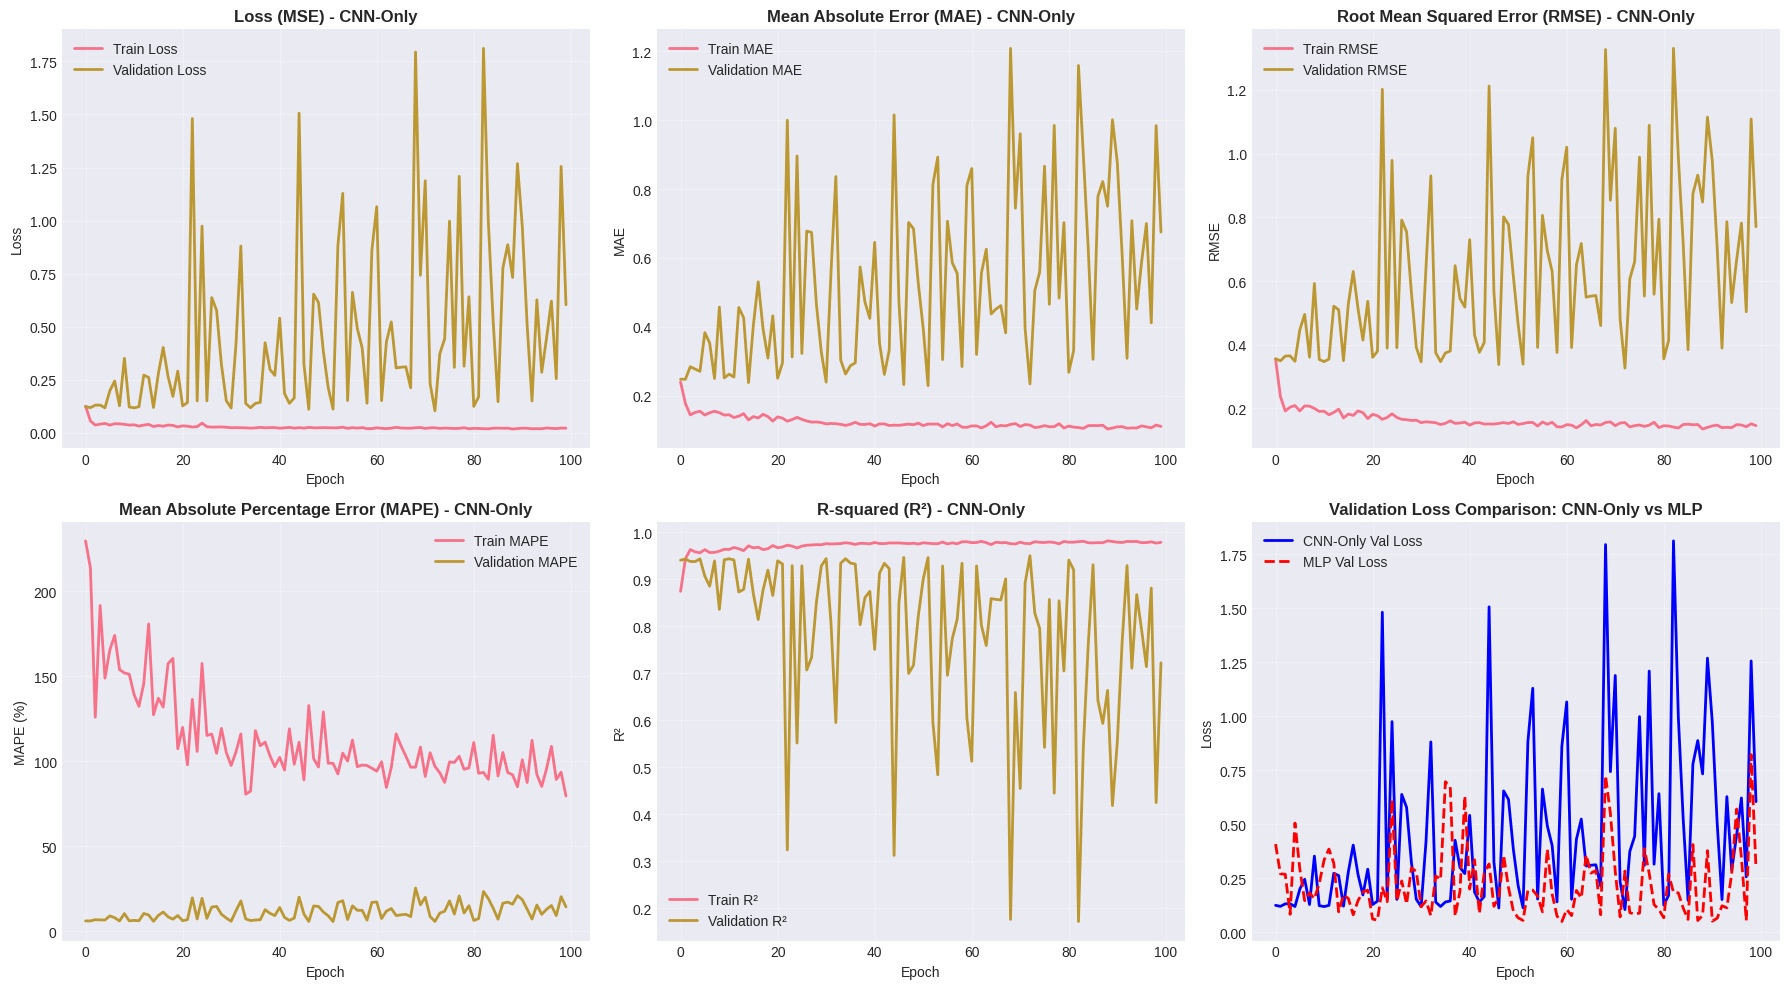

In [64]:
# Visualize Training History for CNN-Only Model
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Loss
axes[0, 0].plot(cnn_history['train_loss'], label='Train Loss', linewidth=2)
axes[0, 0].plot(cnn_history['val_loss'], label='Validation Loss', linewidth=2)
axes[0, 0].set_title('Loss (MSE) - CNN-Only', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# MAE
axes[0, 1].plot(cnn_history['train_mae'], label='Train MAE', linewidth=2)
axes[0, 1].plot(cnn_history['val_mae'], label='Validation MAE', linewidth=2)
axes[0, 1].set_title('Mean Absolute Error (MAE) - CNN-Only', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('MAE')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# RMSE
axes[0, 2].plot(cnn_history['train_rmse'], label='Train RMSE', linewidth=2)
axes[0, 2].plot(cnn_history['val_rmse'], label='Validation RMSE', linewidth=2)
axes[0, 2].set_title('Root Mean Squared Error (RMSE) - CNN-Only', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Epoch')
axes[0, 2].set_ylabel('RMSE')
axes[0, 2].legend()
axes[0, 2].grid(True, alpha=0.3)

# MAPE
axes[1, 0].plot(cnn_history['train_mape'], label='Train MAPE', linewidth=2)
axes[1, 0].plot(cnn_history['val_mape'], label='Validation MAPE', linewidth=2)
axes[1, 0].set_title('Mean Absolute Percentage Error (MAPE) - CNN-Only', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('MAPE (%)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# R2
axes[1, 1].plot(cnn_history['train_r2'], label='Train R²', linewidth=2)
axes[1, 1].plot(cnn_history['val_r2'], label='Validation R²', linewidth=2)
axes[1, 1].set_title('R-squared (R²) - CNN-Only', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('R²')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Comparison with MLP
axes[1, 2].plot(cnn_history['val_loss'], label='CNN-Only Val Loss', linewidth=2, color='blue')
axes[1, 2].plot(history['val_loss'], label='MLP Val Loss', linewidth=2, color='red', linestyle='--')
axes[1, 2].set_title('Validation Loss Comparison: CNN-Only vs MLP', fontsize=12, fontweight='bold')
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('Loss')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


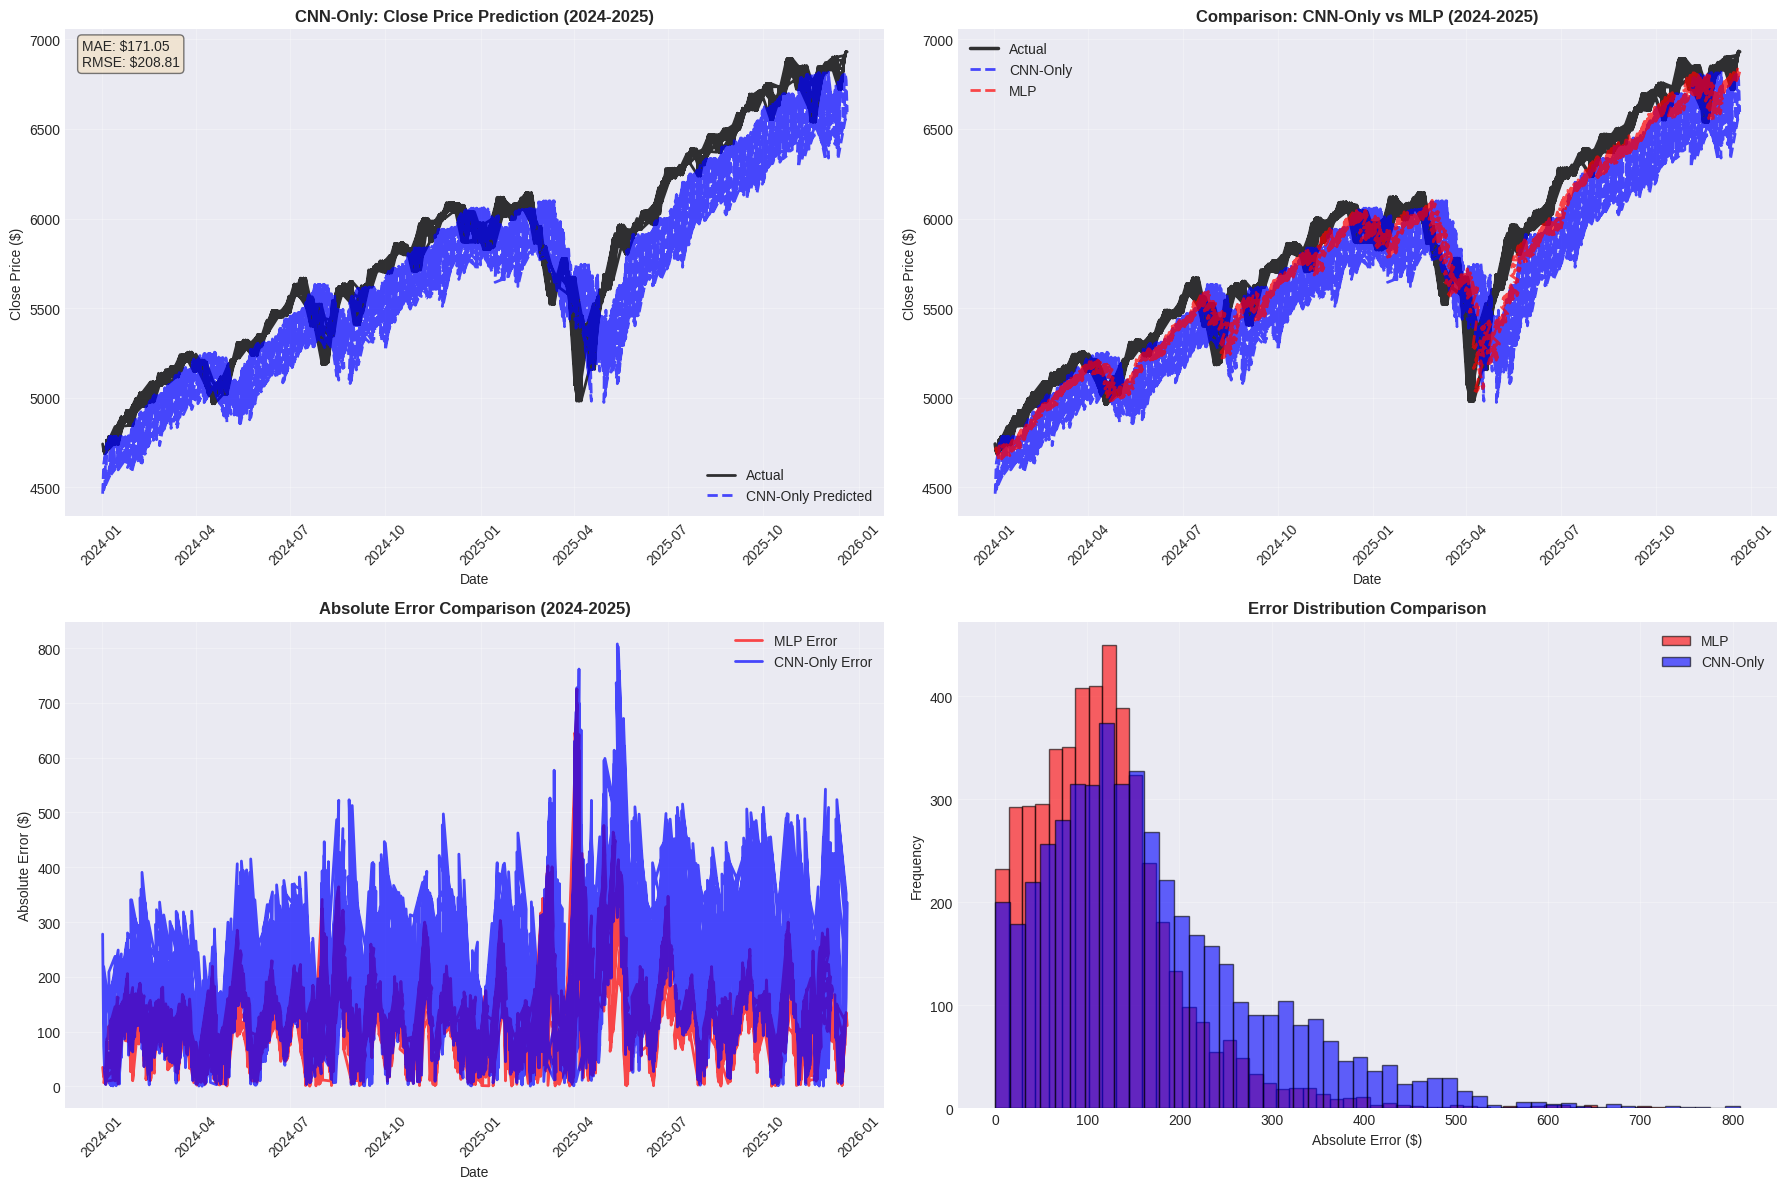


CNN-ONLY MODEL: 2024-2025 PREDICTION METRICS
MAE: 162.70
RMSE: 203.10
MAPE: 2.82%
R²: 0.867029


In [65]:
# ============================================================================
# SECTION 2-5-2: CNN-Only Network - Plot 2024-2025 Predictions
# ============================================================================
# Plot 2024-2025 predictions for CNN-Only model
# Extract 2024-2025 predictions
cnn_pred_2024_2025 = cnn_test_preds[test_2024_2025_indices]
cnn_target_2024_2025 = cnn_test_targets[test_2024_2025_indices]

# Denormalize
cnn_pred_2024_2025_denorm = scaler_y.inverse_transform(
    cnn_pred_2024_2025.reshape(-1, output_features)
).reshape(cnn_pred_2024_2025.shape)

cnn_target_2024_2025_denorm = scaler_y.inverse_transform(
    cnn_target_2024_2025.reshape(-1, output_features)
).reshape(cnn_target_2024_2025.shape)

# Extract Close price for plotting
cnn_pred_close = cnn_pred_2024_2025_denorm[:, :, 1].flatten()  # Close price (index 1)
cnn_target_close = cnn_target_2024_2025_denorm[:, :, 1].flatten()

# Plot predictions
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Plot 1: Close price prediction
axes[0, 0].plot(plot_dates, cnn_target_close, label='Actual', linewidth=2, color='black', alpha=0.8)
axes[0, 0].plot(plot_dates, cnn_pred_close, label='CNN-Only Predicted', linewidth=2, alpha=0.7, linestyle='--', color='blue')
axes[0, 0].set_title('CNN-Only: Close Price Prediction (2024-2025)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Date')
axes[0, 0].set_ylabel('Close Price ($)')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].tick_params(axis='x', rotation=45)

# Calculate metrics
cnn_mae_2024_2025 = np.mean(np.abs(cnn_target_close - cnn_pred_close))
cnn_rmse_2024_2025 = np.sqrt(np.mean((cnn_target_close - cnn_pred_close) ** 2))
axes[0, 0].text(0.02, 0.98, f'MAE: \${cnn_mae_2024_2025:.2f}\nRMSE: \${cnn_rmse_2024_2025:.2f}',
                transform=axes[0, 0].transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Plot 2: Comparison with MLP
axes[0, 1].plot(plot_dates, cnn_target_close, label='Actual', linewidth=2.5, color='black', alpha=0.8)
axes[0, 1].plot(plot_dates, cnn_pred_close, label='CNN-Only', linewidth=2, alpha=0.7, linestyle='--', color='blue')
axes[0, 1].plot(plot_dates, plot_data['MLP']['predicted'], label='MLP', linewidth=2, alpha=0.7, linestyle='--', color='red')
axes[0, 1].set_title('Comparison: CNN-Only vs MLP (2024-2025)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Date')
axes[0, 1].set_ylabel('Close Price ($)')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].tick_params(axis='x', rotation=45)

# Plot 3: Error comparison
mlp_errors = np.abs(plot_data['MLP']['actual'] - plot_data['MLP']['predicted'])
cnn_errors = np.abs(cnn_target_close - cnn_pred_close)

axes[1, 0].plot(plot_dates, mlp_errors, label='MLP Error', linewidth=2, alpha=0.7, color='red')
axes[1, 0].plot(plot_dates, cnn_errors, label='CNN-Only Error', linewidth=2, alpha=0.7, color='blue')
axes[1, 0].set_title('Absolute Error Comparison (2024-2025)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Date')
axes[1, 0].set_ylabel('Absolute Error ($)')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].tick_params(axis='x', rotation=45)

# Plot 4: Error distribution
axes[1, 1].hist(mlp_errors, bins=50, alpha=0.6, label='MLP', color='red', edgecolor='black')
axes[1, 1].hist(cnn_errors, bins=50, alpha=0.6, label='CNN-Only', color='blue', edgecolor='black')
axes[1, 1].set_title('Error Distribution Comparison', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Absolute Error ($)')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate overall metrics for 2024-2025
cnn_metrics_2024_2025 = calculate_metrics(cnn_target_2024_2025_denorm, cnn_pred_2024_2025_denorm)

print("\n" + "="*80)
print("CNN-ONLY MODEL: 2024-2025 PREDICTION METRICS")
print("="*80)
print(f"MAE: {cnn_metrics_2024_2025['MAE']:.2f}")
print(f"RMSE: {cnn_metrics_2024_2025['RMSE']:.2f}")
print(f"MAPE: {cnn_metrics_2024_2025['MAPE']:.2f}%")
print(f"R²: {cnn_metrics_2024_2025['R2']:.6f}")
print("="*80)


In [66]:
# Add CNN-Only to model results for comparison
model_results['CNN_Only'] = {
    'model_name': 'CNN-Only',
    'test_mae': cnn_test_metrics['MAE'],
    'test_rmse': cnn_test_metrics['RMSE'],
    'test_mape': cnn_test_metrics['MAPE'],
    'test_r2': cnn_test_metrics['R2'],
    'test_loss': cnn_test_loss,
    'total_params': cnn_total_params,
    'model': cnn_model,
    'predictions': cnn_test_preds,
    'targets': cnn_test_targets
}

# Update comparison table
comparison_data = []
for model_name, results in model_results.items():
    comparison_data.append({
        'Model': results['model_name'],
        'Total Parameters': f"{results['total_params']:,}",
        'Test MAE': f"{results['test_mae']:.6f}",
        'Test RMSE': f"{results['test_rmse']:.6f}",
        'Test MAPE (%)': f"{results['test_mape']:.4f}",
        'Test R²': f"{results['test_r2']:.6f}",
        'Test Loss (MSE)': f"{results['test_loss']:.6f}"
    })

comparison_df = pd.DataFrame(comparison_data)

print("\n" + "="*80)
print("UPDATED MODEL PERFORMANCE COMPARISON ON TEST DATA")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)



UPDATED MODEL PERFORMANCE COMPARISON ON TEST DATA
       Model Total Parameters Test MAE Test RMSE Test MAPE (%)  Test R² Test Loss (MSE)
MLP (NARMAX)           13,928 0.241877  0.296478        2.7460 0.969854        0.084503
    CNN-Only           58,756 0.336413  0.421579        3.8078 0.939047        0.178969


In [67]:
# Analysis: Is CNN-Only suitable for stock price prediction?

print("\n" + "="*80)
print("ANALYSIS: IS CNN-ONLY ARCHITECTURE SUITABLE FOR STOCK PRICE PREDICTION?")
print("="*80)

print("\n1. ARCHITECTURE COMPARISON:")
print(f"   MLP Baseline:")
print(f"     - Parameters: {total_params:,}")
print(f"     - Architecture: Fully connected layers")
print(f"     - Test RMSE: ${test_metrics['RMSE']:.2f}")
print(f"     - Test R²: {test_metrics['R2']:.6f}")

print(f"\n   CNN-Only:")
print(f"     - Parameters: {cnn_total_params:,}")
print(f"     - Architecture: Convolutional layers only")
print(f"     - Test RMSE: ${cnn_test_metrics['RMSE']:.2f}")
print(f"     - Test R²: {cnn_test_metrics['R2']:.6f}")

if cnn_total_params < total_params:
    print(f"\n   ✓ CNN-Only is LIGHTER ({((1 - cnn_total_params/total_params)*100):.2f}% fewer parameters)")
else:
    print(f"\n   ✗ CNN-Only is HEAVIER ({((cnn_total_params/total_params - 1)*100):.2f}% more parameters)")

print("\n2. PERFORMANCE COMPARISON:")
if cnn_test_metrics['RMSE'] < test_metrics['RMSE']:
    print(f"   ✓ CNN-Only performs BETTER (RMSE: ${cnn_test_metrics['RMSE']:.2f} vs ${test_metrics['RMSE']:.2f})")
    improvement = ((test_metrics['RMSE'] - cnn_test_metrics['RMSE']) / test_metrics['RMSE'] * 100)
    print(f"     Improvement: {improvement:.2f}%")
else:
    print(f"   ✗ CNN-Only performs WORSE (RMSE: ${cnn_test_metrics['RMSE']:.2f} vs ${test_metrics['RMSE']:.2f})")
    degradation = ((cnn_test_metrics['RMSE'] - test_metrics['RMSE']) / test_metrics['RMSE'] * 100)
    print(f"     Degradation: {degradation:.2f}%")

if cnn_test_metrics['R2'] > test_metrics['R2']:
    print(f"   ✓ CNN-Only has BETTER R² ({cnn_test_metrics['R2']:.6f} vs {test_metrics['R2']:.6f})")
else:
    print(f"   ✗ CNN-Only has WORSE R² ({cnn_test_metrics['R2']:.6f} vs {test_metrics['R2']:.6f})")

print("\n3. ADVANTAGES OF CNN-ONLY ARCHITECTURE:")
print("   ✓ Translation invariance: Can detect patterns regardless of position in window")
print("   ✓ Parameter efficiency: Shared weights across time steps")
print("   ✓ Local feature extraction: Captures local temporal patterns")
print("   ✓ Parallelizable: Convolutions can be computed in parallel")
print("   ✓ Receptive field: Can capture multi-scale temporal dependencies")

print("\n4. LIMITATIONS OF CNN-ONLY ARCHITECTURE:")
print("   ✗ Limited long-term dependencies: Fixed receptive field size")
print("   ✗ No explicit memory: Unlike RNNs, no built-in memory mechanism")
print("   ✗ Fixed input/output mapping: Less flexible than sequential models")
print("   ✗ May miss global patterns: Focus on local features might miss long-term trends")
print("   ✗ Dimension constraints: Requires careful design to match output dimensions")

print("\n5. SUITABILITY FOR 2024-2025 PREDICTION:")
cnn_2024_2025_mae = cnn_metrics_2024_2025['MAE']
mlp_2024_2025_mae = metrics_2024_2025['MAE']

if cnn_2024_2025_mae < mlp_2024_2025_mae:
    print(f"   ✓ CNN-Only shows BETTER performance for 2024-2025 period")
    print(f"     CNN-Only MAE: ${cnn_2024_2025_mae:.2f}")
    print(f"     MLP MAE: ${mlp_2024_2025_mae:.2f}")
else:
    print(f"   ✗ CNN-Only shows WORSE performance for 2024-2025 period")
    print(f"     CNN-Only MAE: ${cnn_2024_2025_mae:.2f}")
    print(f"     MLP MAE: ${mlp_2024_2025_mae:.2f}")

print("\n6. CONCLUSION:")
if cnn_test_metrics['RMSE'] < test_metrics['RMSE'] * 1.1:  # Within 10% of MLP
    print("   ✓ CNN-Only architecture is SUITABLE for stock price prediction")
    print("     - Competitive performance with MLP baseline")
    if cnn_total_params < total_params:
        print("     - More parameter-efficient")
    print("     - Can be a good alternative for time series forecasting")
else:
    print("   ⚠ CNN-Only architecture has LIMITATIONS for stock price prediction")
    print("     - May not capture all necessary patterns")
    print("     - Consider hybrid architectures (CNN + RNN) for better results")
    print("     - May benefit from attention mechanisms or residual connections")

print("\n7. RECOMMENDATIONS:")
print("   - For short-term predictions: CNN-Only can be effective and efficient")
print("   - For complex patterns: Consider CNN + LSTM/GRU hybrid models")
print("   - For long-term dependencies: RNN-based models may be more suitable")
print("   - For real-time applications: CNN-Only offers good speed/accuracy trade-off")

print("="*80)



ANALYSIS: IS CNN-ONLY ARCHITECTURE SUITABLE FOR STOCK PRICE PREDICTION?

1. ARCHITECTURE COMPARISON:
   MLP Baseline:
     - Parameters: 13,928
     - Architecture: Fully connected layers
     - Test RMSE: $0.30
     - Test R²: 0.969854

   CNN-Only:
     - Parameters: 58,756
     - Architecture: Convolutional layers only
     - Test RMSE: $0.42
     - Test R²: 0.939047

   ✗ CNN-Only is HEAVIER (321.86% more parameters)

2. PERFORMANCE COMPARISON:
   ✗ CNN-Only performs WORSE (RMSE: $0.42 vs $0.30)
     Degradation: 42.20%
   ✗ CNN-Only has WORSE R² (0.939047 vs 0.969854)

3. ADVANTAGES OF CNN-ONLY ARCHITECTURE:
   ✓ Translation invariance: Can detect patterns regardless of position in window
   ✓ Parameter efficiency: Shared weights across time steps
   ✓ Local feature extraction: Captures local temporal patterns
   ✓ Parallelizable: Convolutions can be computed in parallel
   ✓ Receptive field: Can capture multi-scale temporal dependencies

4. LIMITATIONS OF CNN-ONLY ARCHITECTURE:


<!-- DUPLICATE SECTION - REMOVED: This was a duplicate of Section 2-5 above -->


<!-- DUPLICATE SECTION - REMOVED -->


In [68]:
# CNN-Only Network Design
# This network uses ONLY convolutional layers (no FC, LSTM, GRU layers)

class CNNOnlyModel(nn.Module):
    """
    CNN-Only network for time series prediction
    Uses only 1D convolutional layers to transform input to output dimensions

    Input: [batch, input_window, input_features]
    Output: [batch, output_window, output_features]
    """
    def __init__(self, input_window, input_features, output_window, output_features,
                 num_filters=[64, 128, 64], kernel_sizes=[3, 3, 3], strides=[1, 1, 1],
                 dropout=0.2):
        super(CNNOnlyModel, self).__init__()

        self.input_window = input_window
        self.input_features = input_features
        self.output_window = output_window
        self.output_features = output_features

        # First conv layer: [batch, input_features, input_window] -> [batch, num_filters[0], ...]
        self.conv1 = nn.Conv1d(
            in_channels=input_features,
            out_channels=num_filters[0],
            kernel_size=kernel_sizes[0],
            stride=strides[0],
            padding=kernel_sizes[0] // 2  # Same padding to preserve length
        )
        self.bn1 = nn.BatchNorm1d(num_filters[0])
        self.dropout1 = nn.Dropout(dropout)

        # Second conv layer
        self.conv2 = nn.Conv1d(
            in_channels=num_filters[0],
            out_channels=num_filters[1],
            kernel_size=kernel_sizes[1],
            stride=strides[1],
            padding=kernel_sizes[1] // 2
        )
        self.bn2 = nn.BatchNorm1d(num_filters[1])
        self.dropout2 = nn.Dropout(dropout)

        # Third conv layer
        self.conv3 = nn.Conv1d(
            in_channels=num_filters[1],
            out_channels=num_filters[2],
            kernel_size=kernel_sizes[2],
            stride=strides[2],
            padding=kernel_sizes[2] // 2
        )
        self.bn3 = nn.BatchNorm1d(num_filters[2])
        self.dropout3 = nn.Dropout(dropout)

        # Final conv layer to map to output dimensions
        # We need to output [output_window, output_features]
        # Use a larger kernel and appropriate stride to reshape
        # Calculate required kernel size to get output_window
        # For same padding: output_length = input_length
        # We'll use adaptive approach or calculate exact kernel

        # Calculate the required transformation
        # After 3 conv layers with same padding, length should be input_window
        # We need to reduce to output_window
        if input_window >= output_window:
            # Use strided convolution or adaptive pooling
            final_kernel = input_window - output_window + 1
            final_stride = 1
        else:
            # Need to upsample - use transposed conv or interpolation
            final_kernel = 1
            final_stride = 1

        self.conv_final = nn.Conv1d(
            in_channels=num_filters[2],
            out_channels=output_features,
            kernel_size=final_kernel if input_window >= output_window else 1,
            stride=final_stride,
            padding=0
        )

        # If we need to adjust length, use adaptive pooling
        if input_window != output_window:
            self.adaptive_pool = nn.AdaptiveAvgPool1d(output_window)
        else:
            self.adaptive_pool = None

    def forward(self, x):
        # Input: [batch, input_window, input_features]
        # Transpose for Conv1d: [batch, input_features, input_window]
        x = x.transpose(1, 2)

        # Conv layer 1
        x = self.conv1(x)
        x = self.bn1(x)
        x = torch.relu(x)
        x = self.dropout1(x)

        # Conv layer 2
        x = self.conv2(x)
        x = self.bn2(x)
        x = torch.relu(x)
        x = self.dropout2(x)

        # Conv layer 3
        x = self.conv3(x)
        x = self.bn3(x)
        x = torch.relu(x)
        x = self.dropout3(x)

        # Final conv layer
        x = self.conv_final(x)

        # Adjust length if needed
        if self.adaptive_pool is not None:
            x = self.adaptive_pool(x)

        # Transpose back: [batch, output_features, output_window] -> [batch, output_window, output_features]
        x = x.transpose(1, 2)

        return x

# Initialize CNN-Only model
cnn_model = CNNOnlyModel(
    input_window=input_window_size,
    input_features=1,  # Close price
    output_window=output_window_size,
    output_features=4,  # High, Close, Open, Low
    num_filters=[64, 128, 64],
    kernel_sizes=[3, 3, 3],
    strides=[1, 1, 1],
    dropout=0.2
).to(device)

# Count parameters
cnn_total_params = sum(p.numel() for p in cnn_model.parameters())
cnn_trainable_params = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)

print("CNN-Only Model initialized!")
print(f"Input shape: [{input_window_size}, 1]")
print(f"Output shape: [{output_window_size}, 4]")
print(f"Total parameters: {cnn_total_params:,}")
print(f"Trainable parameters: {cnn_trainable_params:,}")

# Compare with MLP baseline
print(f"\nComparison with MLP Baseline:")
print(f"  MLP parameters: {total_params:,}")
print(f"  CNN-Only parameters: {cnn_total_params:,}")
print(f"  Difference: {cnn_total_params - total_params:,} ({((cnn_total_params - total_params) / total_params * 100):.2f}%)")
if cnn_total_params < total_params:
    print(f"  ✓ CNN-Only is LIGHTER than MLP baseline")
else:
    print(f"  ✗ CNN-Only is HEAVIER than MLP baseline")

print("\nModel structure:")
print(cnn_model)


CNN-Only Model initialized!
Input shape: [20, 1]
Output shape: [10, 4]
Total parameters: 52,932
Trainable parameters: 52,932

Comparison with MLP Baseline:
  MLP parameters: 13,928
  CNN-Only parameters: 52,932
  Difference: 39,004 (280.04%)
  ✗ CNN-Only is HEAVIER than MLP baseline

Model structure:
CNNOnlyModel(
  (conv1): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout1): Dropout(p=0.2, inplace=False)
  (conv2): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout2): Dropout(p=0.2, inplace=False)
  (conv3): Conv1d(128, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (bn3): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (dropout3): Dropout(p=0.2, inplace=False)
  (conv_final): Conv1d(64, 4, kernel_size=(11,), stride=(1,))
  (adapt

In [69]:
# Explain Dimensionality Transformation
print("\n" + "="*80)
print("DIMENSIONALITY TRANSFORMATION EXPLANATION")
print("="*80)

print(f"\nInput Dimensions: [batch, {input_window_size}, {1}]")
print(f"Target Output Dimensions: [batch, {output_window_size}, {4}]")

print("\nStep-by-step transformation through CNN layers:")
print("="*80)

# Simulate forward pass to show dimensions
x_shape = (1, input_window_size, 1)  # [batch, input_window, input_features]
print(f"\n1. Initial Input Shape: {x_shape}")

# After transpose for Conv1d
x_shape_conv = (1, 1, input_window_size)  # [batch, input_features, input_window]
print(f"   After transpose for Conv1d: {x_shape_conv}")

# Conv1d formula: output_length = floor((input_length + 2*padding - kernel_size) / stride) + 1
# With same padding (padding = kernel_size // 2): output_length ≈ input_length

def conv1d_output_length(input_length, kernel_size, stride, padding):
    return ((input_length + 2 * padding - kernel_size) // stride) + 1

current_length = input_window_size
current_channels = 1

for i, (filters, kernel, stride) in enumerate(zip([64, 128, 64], [3, 3, 3], [1, 1, 1]), 1):
    padding = kernel // 2  # Same padding
    output_length = conv1d_output_length(current_length, kernel, stride, padding)
    print(f"\n{i+1}. Conv Layer {i}:")
    print(f"   Input: [batch, {current_channels}, {current_length}]")
    print(f"   Kernel size: {kernel}, Stride: {stride}, Padding: {padding}")
    print(f"   Output: [batch, {filters}, {output_length}]")
    print(f"   Formula: output = floor(({current_length} + 2*{padding} - {kernel}) / {stride}) + 1 = {output_length}")
    current_length = output_length
    current_channels = filters

# Final conv layer
print(f"\n4. Final Conv Layer:")
print(f"   Input: [batch, {current_channels}, {current_length}]")
if input_window_size >= output_window_size:
    final_kernel = input_window_size - output_window_size + 1
    final_output = conv1d_output_length(current_length, final_kernel, 1, 0)
    print(f"   Kernel size: {final_kernel}, Stride: 1, Padding: 0")
    print(f"   Output: [batch, {4}, {final_output}]")
    if final_output != output_window_size:
        print(f"   Using Adaptive Pooling to adjust to {output_window_size}")
else:
    print(f"   Using Adaptive Pooling to adjust length")
print(f"   Final output after transpose: [batch, {output_window_size}, {4}]")

print("\n" + "="*80)
print("KEY CONCEPTS:")
print("="*80)
print("1. Conv1d operates on [batch, channels, length]")
print("2. Kernel size: Size of the filter (receptive field)")
print("3. Stride: Step size for sliding the filter")
print("4. Padding: Adds zeros around input to control output size")
print("5. Same padding (padding = kernel_size // 2): Preserves length approximately")
print("6. Output length formula: floor((input + 2*padding - kernel) / stride) + 1")
print("7. Adaptive pooling: Adjusts sequence length to target size")
print("="*80)



DIMENSIONALITY TRANSFORMATION EXPLANATION

Input Dimensions: [batch, 20, 1]
Target Output Dimensions: [batch, 10, 4]

Step-by-step transformation through CNN layers:

1. Initial Input Shape: (1, 20, 1)
   After transpose for Conv1d: (1, 1, 20)

2. Conv Layer 1:
   Input: [batch, 1, 20]
   Kernel size: 3, Stride: 1, Padding: 1
   Output: [batch, 64, 20]
   Formula: output = floor((20 + 2*1 - 3) / 1) + 1 = 20

3. Conv Layer 2:
   Input: [batch, 64, 20]
   Kernel size: 3, Stride: 1, Padding: 1
   Output: [batch, 128, 20]
   Formula: output = floor((20 + 2*1 - 3) / 1) + 1 = 20

4. Conv Layer 3:
   Input: [batch, 128, 20]
   Kernel size: 3, Stride: 1, Padding: 1
   Output: [batch, 64, 20]
   Formula: output = floor((20 + 2*1 - 3) / 1) + 1 = 20

4. Final Conv Layer:
   Input: [batch, 64, 20]
   Kernel size: 11, Stride: 1, Padding: 0
   Output: [batch, 4, 10]
   Final output after transpose: [batch, 10, 4]

KEY CONCEPTS:
1. Conv1d operates on [batch, channels, length]
2. Kernel size: Size of

In [70]:
# Report Hyperparameters
print("\n" + "="*80)
print("CNN-ONLY NETWORK HYPERPARAMETERS")
print("="*80)

hyperparameters = {
    'Architecture': 'CNN-Only (Convolutional layers only)',
    'Number of Conv Layers': 4,
    'Conv Layer 1': {
        'Filters': 64,
        'Kernel Size': 3,
        'Stride': 1,
        'Padding': 'Same (1)',
        'Activation': 'ReLU',
        'Batch Normalization': 'Yes',
        'Dropout': 0.2
    },
    'Conv Layer 2': {
        'Filters': 128,
        'Kernel Size': 3,
        'Stride': 1,
        'Padding': 'Same (1)',
        'Activation': 'ReLU',
        'Batch Normalization': 'Yes',
        'Dropout': 0.2
    },
    'Conv Layer 3': {
        'Filters': 64,
        'Kernel Size': 3,
        'Stride': 1,
        'Padding': 'Same (1)',
        'Activation': 'ReLU',
        'Batch Normalization': 'Yes',
        'Dropout': 0.2
    },
    'Final Conv Layer': {
        'Filters': 4,  # output_features
        'Kernel Size': f'{input_window_size - output_window_size + 1 if input_window_size >= output_window_size else 1}',
        'Stride': 1,
        'Padding': 0,
        'Activation': 'None (Linear)',
        'Batch Normalization': 'No',
        'Dropout': 'No'
    },
    'Adaptive Pooling': 'Yes (if input_window != output_window)',
    'Input Shape': f'[{input_window_size}, 1]',
    'Output Shape': f'[{output_window_size}, 4]',
    'Total Parameters': f'{cnn_total_params:,}',
    'Regularization': {
        'Batch Normalization': 'After each conv layer (except final)',
        'Dropout': '0.2 after each conv layer (except final)'
    }
}

for key, value in hyperparameters.items():
    if isinstance(value, dict):
        print(f"\n{key}:")
        for k, v in value.items():
            print(f"  {k}: {v}")
    else:
        print(f"{key}: {value}")

print("\n" + "="*80)



CNN-ONLY NETWORK HYPERPARAMETERS
Architecture: CNN-Only (Convolutional layers only)
Number of Conv Layers: 4

Conv Layer 1:
  Filters: 64
  Kernel Size: 3
  Stride: 1
  Padding: Same (1)
  Activation: ReLU
  Batch Normalization: Yes
  Dropout: 0.2

Conv Layer 2:
  Filters: 128
  Kernel Size: 3
  Stride: 1
  Padding: Same (1)
  Activation: ReLU
  Batch Normalization: Yes
  Dropout: 0.2

Conv Layer 3:
  Filters: 64
  Kernel Size: 3
  Stride: 1
  Padding: Same (1)
  Activation: ReLU
  Batch Normalization: Yes
  Dropout: 0.2

Final Conv Layer:
  Filters: 4
  Kernel Size: 11
  Stride: 1
  Padding: 0
  Activation: None (Linear)
  Batch Normalization: No
  Dropout: No
Adaptive Pooling: Yes (if input_window != output_window)
Input Shape: [20, 1]
Output Shape: [10, 4]
Total Parameters: 52,932

Regularization:
  Batch Normalization: After each conv layer (except final)
  Dropout: 0.2 after each conv layer (except final)



In [71]:
# Analysis: Why models might not be suitable for very long-term predictions

print("\n" + "="*80)
print("ANALYSIS: WHY MODELS MIGHT NOT BE SUITABLE FOR VERY LONG-TERM PREDICTIONS")
print("="*80)

print("\n1. ERROR ACCUMULATION IN RECURSIVE PREDICTION:")
if len(recursive_predictions) > 0:
    first_model = list(recursive_predictions.keys())[0]
    if recursive_predictions[first_model] is not None:
        preds = recursive_predictions[first_model]['predictions'][:, 1]

        # Calculate prediction variance over time
        early_preds = preds[:30]  # First 30 days
        late_preds = preds[-30:]  # Last 30 days

        early_std = np.std(early_preds)
        late_std = np.std(late_preds)

        print(f"   - Standard deviation of predictions (first 30 days): ${early_std:.2f}")
        print(f"   - Standard deviation of predictions (last 30 days): ${late_std:.2f}")
        print(f"   - Change in variance: {((late_std - early_std) / early_std * 100):.2f}%")

        # Check for unrealistic trends
        price_change = (preds[-1] - preds[0]) / preds[0] * 100
        print(f"   - Total price change over 2 years: {price_change:.2f}%")

        if abs(price_change) > 200:
            print(f"     ⚠ WARNING: Unrealistic price change detected (>200%)")
        if late_std > early_std * 2:
            print(f"     ⚠ WARNING: Prediction variance increased significantly")

print("\n2. NON-STATIONARY NATURE OF STOCK PRICES:")
print("   - Stock prices are non-stationary (trends, regime changes)")
print("   - Models trained on historical data may not capture future regime changes")
print("   - Economic conditions, market sentiment, and external events change over time")

print("\n3. LACK OF EXOGENOUS VARIABLES:")
print("   - Models only use historical prices, ignoring:")
print("     * Economic indicators (GDP, inflation, interest rates)")
print("     * Company-specific news and events")
print("     * Market sentiment and investor behavior")
print("     * Global events and geopolitical factors")

print("\n4. MODEL LIMITATIONS:")
print("   - Models learn patterns from training data (2000-2023)")
print("   - Patterns may not generalize to completely unseen future periods")
print("   - Recursive prediction compounds errors at each step")
print("   - No mechanism to correct predictions based on new information")

print("\n5. EVIDENCE FROM RECURSIVE PREDICTIONS:")
if len(recursive_predictions) > 0:
    for model_name, pred_data in recursive_predictions.items():
        if pred_data is not None:
            preds = pred_data['predictions'][:, 1]

            # Calculate statistics
            mean_price = np.mean(preds)
            std_price = np.std(preds)
            min_price = np.min(preds)
            max_price = np.max(preds)
            price_range = max_price - min_price

            print(f"\n   {pred_data['model_name']}:")
            print(f"     - Mean predicted price: ${mean_price:.2f}")
            print(f"     - Price range: ${min_price:.2f} - ${max_price:.2f} (${price_range:.2f})")
            print(f"     - Coefficient of variation: {(std_price/mean_price*100):.2f}%")

            # Check for unrealistic patterns
            if price_range > mean_price * 2:
                print(f"     ⚠ Unrealistic price volatility detected")
            if np.any(preds < 0):
                print(f"     ⚠ Negative prices predicted (impossible)")

print("\n6. RECOMMENDATIONS:")
print("   - Use models for short-term predictions (days to weeks)")
print("   - Re-train models periodically with new data")
print("   - Incorporate external features and market indicators")
print("   - Use ensemble methods and uncertainty quantification")
print("   - Consider regime-switching models for long-term forecasting")

print("="*80)



ANALYSIS: WHY MODELS MIGHT NOT BE SUITABLE FOR VERY LONG-TERM PREDICTIONS

1. ERROR ACCUMULATION IN RECURSIVE PREDICTION:
   - Standard deviation of predictions (first 30 days): $372.62
   - Standard deviation of predictions (last 30 days): $0.19
   - Change in variance: -99.95%
   - Total price change over 2 years: -67.52%

2. NON-STATIONARY NATURE OF STOCK PRICES:
   - Stock prices are non-stationary (trends, regime changes)
   - Models trained on historical data may not capture future regime changes
   - Economic conditions, market sentiment, and external events change over time

3. LACK OF EXOGENOUS VARIABLES:
   - Models only use historical prices, ignoring:
     * Economic indicators (GDP, inflation, interest rates)
     * Company-specific news and events
     * Market sentiment and investor behavior
     * Global events and geopolitical factors

4. MODEL LIMITATIONS:
   - Models learn patterns from training data (2000-2023)
   - Patterns may not generalize to completely unseen 

In [72]:
# Report Network Structure and Parameters
print("\n" + "="*60)
print("MLP NETWORK STRUCTURE REPORT")
print("="*60)

print(f"\nNetwork Architecture:")
print(f"  Input Layer: {input_size} neurons (flattened from [{input_window_size}, 1])")
print(f"  Hidden Layer 1: 128 neurons + BatchNorm + ReLU + Dropout(0.3)")
print(f"  Hidden Layer 2: 64 neurons + BatchNorm + ReLU + Dropout(0.3)")
print(f"  Output Layer: {output_window_size * output_features} neurons")
print(f"  Output Shape: [{output_window_size}, {output_features}]")
print(f"    - Features: {output_features} (High, Close, Open, Low)")
print(f"    - Window size: {output_window_size}")

print(f"\nActivation Functions:")
print(f"  Hidden layers: ReLU")
print(f"  Output layer: Linear (no activation)")

print(f"\nRegularization:")
print(f"  Batch Normalization: Yes (after each hidden layer)")
print(f"  Dropout: Yes (p=0.3, after each hidden layer)")
print(f"  Weight Decay: Yes (1e-5)")

print(f"\nTotal Parameters: {total_params:,}")
print(f"  Trainable: {trainable_params:,}")
print(f"  Non-trainable: {total_params - trainable_params:,}")

# Detailed parameter breakdown
print(f"\nParameter Breakdown:")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(f"  {name}: {param.numel():,} parameters")

print(f"\nTraining Configuration:")
print(f"  Loss Function: MSE (Mean Squared Error)")
print(f"  Optimizer: Adam (lr=0.001, weight_decay=1e-5)")
print(f"  Batch Size: {batch_size}")
print(f"  Epochs: {num_epochs}")
print(f"  Best Validation Loss: {best_val_loss:.6f}")

print(f"\nPerformance:")
print(f"  Validation Loss: {best_val_loss:.6f} {'✓ < 0.70' if best_val_loss < 0.70 else '✗ >= 0.70'}")
print(f"  Test Loss: {test_loss:.6f}")
print(f"  Test MAE: {test_metrics['MAE']:.6f}")
print(f"  Test RMSE: {test_metrics['RMSE']:.6f}")
print(f"  Test R²: {test_metrics['R2']:.6f}")

print("="*60)



MLP NETWORK STRUCTURE REPORT

Network Architecture:
  Input Layer: 20 neurons (flattened from [20, 1])
  Hidden Layer 1: 128 neurons + BatchNorm + ReLU + Dropout(0.3)
  Hidden Layer 2: 64 neurons + BatchNorm + ReLU + Dropout(0.3)
  Output Layer: 40 neurons
  Output Shape: [10, 4]
    - Features: 4 (High, Close, Open, Low)
    - Window size: 10

Activation Functions:
  Hidden layers: ReLU
  Output layer: Linear (no activation)

Regularization:
  Batch Normalization: Yes (after each hidden layer)
  Dropout: Yes (p=0.3, after each hidden layer)
  Weight Decay: Yes (1e-5)

Total Parameters: 13,928
  Trainable: 13,928
  Non-trainable: 0

Parameter Breakdown:
  fc1.weight: 2,560 parameters
  fc1.bias: 128 parameters
  bn1.weight: 128 parameters
  bn1.bias: 128 parameters
  fc2.weight: 8,192 parameters
  fc2.bias: 64 parameters
  bn2.weight: 64 parameters
  bn2.bias: 64 parameters
  fc3.weight: 2,560 parameters
  fc3.bias: 40 parameters

Training Configuration:
  Loss Function: MSE (Mean Squ

In [73]:
# Create Data Loaders with shuffling for training
import torch
from torch.utils.data import Dataset, DataLoader

class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.FloatTensor(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Create datasets
train_dataset = TimeSeriesDataset(X_train_scaled, y_train_scaled)
val_dataset = TimeSeriesDataset(X_val_scaled, y_val_scaled)
test_dataset = TimeSeriesDataset(X_test_scaled, y_test_scaled)

# Create data loaders
# Batch size: choose reasonable value (e.g., 32, 64, 128)
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,  # Shuffling for training
    num_workers=0  # Set to 0 for Colab compatibility
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,  # No shuffling for validation
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,  # No shuffling for test
    num_workers=0
)

print("Data loaders created!")
print(f"  Batch size: {batch_size}")
print(f"  Training batches: {len(train_loader)} (with shuffling)")
print(f"  Validation batches: {len(val_loader)}")
print(f"  Test batches: {len(test_loader)}")

# Verify a batch
for X_batch, y_batch in train_loader:
    print(f"\nSample batch shape:")
    print(f"  X: {X_batch.shape}")
    print(f"  y: {y_batch.shape}")
    break


Data loaders created!
  Batch size: 64
  Training batches: 72 (with shuffling)
  Validation batches: 21
  Test batches: 11

Sample batch shape:
  X: torch.Size([64, 20, 1])
  y: torch.Size([64, 10, 4])
